In [1]:
import math
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error, mutual_info_score
from sklearn.feature_selection import mutual_info_regression
import glob 
import json
import numpy as np 
import fnmatch
import itertools 
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
import re
import matplotlib.patches as mpatches
from scipy.stats import norm

type_label = {'DMSO':'DMSO','Crizo':'Crizo(Ia)','NVP':'NVP(Ib)','Mere':'Mere(II)','Cabo':'Cabo(II)','Camp':'Cap(Ia)','Gle':'Gle(II)','Glu':'Glu(Ia)','Savo':'Savo(Ib)','Tepo':'Tepo(Ia)','Tiv':'Tiv(III)','A458':'A458(I$\\frac{1}{2}$)'}


/tmp/ipykernel_3104341/2752811750.py:2: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.3.0)
  from scipy.stats import pearsonr, spearmanr


In [ ]:
df = pd.read_csv('../MET_unfiltered.csv').copy()
dmso_df = df[df['key'] == 'DMSO'].copy()

with open(f'../../gnn-esm/clean/MET.json') as f:
    wt_seq = json.load(f)['seq']


In [3]:
metrics = {}
models1 = {
          'ESM2_full':'ESM2-650M',
          'ESM23B_full':'ESM2-3B',
          'ESMC6B_full':'ESMC-6B',
          'ESM3_full':'ESM3(seq-only)',
          'ESM3_struct_full':'ESM3(seq+struct)',
          'ISM_full':'ISM',
          'ProSST_full':'ProSST',
          'venusREM_full':'VenusREM',
          'SaProt_full':'SaProt',
          'ProtLigand_full':'ProtLigand',
          'PoET_full':'PoET',
          'ProteinMPNN_full':'ProteinMPNN',
          'LigandMPNN_full':'LigandMPNN',
          'LASErMPNN_full':'LASErMPNN',
          'ThermoMPNN_full':'ThermoMPNN',
          'PottsMPNN_full':'PottsMPNN',
        }

models = {
          'ESM23B':'ESM2-3B',
          'ESMC6B':'ESMC-6B',
          'venusREM':'VenusREM',
          'SaProt':'SaProt',
          'ProtLigand':'ProtLigand',
          'PoET':'PoET',
          'ProteinMPNN':'ProteinMPNN',
          'LigandMPNN':'LigandMPNN',
          'LASErMPNN':'LASErMPNN',
          'ThermoMPNN':'ThermoMPNN',
          'ProteinEBM':'ProteinEBM',
        }

influences = {}
neg_pred = {}

for model_name in models:

    fig, axs = plt.subplots(3,4, figsize=(15,8), layout='constrained')
    key_metrics = {}
    for ii, lname in enumerate(df['key'].unique()):

        key_df = df[df['key'].isin([lname])]   

        # sort by variant in key_df and dmso_df to make sure they are aligned
        model_outputs = key_df[f'{model_name}_mut'].values
        experiment_outputs = key_df['mean'].values

        pcc = abs(spearmanr(experiment_outputs, model_outputs)[0])
        mi = mutual_info_regression(np.array(model_outputs).reshape(-1,1), experiment_outputs)[0]
        mse = mean_squared_error(experiment_outputs, model_outputs)

        key_metrics[lname] = pcc

        ax = axs[ii // 4, ii % 4]
        ax.scatter(experiment_outputs, model_outputs, label = f'$\\rho$={pcc:.03f}', alpha=0.2)
        # add linear fit line
        m, b = np.polyfit(experiment_outputs, model_outputs, 1)
        ax.plot(experiment_outputs, m*np.array(experiment_outputs) + b, color='red')
        ax.set_title(f'{lname}')
        ax.legend()

        del model_outputs
    plt.close()
    plt.suptitle(f'{model_name}')
    metrics[f'{model_name}'] = key_metrics


<Figure size 640x480 with 0 Axes>

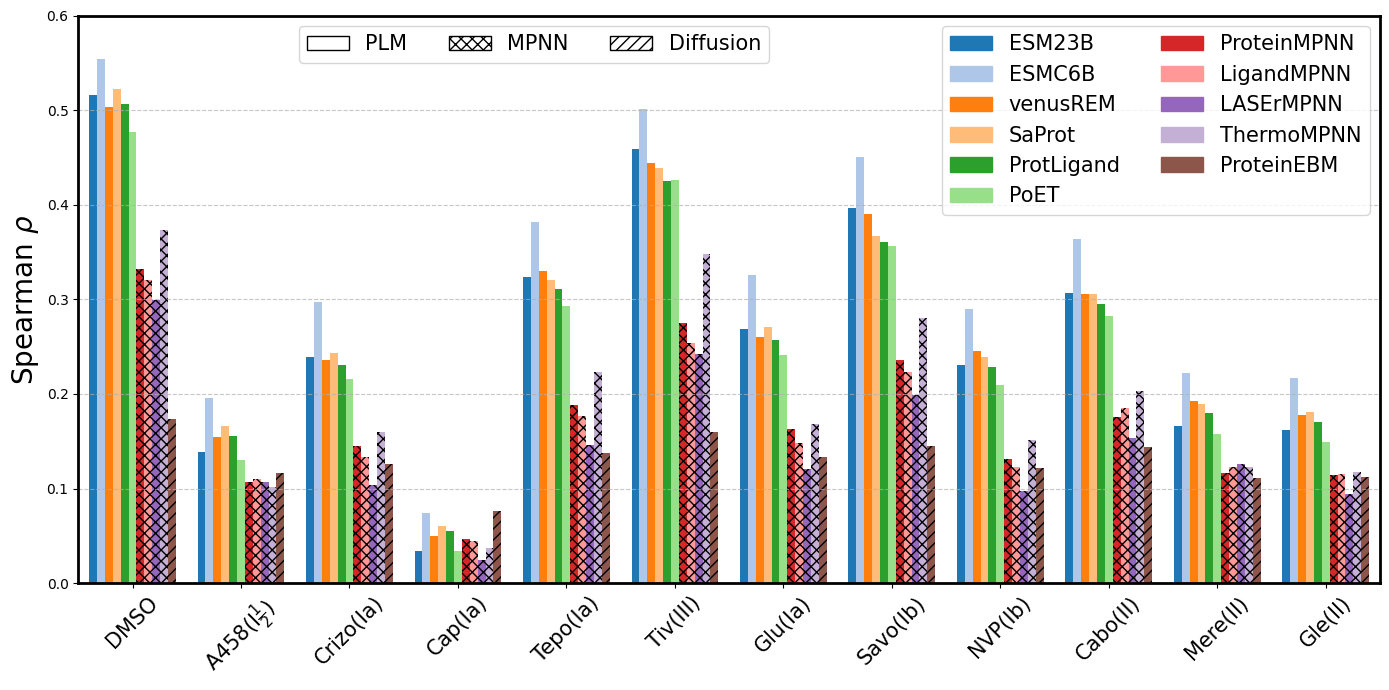

In [5]:
categories = list(next(iter(metrics.values())).keys())  # 12 categories
groups = list(metrics.keys())  # 3 groups

x = np.arange(len(categories))  # X positions for categories
total_width = 0.8               # Total width reserved for all bars in a category
bar_width = total_width / len(groups)  # Individual bar width

# Plotting Pearson's correlation bar plot
fig, ax = plt.subplots(figsize=(14, 7))

colors = sns.color_palette('tab20', n_colors=len(groups))
for i, group in enumerate(groups):
    values = [metrics[group][cat] for cat in categories]
    offset = (i - len(groups)/2) * bar_width + bar_width/2  # Center the group
    if group in ['ProteinMPNN', 'LigandMPNN', 'LASErMPNN', 'ThermoMPNN', 'PottsMPNN']:
        h = 'xxx'
    elif group in ['ProteinEBM']:
        h = '///'
    else:
        h = ''
    ax.bar(x + offset, values, width=bar_width, label=group, color=colors[i], hatch=h)

# Labels and legend
ax.set_xticks(x)
ax.set_xticklabels([f'{type_label[c]}' for c in categories], rotation=45, size=15)
color_legend = [mpatches.Patch(color=colors[i], label=group) for i, group in enumerate(groups)]

ax.set_ylabel("Spearman $\\rho$", size=20)
legend1 = ax.legend(handles=color_legend, fontsize=15, ncol=2)
ax.add_artist(legend1)

# add hatch legend as secondary legend
hatch_legend = [
    mpatches.Patch(facecolor='white', edgecolor='black', label='PLM'),
    mpatches.Patch(facecolor='white', edgecolor='black', hatch='xxx', label='MPNN'),
    mpatches.Patch(facecolor='white', edgecolor='black', hatch='///', label='Diffusion'),
]
ax.legend(handles=hatch_legend, fontsize=15, loc='upper center', bbox_to_anchor=(0.35, 1.0), ncol=3)

plt.ylim(0,0.6)
ax.set_xlim(-0.5,11.5)
for sp in ax.spines.values():
    sp.set_linewidth(2)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


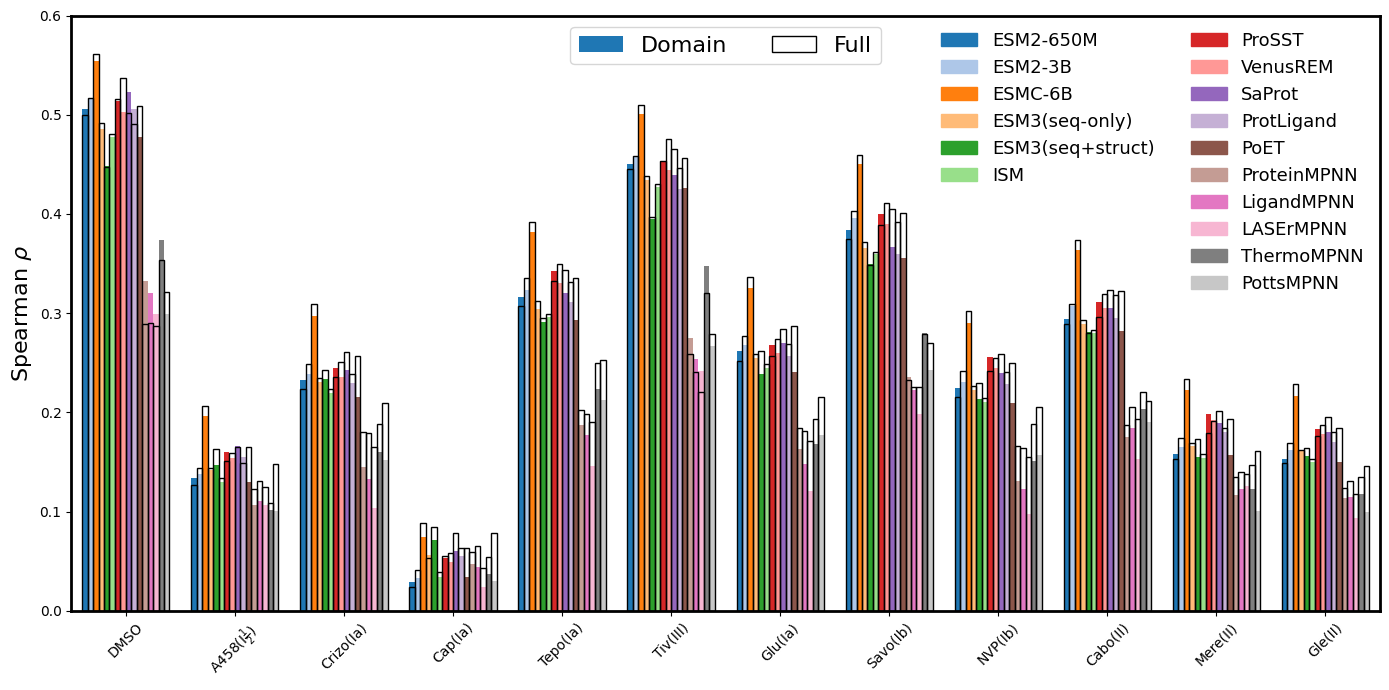

In [23]:
def uneven_legend(ax, handles, counts, labels=None, **kw):
    """Lay handles out in columns of the given sizes (matplotlib fills column-major).

    Pads BOTH handles and labels, so it works with handles that carry no label
    of their own (e.g. plt.Rectangle) as well as pre-labelled Patch objects.
    """
    assert sum(counts) == len(handles), (sum(counts), len(handles))
    if labels is None:
        labels = [h.get_label() for h in handles]
    assert len(labels) == len(handles), (len(labels), len(handles))
    nrow = max(counts)
    out_h, out_l, i = [], [], 0
    for c in counts:
        pad = nrow - c
        out_h += list(handles[i:i+c]) + [mpatches.Patch(alpha=0, linewidth=0)
                                         for _ in range(pad)]
        out_l += list(labels[i:i+c]) + [''] * pad
        i += c
    return ax.legend(out_h, out_l, ncol=len(counts), **kw)

categories = list(next(iter(metrics.values())).keys())  # 12 categories
model1_names = list(models1.keys())
model2_names = list(models2.keys())
model1_labels = list(models1.values())
model2_labels = list(models2.values())

x = np.arange(len(categories))
bar_width = 0.8 / len(model1_names)  # Make bars thinner to fit all

fig, ax = plt.subplots(figsize=(14, 7))

bars1_list = []
bars2_list = []
for i, (m1, m2) in enumerate(zip(model1_names, model2_names)):
    vals1 = [metrics[m1][cat] for cat in categories]
    vals2 = [metrics[m2][cat] for cat in categories]
    xpos = x + (i - len(model1_names)/2) * bar_width + bar_width/2

    # Color bar (background, no edge)
    bars1 = ax.bar(xpos, vals2, width=bar_width, 
                   color=plt.cm.tab20(i), edgecolor='none', zorder=1)
    # Black-edged bar (domain, transparent face)
    bars2 = ax.bar(xpos, vals1, width=bar_width, 
                   fill=False, edgecolor='black', linewidth=1, zorder=2)
    if i == 0:
        bars1_list.append(bars1)
        bars2_list.append(bars2)

# First legend: bar style (full/domain)

# legend 1 on top flattened no frame
legend1 = ax.legend(
    [bars1_list[0], bars2_list[0]], 
    ['Domain', 'Full'],
    loc='upper center', fontsize=16, frameon=True, ncol=2
)
ax.add_artist(legend1)

# Second legend: model names (use models1 for labels)
legend2 = uneven_legend(
    ax,
    [plt.Rectangle((0,0),1,1, color=plt.cm.tab20(i)) for i in range(len(model1_names))],
    [6, 10],
    labels=model1_labels,
    loc='upper right', fontsize=13, frameon=False,
)

ax.set_ylim(0, 0.6)
ax.set_xticks(x)
ax.set_xticklabels([f'{type_label[c]}' for c in categories], rotation=45, ha='center')
ax.set_ylabel("Spearman $\\rho$", size=16)
ax.set_xlim(-0.5, len(categories)-0.5)

# set ax spines linewidth to 2
for sp in ax.spines.values():
    sp.set_linewidth(2)
plt.tight_layout()
plt.show()


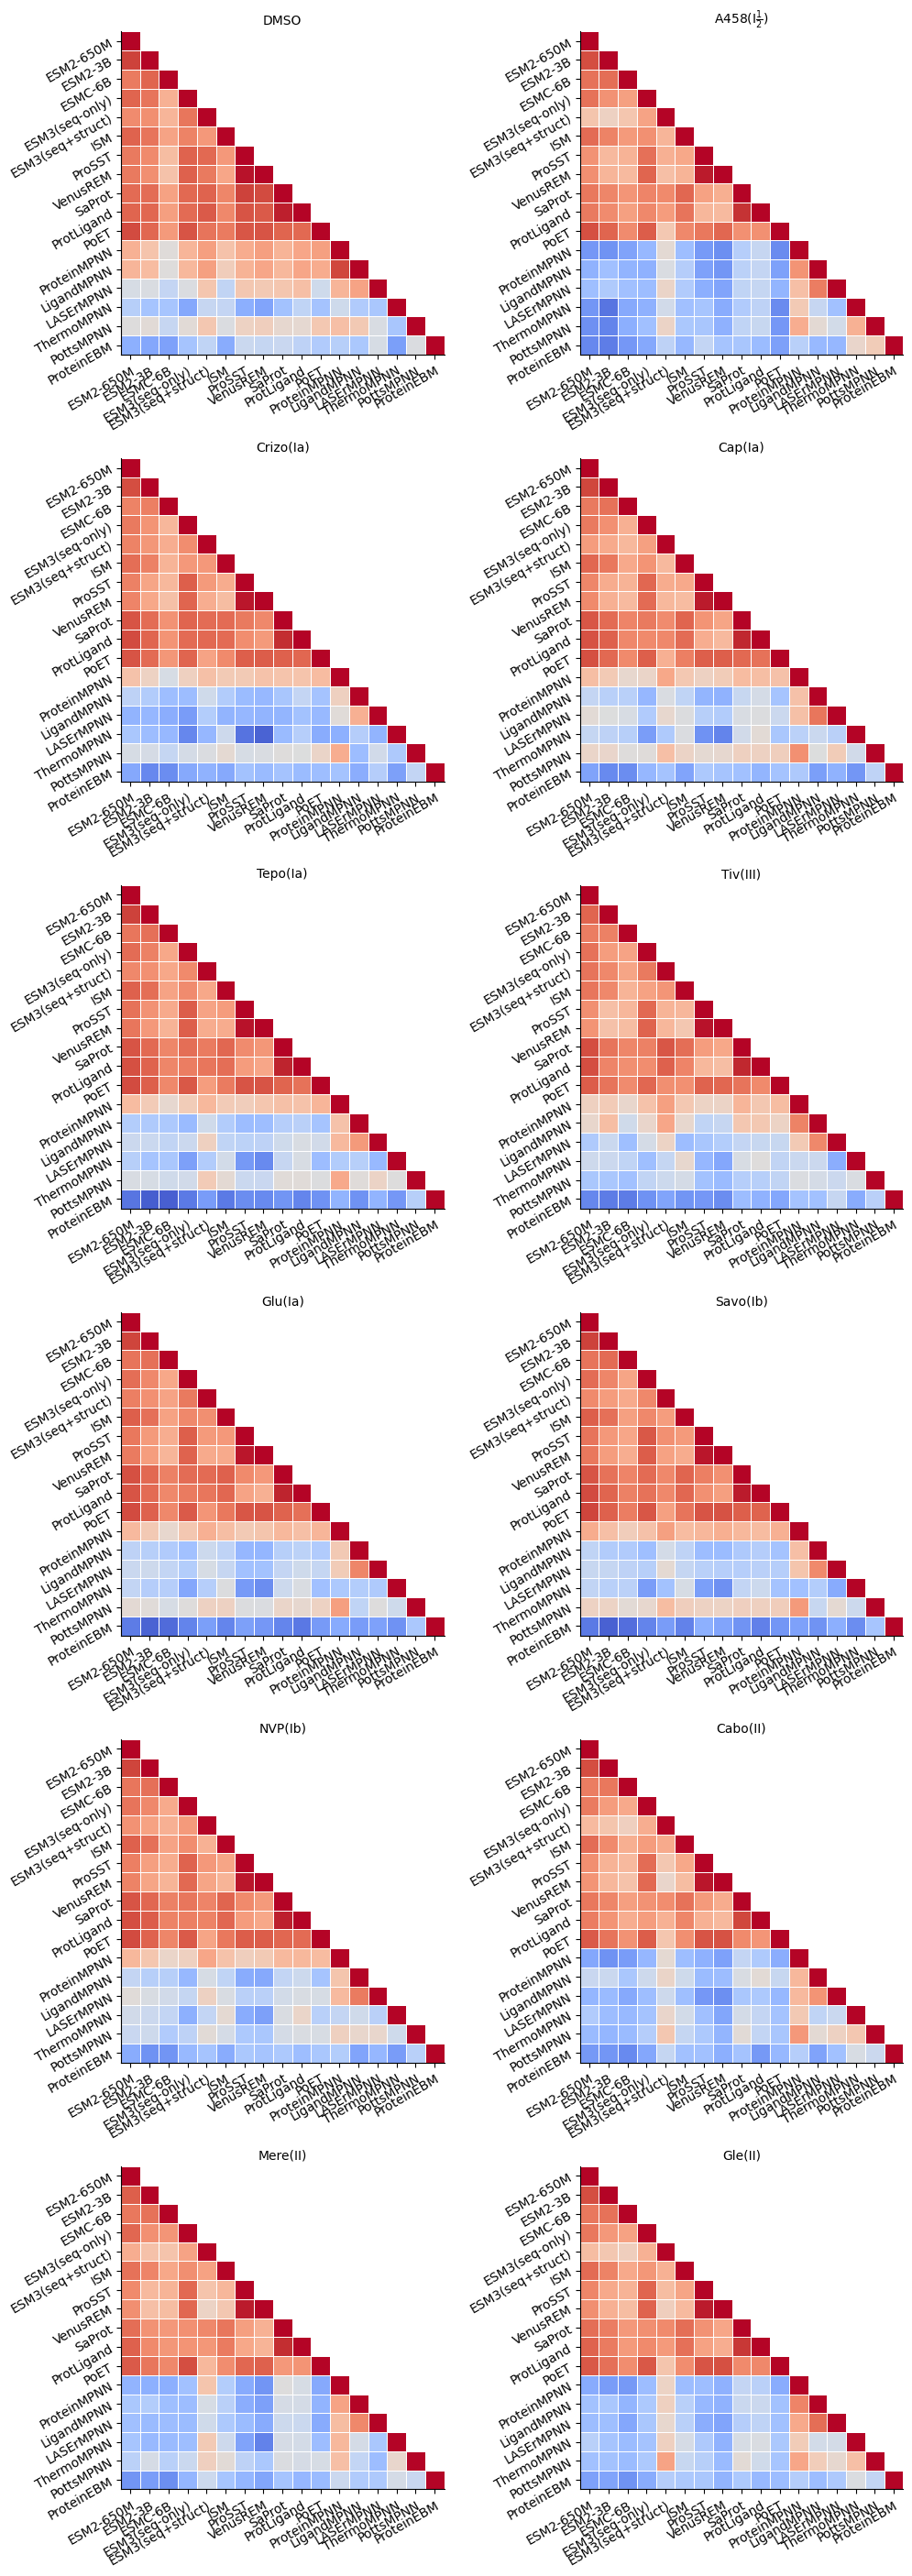

In [104]:
fig, axs = plt.subplots(6, 2, figsize=(10, 28), layout='constrained')

# Create a colorbar axis outside the grid
from mpl_toolkits.axes_grid1 import make_axes_locatable

# This will store one of the heatmaps to use its color scale
heatmap_ref = None

for ii, lname in enumerate(df['key'].unique()):
    key_df = df[(df['key'].isin([lname])) & (df['binding_region_label'])]

    data = {}
    for model_name in models:
        if model_name == 'Boltz2_affinity':
            data[f'{model_name.split('_')[0]}'] = key_df[f'{model_name}']
        else:
            data[f'{model_name}'] = key_df[f'{model_name}_mut']
    dataframe = pd.DataFrame(data)

    ax = axs[ii // 2, ii % 2]
    corr = dataframe.corr(method='pearson')
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    # Draw heatmap
    hm = sns.heatmap(
        abs(corr),
        mask=mask,
        cmap='coolwarm',
        annot=False,
        annot_kws={"size": 8},
        fmt=".2f",
        vmin=0, vmax=1,
        square=True,
        linewidths=0.5,
        cbar=False,  # Disable individual colorbars
        ax=ax,

    )

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_visible(True)

    ax.set_xticklabels([models[n] for n in dataframe.columns], rotation=30, ha="right", rotation_mode="anchor")
    ax.set_yticklabels([models[n] for n in dataframe.columns], rotation=30, ha="right", rotation_mode="anchor")

    # Save one heatmap for colorbar reference
    if heatmap_ref is None:
        heatmap_ref = hm

    ax.set_title(f"{type_label[lname]}", fontsize=10)


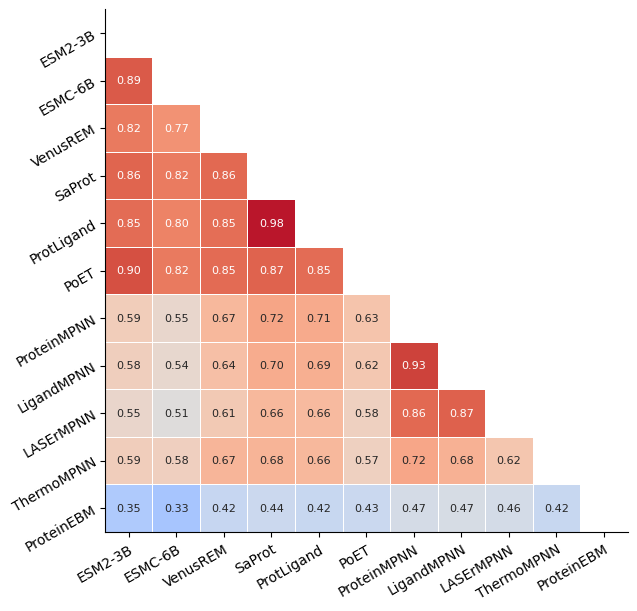

In [6]:
# Create a colorbar axis outside the grid
from mpl_toolkits.axes_grid1 import make_axes_locatable

# This will store one of the heatmaps to use its color scale
heatmap_ref = None

mean_corr = None
count = 0
for ii, lname in enumerate(df['key'].unique()):
    key_df = df[df['key'].isin([lname])]

    data = {}
    for model_name in models:
        data[f'{model_name}'] = key_df[f'{model_name}_mut']
    dataframe = pd.DataFrame(data)

    corr = dataframe.corr(method='spearman')
    if mean_corr is None:
        mean_corr = abs(corr)
    else:
        mean_corr += abs(corr)
    count += 1
    # Draw heatmap

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
mask = np.triu(np.ones_like(mean_corr, dtype=bool))
mean_corr = mean_corr / count
hm = sns.heatmap(
        mean_corr,
        cmap='coolwarm',
        annot=True,
        annot_kws={"size": 8},
        fmt=".2f",
        vmin=0, vmax=1,
        square=True,
        linewidths=0.5,
        cbar=False,  # Disable individual colorbars
        ax=ax,
        mask=mask
    )

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['bottom', 'left']:
    ax.spines[spine].set_visible(True)

ax.set_xticklabels([models[lb] for lb in data.keys()], rotation=30, ha="right", rotation_mode="anchor")
ax.set_yticklabels([models[lb] for lb in data.keys()], rotation=30, ha="right", rotation_mode="anchor")
# Add a single shared colorbar

fig.savefig('zfig_avg_full_corr_heatmap.png', dpi=300)


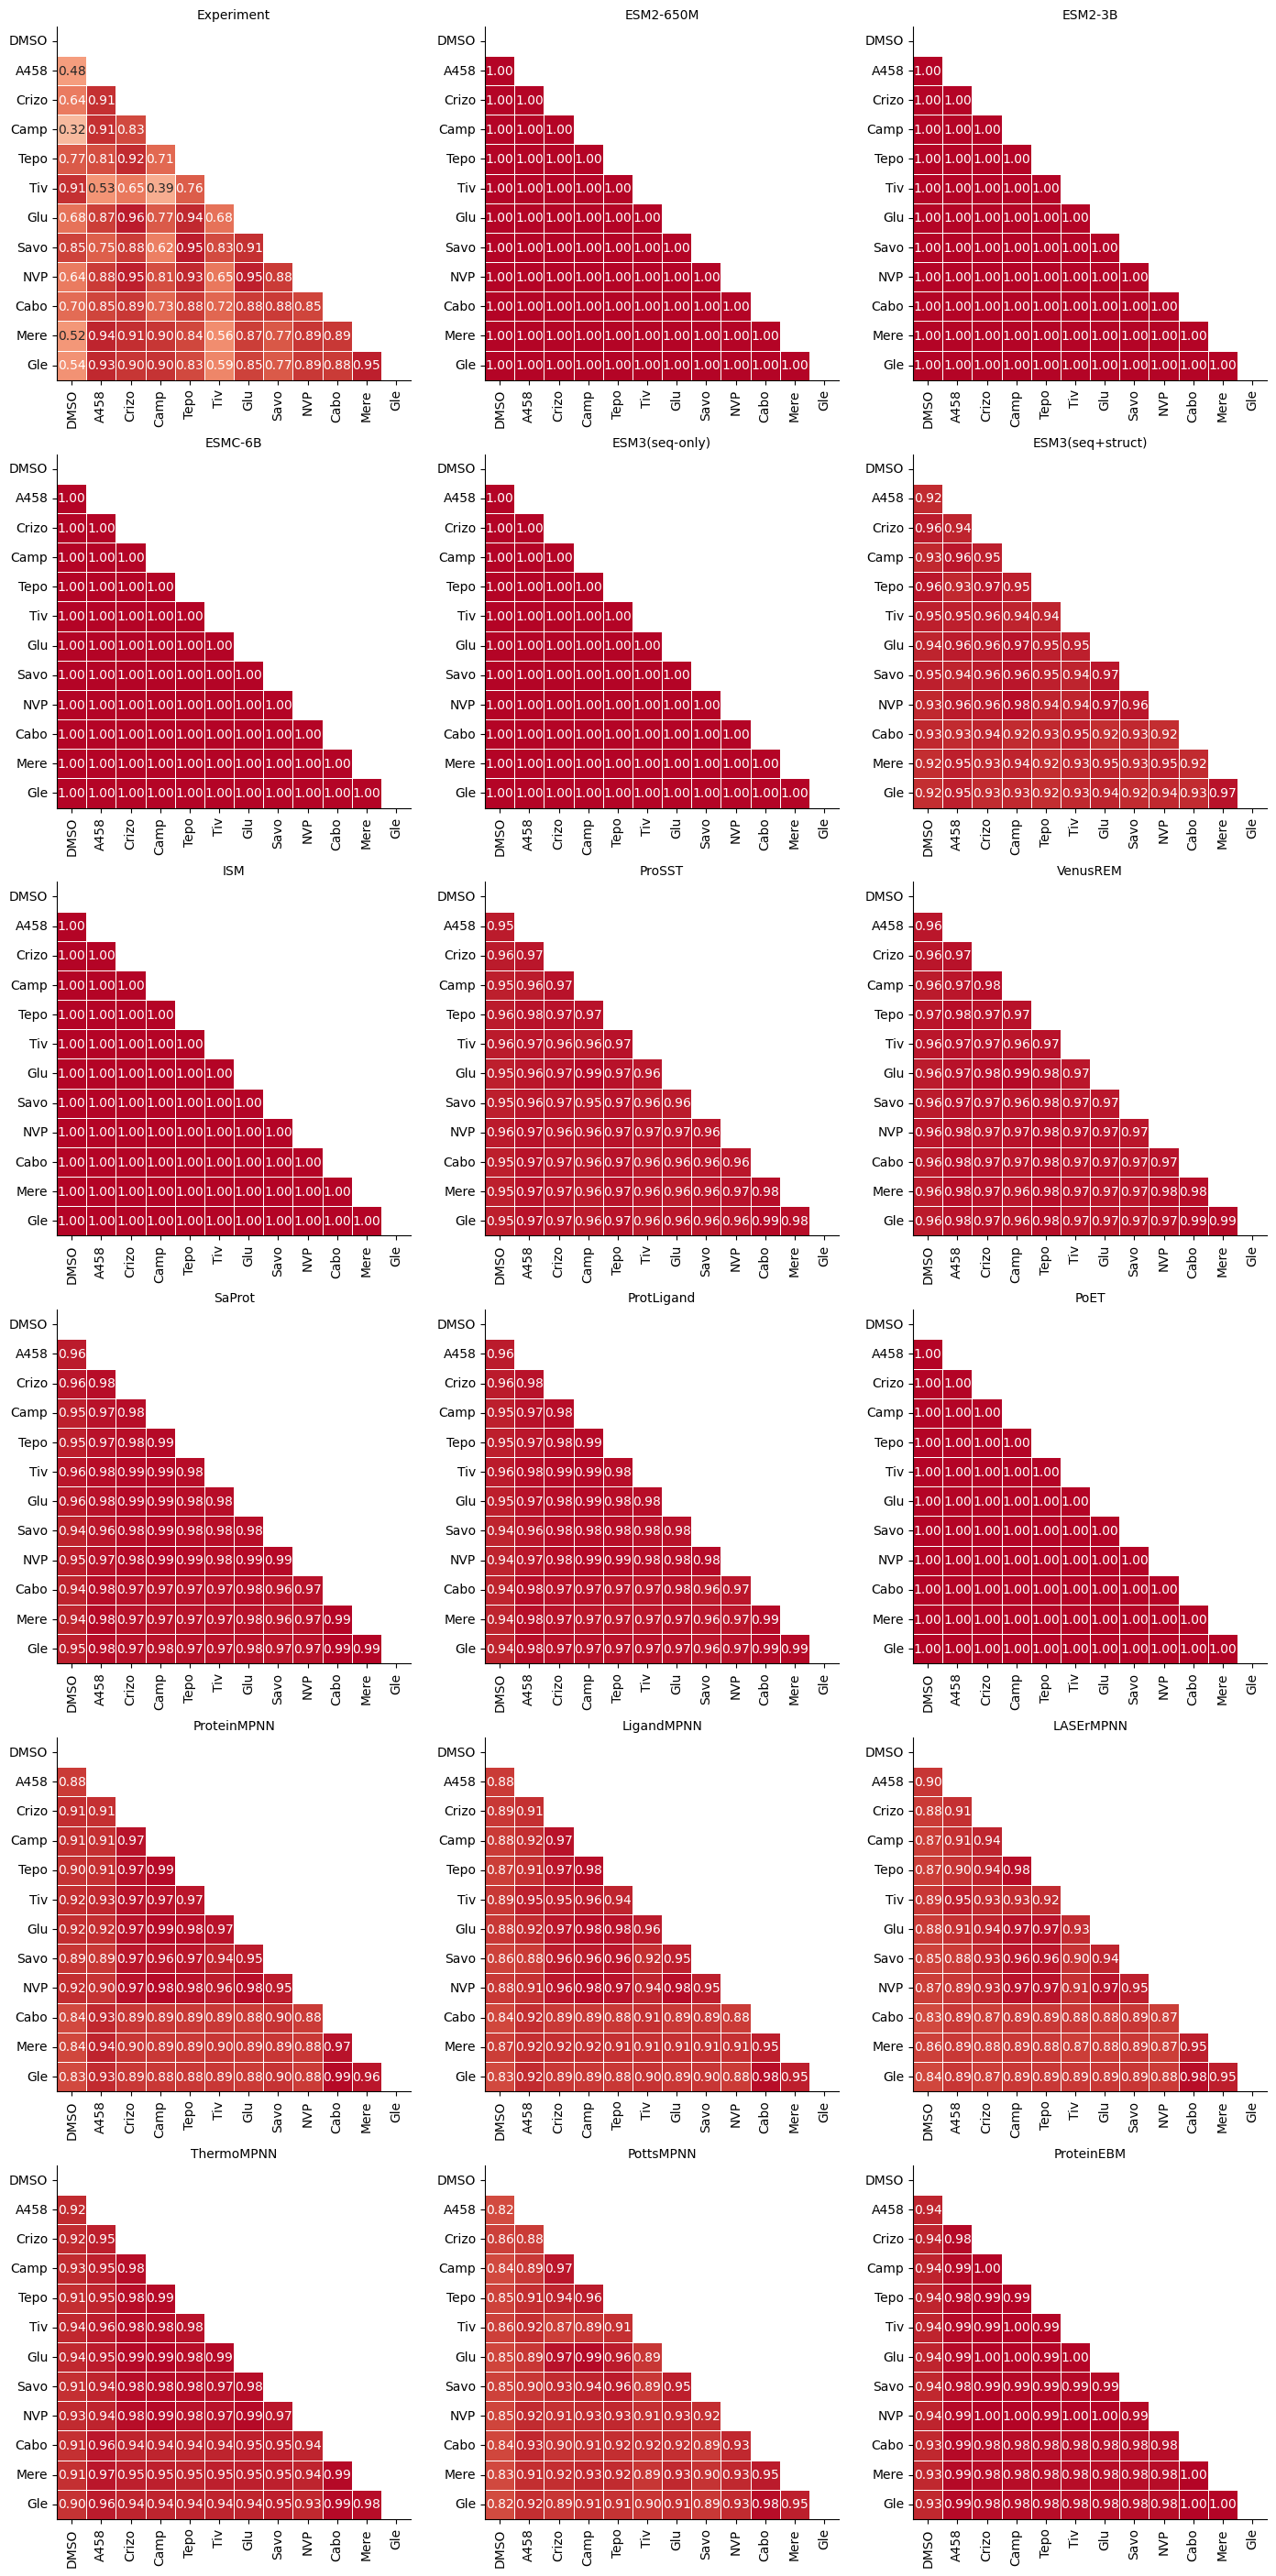

In [83]:
fig, axs = plt.subplots(6, 3, figsize=(14, 28), layout='constrained')

# Create a colorbar axis outside the grid
from mpl_toolkits.axes_grid1 import make_axes_locatable

# This will store one of the heatmaps to use its color scale
heatmap_ref = None

var_arr = [df[df['key'].isin([k])]['variants'].tolist() for k in df['key'].unique()]
common = set(var_arr[0]).intersection(*var_arr[1:])

for ii, model_name in enumerate(['mean'] + list(models.keys())):

    data = {}
    for lname in df['key'].unique():
        if 'mean' in model_name:
            data[f'{lname}'] = df[df['key'].isin([lname]) & df['variants'].isin(common)][f'mean'].values
        elif 'Boltz' in model_name: 
            data[f'{lname}'] = (6-df[df['key'].isin([lname]) & df['variants'].isin(common)][f'{model_name}'].values)*1.364
        else:
            data[f'{lname}'] = df[df['key'].isin([lname]) & df['variants'].isin(common)][f'{model_name}_mut'].values

    dataframe = pd.DataFrame(data)

    ax = axs[ii // 3, ii % 6]
    corr = dataframe.corr(method='spearman')
    mask = np.triu(np.ones_like(corr, dtype=bool))

    # Draw heatmap
    hm = sns.heatmap(
        corr,
        mask=mask,
        cmap='coolwarm',
        annot=True,
        annot_kws={"size": 10},
        fmt=".2f",
        vmin=-1, vmax=1,
        square=True,
        linewidths=0.5,
        cbar=False,  # Disable individual colorbars
        ax=ax,

    )

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_visible(True)

    # Save one heatmap for colorbar reference
    if heatmap_ref is None:
        heatmap_ref = hm

    if model_name == 'mean':
        ax.set_title(f"Experiment", fontsize=10)
    else:
        ax.set_title(f"{models[model_name]}", fontsize=10)

# Add a single shared colorbar
plt.show()


           DMSO      A458     Crizo      Camp      Tepo       Tiv       Glu  \
DMSO   1.000000  0.872292  0.903569  0.900300  0.890700  0.916282  0.910414   
A458   0.872292  1.000000  0.898092  0.905246  0.899533  0.927245  0.909633   
Crizo  0.903569  0.898092  1.000000  0.969932  0.969797  0.963976  0.970651   
Camp   0.900300  0.905246  0.969932  1.000000  0.986369  0.967989  0.984026   
Tepo   0.890700  0.899533  0.969797  0.986369  1.000000  0.960785  0.976623   
Tiv    0.916282  0.927245  0.963976  0.967989  0.960785  1.000000  0.970318   
Glu    0.910414  0.909633  0.970651  0.984026  0.976623  0.970318  1.000000   
Savo   0.883427  0.881985  0.965953  0.961269  0.962476  0.936982  0.953560   
NVP    0.903405  0.894634  0.969398  0.983779  0.975163  0.954806  0.980881   
Cabo   0.833756  0.927869  0.885739  0.880887  0.879913  0.883262  0.878027   
Mere   0.838681  0.935301  0.890301  0.884105  0.883498  0.895209  0.884631   
Gle    0.828836  0.921800  0.882649  0.877172  0.875

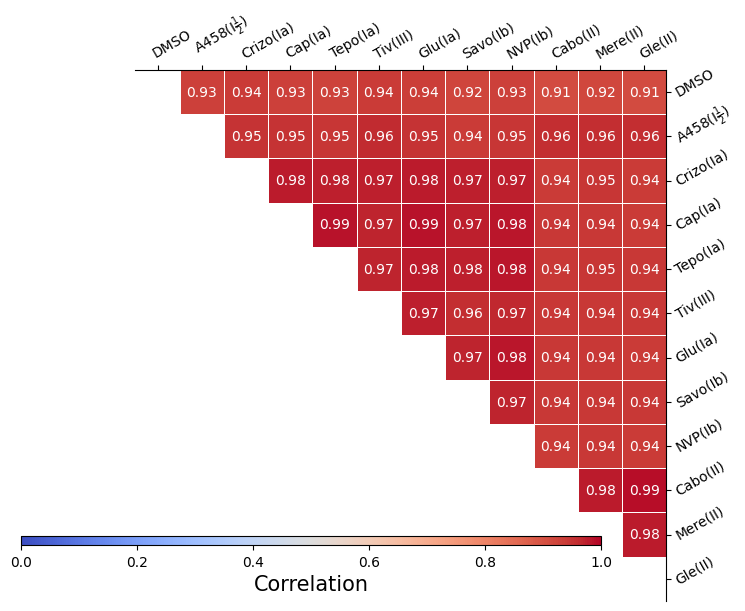

In [7]:
# Create a colorbar axis outside the grid
from mpl_toolkits.axes_grid1 import make_axes_locatable

# This will store one of the heatmaps to use its color scale
heatmap_ref = None

var_arr = [df[df['key'].isin([k])]['variants'].tolist() for k in df['key'].unique()]
common = set(var_arr[0]).intersection(*var_arr[1:])

mean_corr = None
count = 0
for model_name in ['ProteinMPNN_mut', 'LigandMPNN_mut', 'ThermoMPNN_mut', 'LASErMPNN_mut', 'ProSST_mut', 'SaProt_mut', 'ProtLigand_mut', 'venusREM_mut',  'ProteinEBM_mut']:
    data = {}

    for lname in df['key'].unique():
        data[f'{lname}'] = df[df['key'].isin([lname]) & df['variants'].isin(common)][f'{model_name}'].values
    dataframe = pd.DataFrame(data)

    corr = abs(dataframe.corr(method='pearson'))
    print(corr)
    if mean_corr is None:
        mean_corr = corr
    else:
        mean_corr += corr
    count += 1

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
mask = np.tril(np.ones_like(mean_corr, dtype=bool))
mean_corr = mean_corr / count
# Draw heatmap with mean_corr and std_corr
hm = sns.heatmap(
    mean_corr,
    mask=mask,
    cmap='coolwarm',
    annot=True,
    annot_kws={"size": 10},
    fmt=".2f",
    vmin=0, vmax=1,
    square=True,
    linewidths=0.5,
    cbar=False,  # Disable individual colorbars
    ax=ax,

)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(True)
for spine in ['bottom', 'left']:
    ax.spines[spine].set_visible(False)
# move ticks to top and right
ax.xaxis.set_ticks_position('top')
ax.yaxis.set_ticks_position('right')
# Save one heatmap for colorbar reference
if heatmap_ref is None:
    heatmap_ref = hm

ax.set_xticklabels([type_label[c] for c in data], rotation=30, ha="left", rotation_mode="anchor")
ax.set_yticklabels([type_label[c] for c in data], rotation=30, ha="left", rotation_mode="anchor")

# Add a single shared horizontal colorbar
cbar_ax = fig.add_axes([0.025, 0.1, 0.725, 0.015])  # [left, bottom, width, height]
cbar = fig.colorbar(heatmap_ref.get_children()[0], cax=cbar_ax, orientation='horizontal')
cbar.set_label('Correlation', size=15)


           DMSO      A458     Crizo      Camp      Tepo       Tiv       Glu  \
DMSO   1.000000  0.872292  0.903569  0.900300  0.890700  0.916282  0.910414   
A458   0.872292  1.000000  0.898092  0.905246  0.899533  0.927245  0.909633   
Crizo  0.903569  0.898092  1.000000  0.969932  0.969797  0.963976  0.970651   
Camp   0.900300  0.905246  0.969932  1.000000  0.986369  0.967989  0.984026   
Tepo   0.890700  0.899533  0.969797  0.986369  1.000000  0.960785  0.976623   
Tiv    0.916282  0.927245  0.963976  0.967989  0.960785  1.000000  0.970318   
Glu    0.910414  0.909633  0.970651  0.984026  0.976623  0.970318  1.000000   
Savo   0.883427  0.881985  0.965953  0.961269  0.962476  0.936982  0.953560   
NVP    0.903405  0.894634  0.969398  0.983779  0.975163  0.954806  0.980881   
Cabo   0.833756  0.927869  0.885739  0.880887  0.879913  0.883262  0.878027   
Mere   0.838681  0.935301  0.890301  0.884105  0.883498  0.895209  0.884631   
Gle    0.828836  0.921800  0.882649  0.877172  0.875

[Text(0, 0.5, 'DMSO'),
 Text(0, 1.5, 'A458(I$\\frac{1}{2}$)'),
 Text(0, 2.5, 'Crizo(Ia)'),
 Text(0, 3.5, 'Cap(Ia)'),
 Text(0, 4.5, 'Tepo(Ia)'),
 Text(0, 5.5, 'Tiv(III)'),
 Text(0, 6.5, 'Glu(Ia)'),
 Text(0, 7.5, 'Savo(Ib)'),
 Text(0, 8.5, 'NVP(Ib)'),
 Text(0, 9.5, 'Cabo(II)'),
 Text(0, 10.5, 'Mere(II)'),
 Text(0, 11.5, 'Gle(II)')]

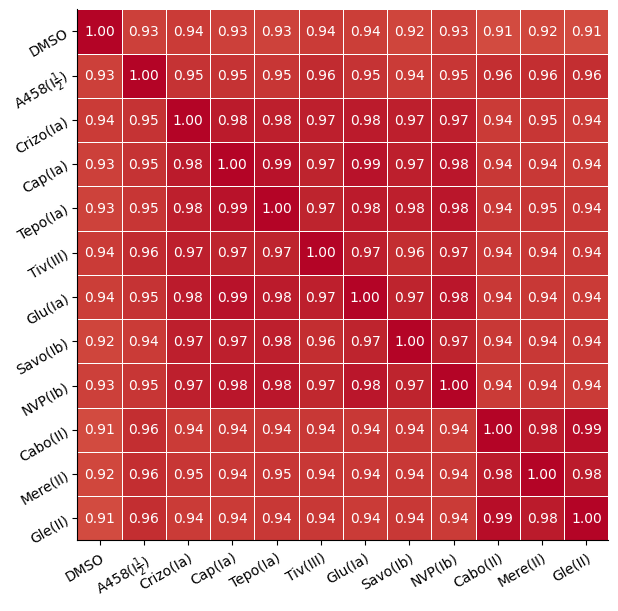

In [70]:
# Create a colorbar axis outside the grid
from mpl_toolkits.axes_grid1 import make_axes_locatable

# This will store one of the heatmaps to use its color scale
heatmap_ref = None

var_arr = [df[df['key'].isin([k])]['variants'].tolist() for k in df['key'].unique()]
common = set(var_arr[0]).intersection(*var_arr[1:])

mean_corr = None
count = 0
for model_name in ['ProteinMPNN_mut', 'LigandMPNN_mut', 'ThermoMPNN_mut', 'LASErMPNN_mut', 'ProSST_mut', 'SaProt_mut', 'ProtLigand_mut', 'venusREM_mut',  'ProteinEBM_mut']:
    data = {}

    for lname in df['key'].unique():
        data[f'{lname}'] = df[df['key'].isin([lname]) & df['variants'].isin(common)][f'{model_name}'].values
    dataframe = pd.DataFrame(data)

    corr = abs(dataframe.corr(method='pearson'))
    print(corr)
    if mean_corr is None:
        mean_corr = corr
    else:
        mean_corr += corr
    count += 1

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
mask = np.tril(np.ones_like(mean_corr, dtype=bool))
mean_corr = mean_corr / count
# Draw heatmap with mean_corr and std_corr
hm = sns.heatmap(
    mean_corr,
    cmap='coolwarm',
    annot=True,
    annot_kws={"size": 10},
    fmt=".2f",
    vmin=0, vmax=1,
    square=True,
    linewidths=0.5,
    cbar=False,  # Disable individual colorbars
    ax=ax,

)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['bottom', 'left']:
    ax.spines[spine].set_visible(True)
# move ticks to top and right
# Save one heatmap for colorbar reference
if heatmap_ref is None:
    heatmap_ref = hm

ax.set_xticklabels([type_label[c] for c in data], rotation=30, ha="right", rotation_mode="anchor")
ax.set_yticklabels([type_label[c] for c in data], rotation=30, ha="right", rotation_mode="anchor")


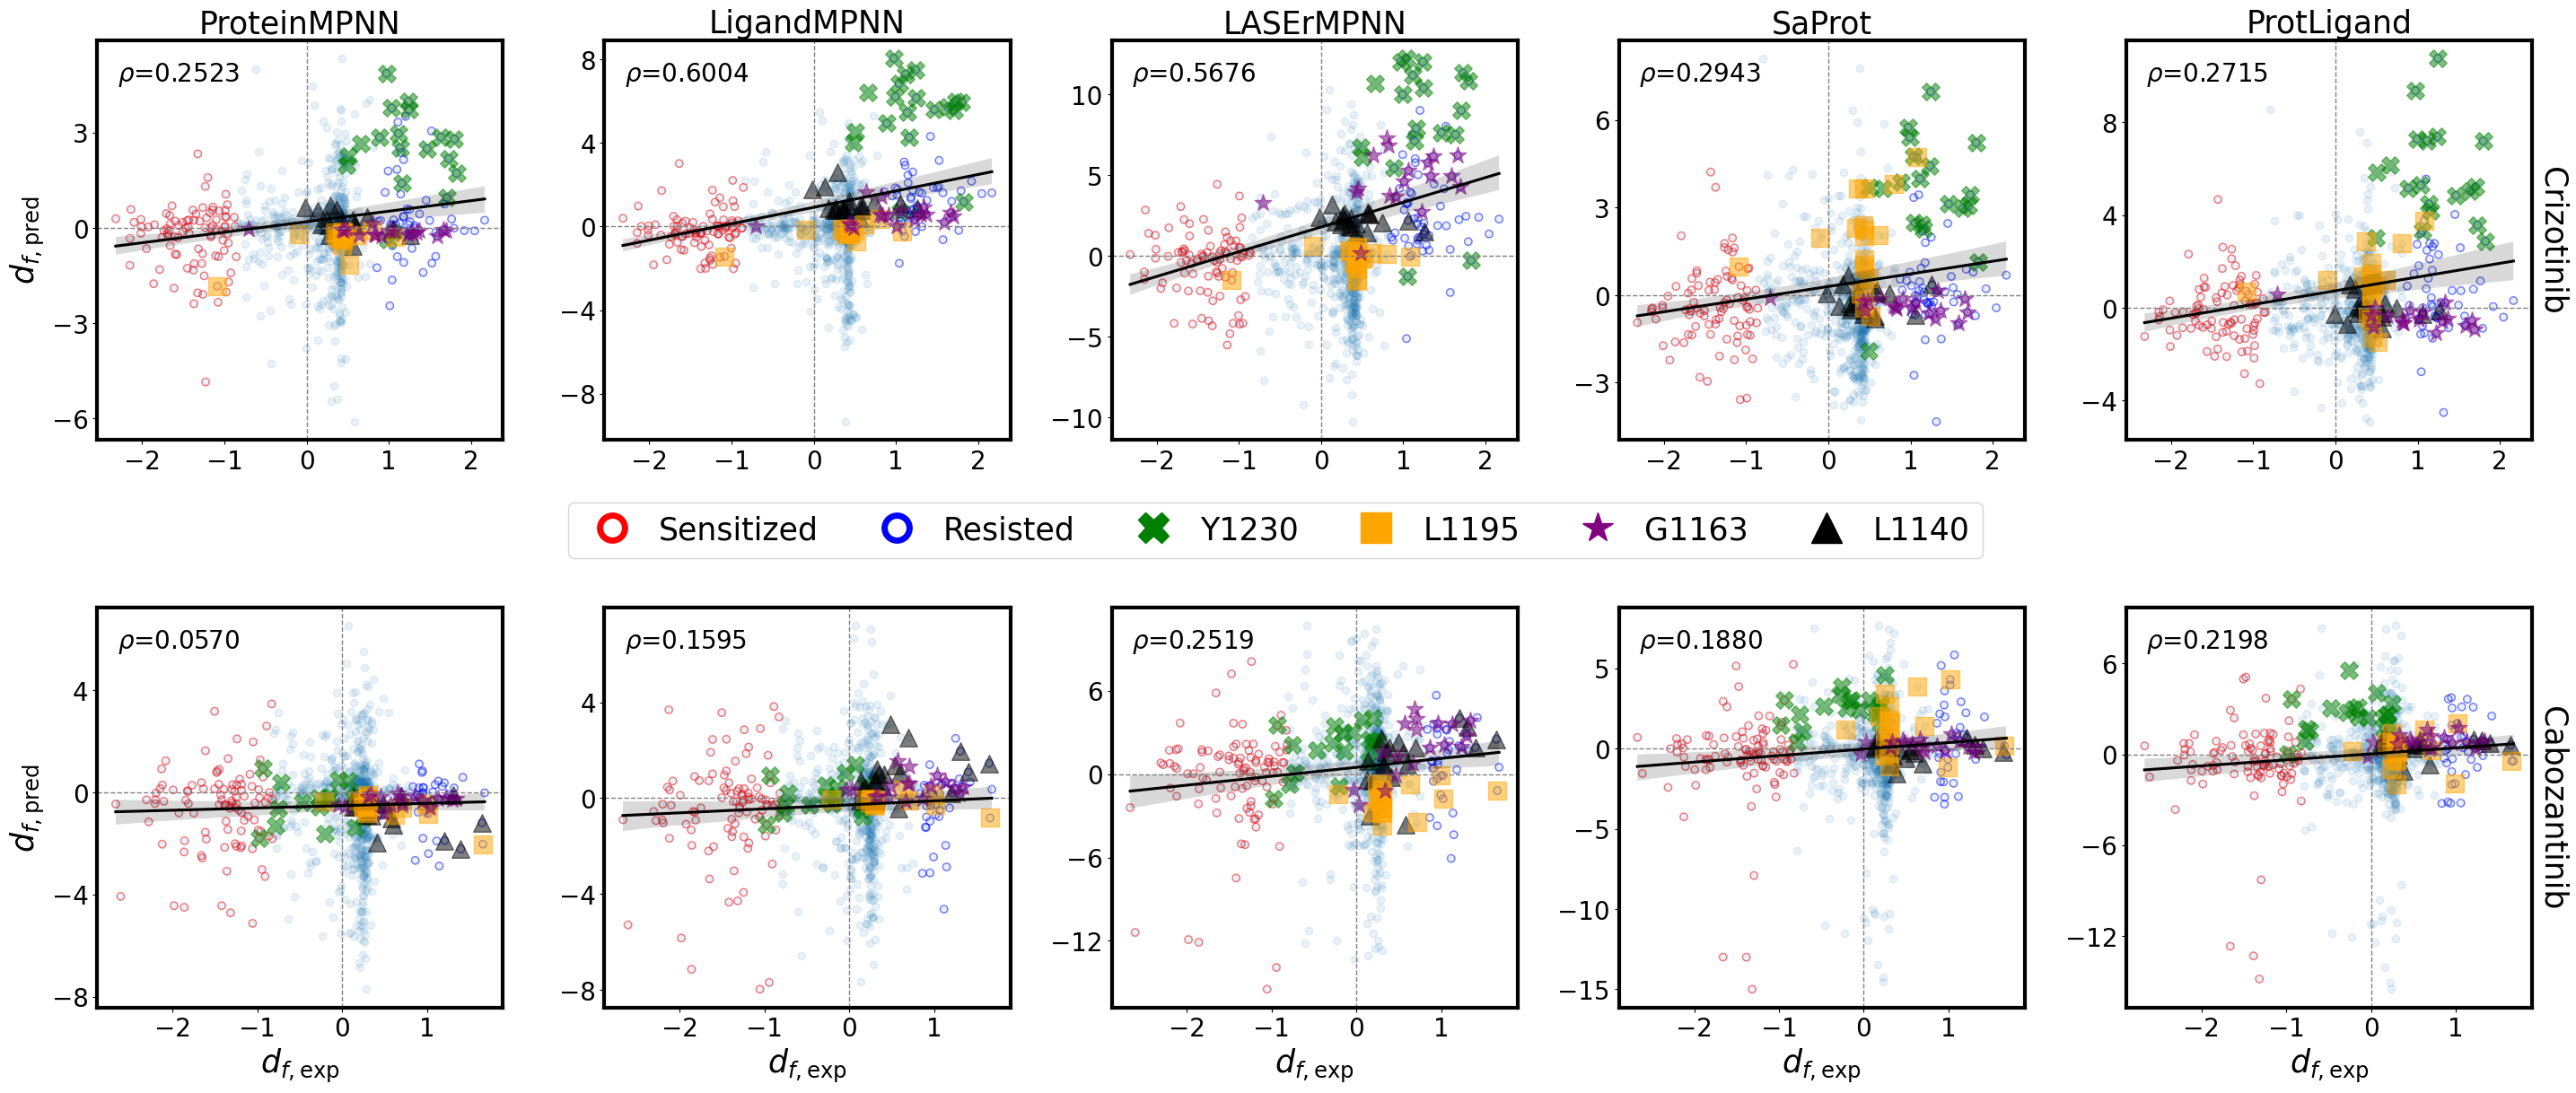

In [9]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

fig, axs = plt.subplots(2, 5, figsize=(35, 14))

dmso_df = df[df['key'].isin(['DMSO'])]
common_br = df[df['binding_region_label']]['position'].unique()
keys = df['key'].unique().tolist()
keys.append(keys.pop(keys.index('DMSO')))
nmodel = ['ProteinMPNN_mut', 'LigandMPNN_mut', 'LASErMPNN_mut', 'SaProt_mut', 'ProtLigand_mut']
nprot = {'Crizo': 'Crizotinib', 'Cabo': 'Cabozantinib'}
for ii, mm in enumerate(nmodel):
    for jj, key in enumerate(nprot.keys()):
        ax = axs[jj, ii]
        key_df = df[df['key'].isin([key])]
        key_df = key_df.merge(dmso_df[['variants', 'mean', mm]], on='variants', suffixes=('', '_dmso'))
        key_df['diff_mean'] = key_df['mean'] - key_df['mean_dmso']
        key_df['diff_' + mm] = key_df[mm] - key_df[mm + '_dmso']

        mask = key_df['position'].isin(common_br)
        mask2 = key_df['label_sensitized'] | key_df['label_resisted']

        sen_df = key_df[mask & key_df['label_sensitized']]
        res_df = key_df[mask & key_df['label_resisted']]
        df172 = key_df[key_df['position'] == 172]
        df105 = key_df[key_df['position'] == 105]
        df137 = key_df[key_df['position'] == 137]
        df82 = key_df[key_df['position'] == 82]
        br_df = key_df[mask]
        key_df_plot = key_df[mask & mask2]

        ax.scatter(br_df['diff_mean'], br_df['diff_' + mm], alpha=0.1)
        ax.scatter(sen_df['diff_mean'], sen_df['diff_' + mm],
                   alpha=0.5, edgecolor='red', facecolor='none')
        ax.scatter(res_df['diff_mean'], res_df['diff_' + mm],
                   alpha=0.5, edgecolor='blue', facecolor='none')
        ax.scatter(df172['diff_mean'], df172['diff_' + mm],
                   alpha=0.5, color='green', marker='X', s=200)
        ax.scatter(df82['diff_mean'], df82['diff_' + mm],
                   alpha=0.5, color='black', marker='^', s=200)
        ax.scatter(df137['diff_mean'], df137['diff_' + mm],
                   alpha=0.5, color='orange', marker='s', s=200)
        ax.scatter(df105['diff_mean'], df105['diff_' + mm],
                   alpha=0.5, color='purple', marker='*', s=200)

        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

        ax.axvline(0, color='grey', linestyle='--', linewidth=1)
        ax.axhline(0, color='grey', linestyle='--', linewidth=1)

        rho = key_df_plot["diff_mean"].corr(key_df_plot[f"diff_{mm}"], method='spearman')
        ax.text(0.05, 0.95, f'$\\rho$={rho:.4f}',
                transform=ax.transAxes, fontsize=20, va='top')

        sns.regplot(
            x=key_df_plot['diff_mean'],
            y=key_df_plot['diff_' + mm],
            scatter=False,
            ax=ax,
            color='k'
        )

        if ii == 0:
            ax.set_ylabel("$d_{f,\\text{pred}}$", size=25)
        else:
            ax.set_ylabel("")

        if jj == 1:
            ax.set_xlabel("$d_{f,\\text{exp}}$", size=25)
        else:
            ax.set_xlabel(f"")

        if ii == 4:
            twinx = ax.twinx()
            twinx.set_yticks([])
            twinx.set_ylabel(f"{nprot[key]}", size=25, rotation=-90, va='bottom')

        if jj == 0:
            ax.set_title(f"{mm.split('_')[0]}", size=25)

        ax.tick_params(axis='both', labelsize=20)

        for spine in ['top', 'right', 'bottom', 'left']:
            ax.spines[spine].set_linewidth(3)

# -------- figure-level legend handles --------
legend_handles = [
    Line2D([], [], marker='o', linestyle='None',
           markerfacecolor='none', markeredgecolor='red',
           markersize=20, label='Sensitized', markeredgewidth=5),
    Line2D([], [], marker='o', linestyle='None',
           markerfacecolor='none', markeredgecolor='blue',
           markersize=20, label='Resisted', markeredgewidth=5),
    Line2D([], [], marker='X', linestyle='None',
           color='green', markersize=25, label=f'Y{1058+172}'),
    Line2D([], [], marker='s', linestyle='None',
           color='orange', markersize=25, label=f'L{1058+137}'),
    Line2D([], [], marker='*', linestyle='None',
           color='purple', markersize=25, label=f'G{1058+105}'),
    Line2D([], [], marker='^', linestyle='None',
           color='black', markersize=25, label=f'L{1058+82}'),
]

# leave space between the two subplot rows
fig.subplots_adjust(hspace=0.42, wspace=0.25)

# put legend in the middle gap between rows
fig.legend(
    handles=legend_handles,
    loc='center',
    bbox_to_anchor=(0.5, 0.49),   # center of the whole figure
    ncol=6,
    frameon=True,
    fontsize=25,
    columnspacing=1.5,
    handletextpad=0.5,

)

plt.show()


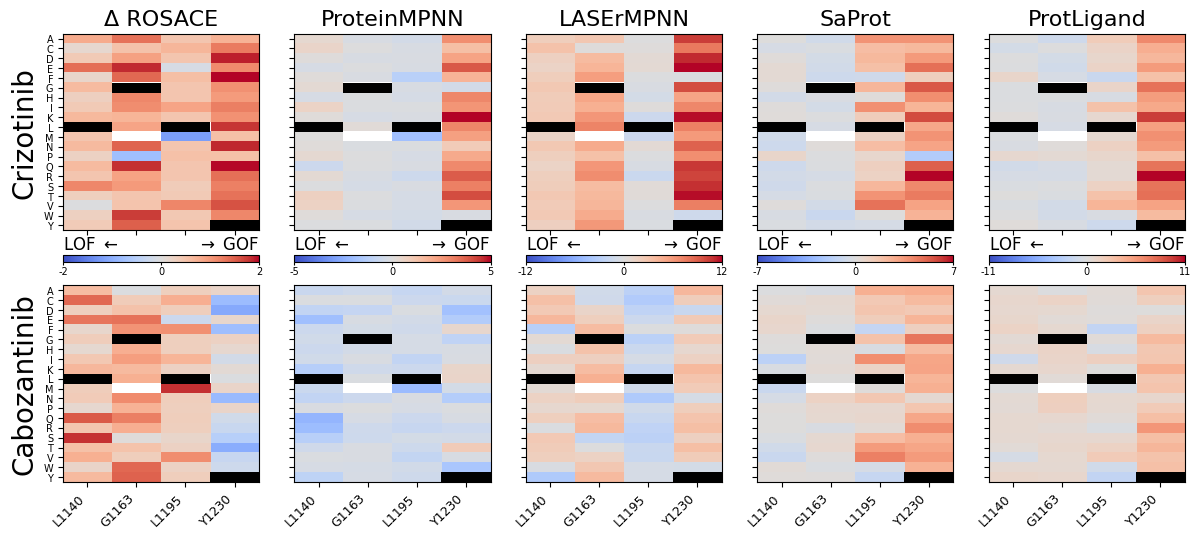

In [31]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

AA = list('ACDEFGHIKLMNPQRSTVWY')
POS      = [82, 105, 137, 172]
POS_LBL  = ['L1140', 'G1163', 'L1195', 'Y1230']
WT       = {82: 'L', 105: 'G', 137: 'L', 172: 'Y'}
INHIBS   = ['Crizo', 'Cabo']
ylabel   = ['Crizotinib', 'Cabozantinib']
METRICS  = [('\u0394 ROSACE', 'mean'),
            ('ProteinMPNN', 'ProteinMPNN_mut'), ('LASErMPNN', 'LASErMPNN_mut'),
            ('SaProt', 'SaProt_mut'), ('ProtLigand', 'ProtLigand_mut')]

def d_f(inhib, col):
    pi = df[df.key == inhib].pivot_table(index='mutation', columns='position', values=col)
    p0 = df[df.key == 'DMSO'].pivot_table(index='mutation', columns='position', values=col)
    return (pi - p0).reindex(index=AA, columns=POS)

nrow, ncol = len(INHIBS), len(METRICS)
fig, axs = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 2.3 * nrow + 0.8), squeeze=False)

col_im, col_vmax = {}, {}
for c, (mlabel, col) in enumerate(METRICS):
    mats = {inh: d_f(inh, col) for inh in INHIBS}
    vmax = np.nanmax([np.nanmax(np.abs(m.values)) for m in mats.values()])
    for r, inh in enumerate(INHIBS):
        ax = axs[r][c]
        M = np.ma.masked_invalid(mats[inh].values)
        cmap = plt.cm.coolwarm.copy(); cmap.set_bad('white')
        im = ax.imshow(M, cmap=cmap, vmin=-vmax, vmax=vmax, aspect='auto')
        for j, p in enumerate(POS):
            ax.add_patch(Rectangle((j - 0.5, AA.index(WT[p]) - 0.5), 1, 1,
                                   facecolor='black', edgecolor='none', zorder=3))
        ax.set_xticks(range(len(POS)))
        ax.set_xticklabels(POS_LBL if r == nrow - 1 else [], rotation=45, ha='right', fontsize=9)
        ax.set_yticks(range(len(AA)))
        ax.set_yticklabels(AA if c == 0 else [], fontsize=7)
        if r == 0: ax.set_title(mlabel, fontsize=16)
        if c == 0: ax.set_ylabel(ylabel[r], fontsize=20)
    col_im[c], col_vmax[c] = im, vmax

# open a *small* strip between rows; place a colorbar per column in it
# open a small strip between rows; place a colorbar per column in it
fig.subplots_adjust(left=0.06, right=0.995, top=0.93, bottom=0.10, wspace=0.18, hspace=0.28)
for c in range(ncol):
    top_box = axs[0, c].get_position()
    bot_box = axs[1, c].get_position()
    y = bot_box.y1 + (top_box.y0 - bot_box.y1) * 0.42     # lowered to leave room above the bar
    cax = fig.add_axes([bot_box.x0, y, bot_box.width, 0.014])
    cb = fig.colorbar(col_im[c], cax=cax, orientation='horizontal')
    v = col_vmax[c]
    cb.set_ticks([-v, 0, v]); cb.set_ticklabels([f'{-v:.0f}', '0', f'{v:.0f}'])
    cb.ax.tick_params(labelsize=7, length=2, pad=1)

    # second label row ON TOP of the bar: LOF at the min end, GOF at the max end
    sec = cb.ax.secondary_xaxis('top')
    sec.set_xticks([-v, v]); sec.set_xticklabels(['LOF $\\leftarrow$', '$\\rightarrow$ GOF'], fontsize=12)
    sec.tick_params(length=0, pad=1)
    sec.spines['top'].set_visible(False)
    for lbl, ha in zip(sec.get_xticklabels(), ['left', 'right']):
        lbl.set_horizontalalignment(ha)      # keeps both labels inside the bar width

plt.show()      # no tight_layout after manual axes


method,Boltz2_aff,Boltz2_mw_aff,PBCNet_aff,TankBind_aff,autodock_ddg,bind_pIC50_aff,drugform_lgIC50_aff,drugform_pKi_aff,em_aff,flowdock_aff,flowr_lgIC50_aff,flowr_pKi_aff,gems_aff
key,,,,,,,,,,,,,
A458,1.807,2.278,0.777,-0.014,-1.083,1.216,0.539,-1.068,-0.417,-0.665,1.519,-2.716,-0.482
Cabo,1.627,2.013,0.870,-0.483,-2.274,0.982,1.005,-0.350,-0.679,-0.607,2.054,-1.811,-0.822
Camp,2.119,2.313,0.758,-2.085,-0.716,1.160,0.533,-0.272,-0.529,-0.870,3.523,-2.997,-0.838
Crizo,2.050,2.329,0.926,-1.710,-1.620,0.489,0.554,-0.203,0.007,-1.007,1.979,-2.317,-1.109
Gle,2.102,2.554,0.634,-0.627,-1.158,1.304,1.433,-0.294,-0.958,-0.906,1.725,-1.784,-0.942
Glu,1.789,2.097,0.344,-0.872,-0.799,0.809,0.465,-0.425,0.451,-0.880,2.121,-2.034,-0.944
Mere,1.736,2.255,0.756,-0.719,-1.404,1.997,0.703,-0.941,-0.206,-0.962,2.458,-2.595,-1.280
NVP,1.850,1.826,0.239,-0.940,-0.326,0.651,0.165,0.375,0.144,-0.501,1.923,-1.963,-0.187
Savo,1.468,1.452,0.321,-1.882,-1.246,0.333,0.004,0.163,-0.044,-0.696,2.503,-2.112,-0.278


/tmp/ipykernel_1939120/1158698154.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_dir[c] for c in cols], rotation=25, ha='right', fontsize=20)


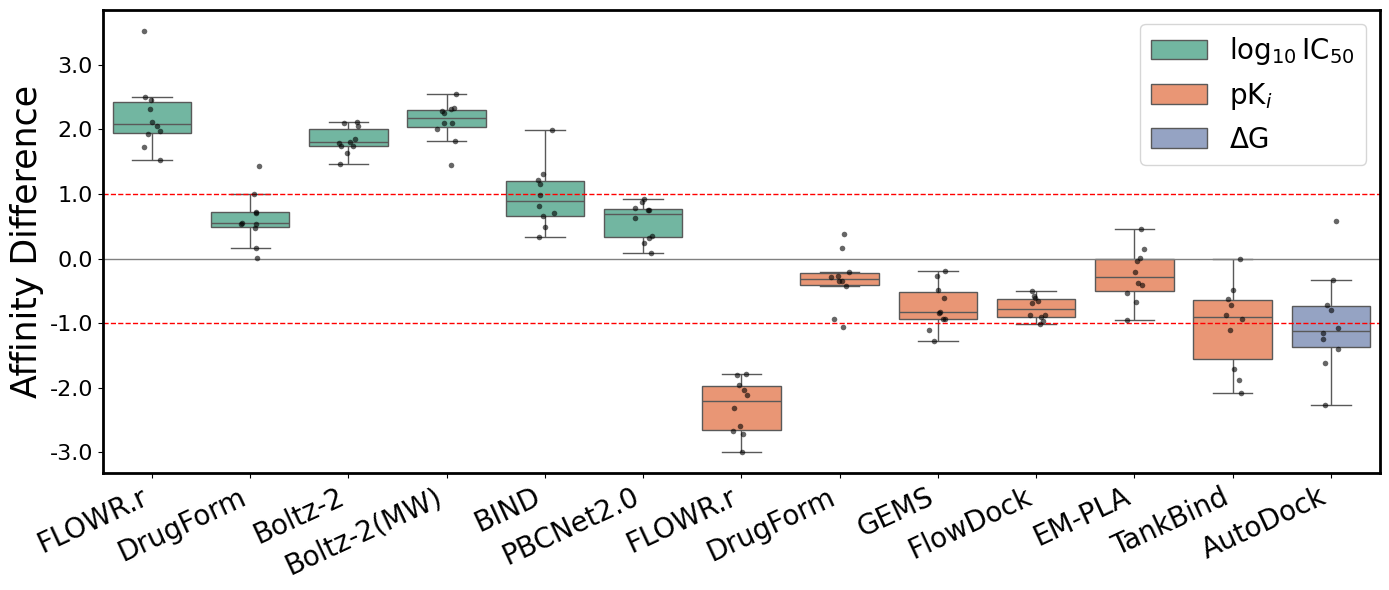

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../MET_unfiltered.csv')

# methods grouped by unit
unit_groups = {
    r'$\log_{10}$IC$_{50}$': ['flowr_lgIC50_aff', 'drugform_lgIC50_aff', 'Boltz2_aff',
                              'Boltz2_mw_aff', 'bind_pIC50_aff', 'PBCNet_aff'],
    r'pK$_{i}$':             ['flowr_pKi_aff', 'drugform_pKi_aff', 'gems_aff',
                              'flowdock_aff', 'em_aff', 'TankBind_aff'],
    r'$\Delta$G':      ['autodock_ddg'],
}
# display labels WITHOUT units (used only for x tick labels)
label_dir = {
    'Boltz2_aff':'Boltz-2', 'Boltz2_mw_aff':'Boltz-2(MW)', 'gems_aff':'GEMS',
    'em_aff':'EM-PLA', 'drugform_pKi_aff':'DrugForm', 'drugform_lgIC50_aff':'DrugForm',
    'flowr_pKi_aff':'FLOWR.r', 'flowr_lgIC50_aff':'FLOWR.r', 'flowdock_aff':'FlowDock',
    'bind_pIC50_aff':'BIND', 'PBCNet_aff':'PBCNet2.0', 'autodock_ddg':'AutoDock', 'TankBind_aff':'TankBind'
}

# method -> unit, and ordered column list (same-unit methods together)
unit_of = {c: u for u, cs in unit_groups.items() for c in cs}
cols = [c for cs in unit_groups.values() for c in cs]
units_order = list(unit_groups.keys())
palette = dict(zip(units_order, sns.color_palette('Set2', n_colors=len(units_order))))

ref_key = 'Tiv'
# exclude DMSO (and Tiv itself) from the comparison keys
other_keys = [k for k in df['key'].unique() if k not in (ref_key, 'DMSO')]

# difference in mean between Tiv and every other key, per method
# keep the raw column name as the unique method id (so duplicate display
# names like the two DrugForm / FLOWR entries stay as separate boxes)
records = []
for col in cols:
    tiv_mean = df.loc[df['key'] == ref_key, col].mean()
    for k in other_keys:
        other_mean = df.loc[df['key'] == k, col].mean()
        records.append({'method': col, 'unit': unit_of[col], 'key': k,
                        'mean_diff': tiv_mean - other_mean})

diff_df = pd.DataFrame(records)
display(diff_df.pivot(index='key', columns='method', values='mean_diff').round(3))

# box plot: one box per method, colored by unit
order = cols
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=diff_df, x='method', y='mean_diff', order=order,
            hue='unit', hue_order=units_order, palette=palette, dodge=False, ax=ax, showfliers=False)
sns.stripplot(data=diff_df, x='method', y='mean_diff', order=order,
              color='black', size=4, alpha=0.6, ax=ax)
ax.axhline(0, color='grey', linestyle='-', linewidth=1)
ax.set_xlabel('')                                                   # remove x label
ax.set_ylabel('Affinity Difference', fontsize=25)
ax.set_yticks(np.linspace(-3, 3, 7))
ax.axhline(-1, color='red', linestyle='--', linewidth=1)
ax.axhline(1, color='red', linestyle='--', linewidth=1)
ax.set_yticklabels([f'{y:.1f}' for y in np.linspace(-3, 3, 7)], fontsize=16)

# unit-free tick labels
ax.set_xticklabels([label_dir[c] for c in cols], rotation=25, ha='right', fontsize=20)
ax.legend( fontsize=20)
for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_linewidth(2)
plt.tight_layout()
plt.show()


method,Boltz2_aff,PBCNet_aff,TankBind_aff,autodock_ddg,bind_pIC50_aff,drugform_lgIC50_aff,em_aff,flowdock_aff,flowr_lgIC50_aff,gems_aff
key,,,,,,,,,,
A458,0.126,0.061,0.062,0.060,0.017,0.013,0.068,0.006,0.070,0.032
Cabo,0.158,0.037,0.057,0.024,0.039,0.010,0.024,0.010,0.056,0.033
Camp,0.114,0.074,0.134,0.231,0.026,0.017,0.071,0.017,0.149,0.102
Crizo,0.169,0.022,0.106,0.254,0.023,0.017,0.083,0.022,0.113,0.054
DMSO,0.048,0.064,0.045,0.026,0.103,0.006,0.018,0.011,0.047,0.063
Gle,0.210,0.022,0.055,0.036,0.012,0.003,0.045,0.008,0.029,0.039
Glu,0.070,0.036,0.074,0.152,0.012,0.007,0.068,0.011,0.137,0.051
Mere,0.198,0.018,0.042,0.033,0.034,0.011,0.026,0.013,0.036,0.041
NVP,0.161,0.036,0.112,0.332,0.008,0.011,0.069,0.026,0.070,0.053


/tmp/ipykernel_1939120/2811324146.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_dir[c] for c in cols], rotation=0, fontsize=20)


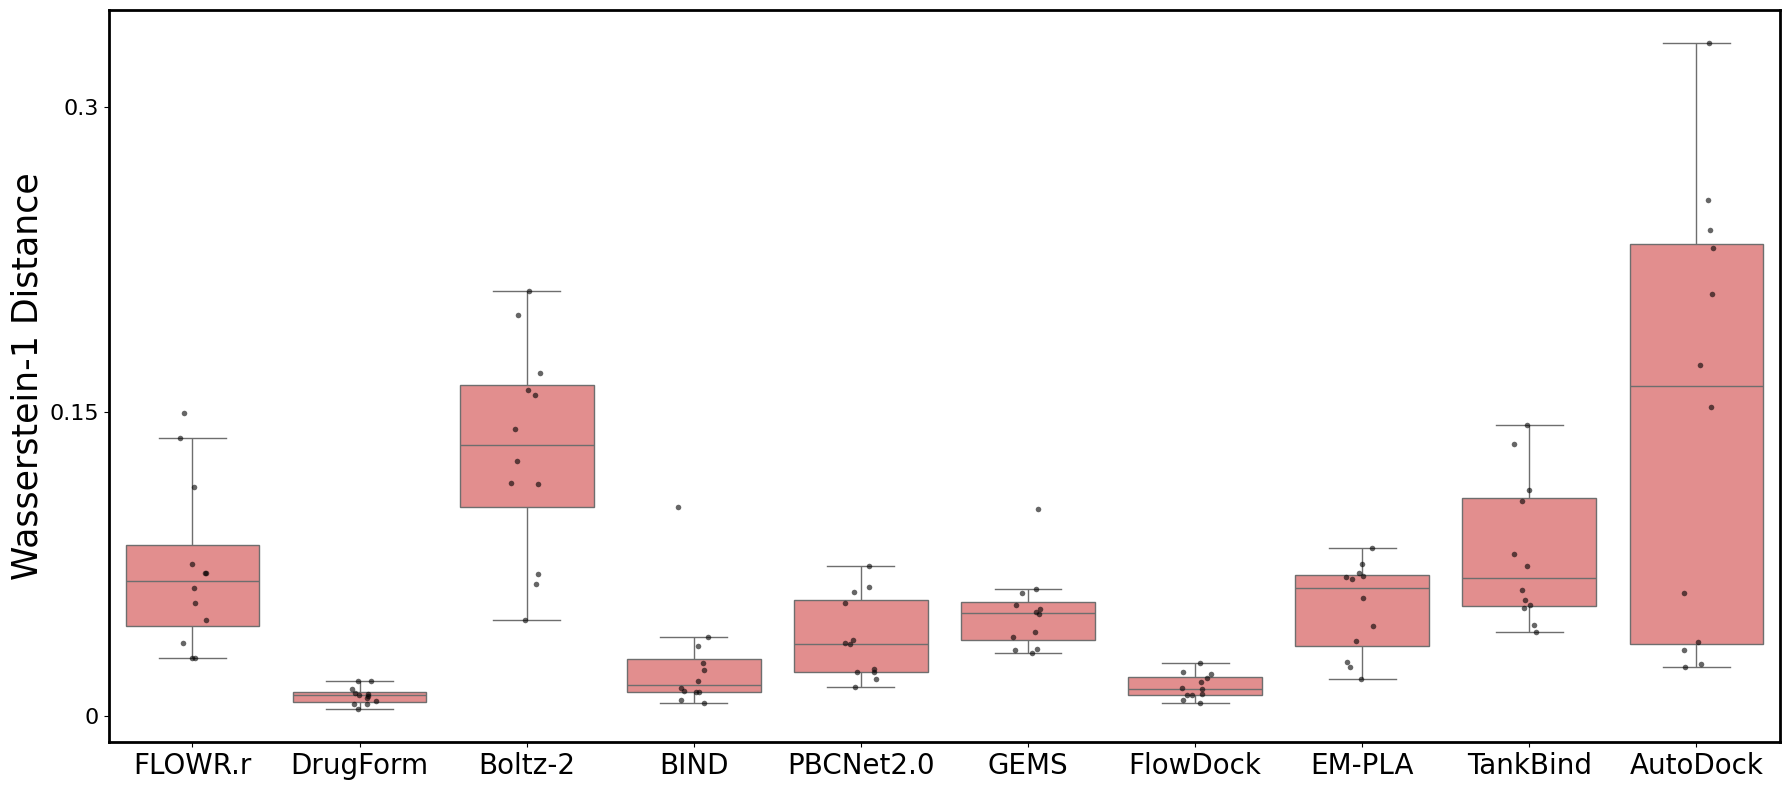

In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wasserstein_distance

df = pd.read_csv('../MET_unfiltered.csv')

keys_order = ['DMSO','Tiv','Savo','Tepo','Cabo','Glu','NVP','Crizo','Gle','Mere','A458','Camp']

# methods grouped by unit (same scheme as the mean-difference plot)
unit_groups = {
    r'$\log_{10}$IC$_{50}$': ['flowr_lgIC50_aff', 'drugform_lgIC50_aff', 'Boltz2_aff',
                              'Boltz2_mw_aff', 'bind_pIC50_aff', 'PBCNet_aff'],
    r'pK$_{i}$':             ['flowr_pKi_aff', 'drugform_pKi_aff', 'gems_aff',
                              'flowdock_aff', 'em_aff', 'TankBind_aff'],
    r'$\Delta\Delta$G':      ['autodock_ddg'],
}
label_dir = {
    'Boltz2_aff':'Boltz-2', 'Boltz2_mw_aff':'Boltz-2(MW)', 'gems_aff':'GEMS',
    'em_aff':'EM-PLA', 'drugform_pKi_aff':'DrugForm', 'drugform_lgIC50_aff':'DrugForm',
    'flowr_pKi_aff':'FLOWR.r', 'flowr_lgIC50_aff':'FLOWR.r', 'flowdock_aff':'FlowDock',
    'bind_pIC50_aff':'BIND', 'PBCNet_aff':'PBCNet2.0', 'autodock_ddg':'AutoDock',
    'TankBind_aff':'TankBind'
}

# columns to report (W1 distances), ordered so same-unit methods are adjacent
cols = ['flowr_lgIC50_aff', 'drugform_lgIC50_aff',
        'Boltz2_aff', 'gems_aff', 'flowdock_aff', 'bind_pIC50_aff', 'em_aff',
        'PBCNet_aff', 'TankBind_aff', 'autodock_ddg']
unit_of = {c: u for u, cs in unit_groups.items() for c in cs}
cols = [c for cs in unit_groups.values() for c in cs if c in cols]  # reorder by unit
units_order = list(unit_groups.keys())

# --- W1 distance: full-domain vs binding-region, per method per ligand (unchanged) ---
records = []
for col in cols:
    for key in keys_order:
        if col == 'autodock_ddg':
            full_col = df[df['key']==key][col].dropna().values
            br_col = df[(df['key']==key) & df['binding_region_label']][col].dropna().values
        else:
            full_col = df[df['key']==key][col].values
            mask = df['binding_region_label']
            br_col = df[(df['key']==key) & mask][col].values
        w1 = wasserstein_distance(full_col, br_col)
        records.append({'method': col, 'unit': unit_of[col], 'key': key, 'w1': w1})

dist_df = pd.DataFrame(records)
display(dist_df.pivot(index='key', columns='method', values='w1').round(3))

# --- box plot, single color for all boxes ---
order = cols
fig, ax = plt.subplots(figsize=(18, 8))
sns.boxplot(data=dist_df, x='method', y='w1', order=order,
            color='lightcoral', ax=ax, showfliers=False)
sns.stripplot(data=dist_df, x='method', y='w1', order=order,
              color='black', size=4, alpha=0.6, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('Wasserstein-1 Distance', fontsize=25)
ax.set_yticks([0, 0.15, 0.3])
ax.set_yticklabels([0, 0.15, 0.3], fontsize=16)
ax.set_xticklabels([label_dir[c] for c in cols], rotation=0, fontsize=20)
for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_linewidth(2)
plt.tight_layout()
plt.show()


In [ ]:
import os 
from scipy.stats import wasserstein_distance
from scipy.spatial import distance

df = pd.read_csv('../MET_unfiltered.csv')
# align 0 tick vertically while allowing different x-scales per subplot
cols = ['flowr_lgIC50_aff', 'drugform_lgIC50_aff',
    'Boltz2_aff', 'gems_aff', 'flowdock_aff', 'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'autodock_ddg']
keys_order = ['DMSO','Tiv','Savo','Tepo','Cabo','Glu','NVP','Crizo','Gle','Mere','A458','Camp']
label_dir = {
    'Boltz2_aff':'Boltz-2',
    'Boltz2_mw_aff':'Boltz-2(MW)',
    'gems_aff':'GEMS',
    'prosmith_aff':'ProSmith',
    'em_aff':'EM-PLA',
    'drugform_pKi_aff':'DrugForm',
    'drugform_lgIC50_aff':'DrugForm',
    'flowr_pKi_aff': 'FLOWR.root',
    'flowr_lgIC50_aff': 'FLOWR.root',
    'flowdock_aff': 'FlowDock',
    'bind_pIC50_aff': 'BIND',
    'PBCNet_aff': 'PBCNet2.0',
    'autodock_ddg': 'AutoDock'
}
cmap = sns.color_palette("coolwarm", n_colors=len(keys_order))

target_zero_frac = 0.50  # fraction from left where 0 should appear in each subplot

fig, ax = plt.subplots(1, 1, figsize=(14, 6))

ls = ['-', '--', '-.', ':']

wass_dict = {}
for col in cols:
    mean_dmso = df[df['key']=='DMSO'][col].mean()

    # compute per-key distributions adjusted by dmso mean
    col_mins, col_maxs = [], []
    all_vals_per_key = {}
    mask_vals_per_key = {}

    wass_d = []
    for key in keys_order[::-1]:
        if col == 'autodock_ddg':
            full_col = df[df['key']==key ][col].dropna().values
            br_col = df[(df['key']==key) & df['binding_region_label']][col].dropna().values

            wass_d += [wasserstein_distance(full_col, br_col)]

        else:
            full_col = df[df['key']==key ][col].values

            mask = df['binding_region_label'] 

            br_col = df[(df['key']==key) & mask][col].values

            wass_d += [wasserstein_distance(full_col, br_col)]

    wass_dict[col] = wass_d

# make vollin plot of wass_dict by cols
wass_df = pd.DataFrame(wass_dict, index=keys_order[::-1])

for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_linewidth(3)

vp = ax.violinplot(wass_df.values, showmeans=True, showmedians=False, showextrema=False, points=1000)
ax.grid(axis='x', linestyle='--', alpha=0.7, zorder=0)
for pc in vp['bodies']:
    pc.set_facecolor('red')
    pc.set_edgecolor('black')
    pc.set_alpha(1)
    pc.set_linewidth(1)
    pc.set_zorder(1)

ax.set_xticks(np.arange(1, len(cols)+1))
ax.set_xticklabels([label_dir[c] for c in cols], rotation=0, ha='center', fontsize=12)
ax.set_ylabel('Wasserstein-1 Distance', fontsize=20)


In [ ]:
import os 
from scipy.stats import wasserstein_distance
from scipy.spatial import distance

df = pd.read_csv('../MET_unfiltered.csv')
# align 0 tick vertically while allowing different x-scales per subplot
cols = ['flowr_lgIC50_aff', 'drugform_lgIC50_aff',
    'Boltz2_aff', 'gems_aff', 'flowdock_aff', 'bind_pIC50_aff', 'em_aff']
keys_order = ['DMSO','Tiv','Savo','Tepo','Cabo','Glu','NVP','Crizo','Gle','Mere','A458','Camp']
label_dir = {
    'Boltz2_aff':'Boltz-2',
    'Boltz2_mw_aff':'Boltz-2(MW)',
    'gems_aff':'GEMS',
    'prosmith_aff':'ProSmith',
    'em_aff':'EM-PLA',
    'drugform_pKi_aff':'DrugForm',
    'drugform_lgIC50_aff':'DrugForm',
    'flowr_pKi_aff': 'FLOWR.root',
    'flowr_lgIC50_aff': 'FLOWR.root',
    'flowdock_aff': 'FlowDock',
    'bind_pIC50_aff': 'BIND'
}
cmap = sns.color_palette("coolwarm", n_colors=len(keys_order))

target_zero_frac = 0.50  # fraction from left where 0 should appear in each subplot

ls = ['-', '--', '-.', ':']

for col in cols:
    fig, ax = plt.subplots(figsize=(8, 6))

    mean_dmso = df[df['key']=='DMSO'][col].mean()

    # compute per-key distributions adjusted by dmso mean
    col_mins, col_maxs = [], []
    all_vals_per_key = {}
    mask_vals_per_key = {}

    for key in keys_order[::-1]:

        key_df = df[df['key']==key ]
        pos_grouped = key_df.groupby('position')
        distances = []
        affs = []
        stds = []
        for pos, group in pos_grouped:
            min_distance = group['dist'].values[0]
            median_aff = group[col].abs().median()
            distances.append(min_distance)
            affs.append(median_aff)
            stds.append(group[col].abs().std())

        ax.errorbar(distances, affs, yerr=stds, fmt='o', alpha=0.7, ecolor='lightgray', elinewidth=3, capsize=0)
        ax.set_xlabel('Minimum Distance to Ligand (Å)')
        ax.set_ylabel('Median VenusREM Mutation Score')
    ax.set_title(f'{label_dir[col]}')


493
410
391
429
322
448
411
410
531
529
531


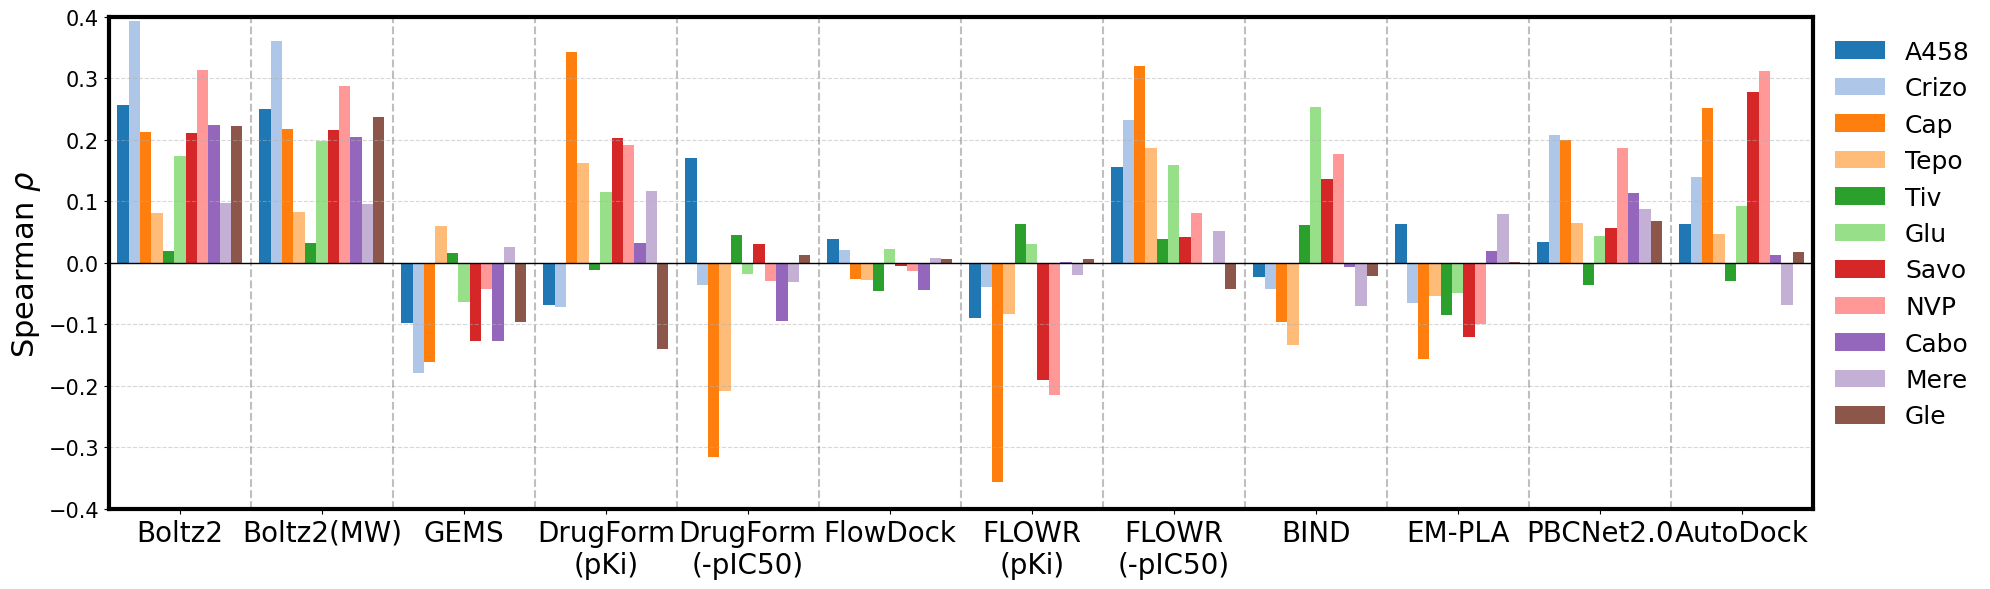

In [16]:
df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'Boltz2_mw_aff', 'gems_aff',
        'drugform_pKi_aff', 'drugform_lgIC50_aff',
       'flowdock_aff', 'flowr_pKi_aff', 'flowr_lgIC50_aff', 
       'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'autodock_ddg']

exp_name = ['Boltz2', 'Boltz2(MW)', 'GEMS',
       'DrugForm\n(pKi)', 'DrugForm\n(-pIC50)',
       'FlowDock', 'FLOWR\n(pKi)', 'FLOWR\n(-pIC50)', 'BIND', 'EM-PLA', 'PBCNet2.0', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']
colors = sns.color_palette("tab20", n_colors=len(df['key'].unique()))

fig, ax = plt.subplots(figsize=(20, 6))

for i, key in enumerate(df['key'].unique()):
    key_df = df[(df['key'].isin([key]))& (df['binding_region_label'])]
    print(len(key_df) )
    data = {}
    for model_name in exps:
        if model_name == 'autodock_ddg':
            key_df = key_df.dropna(subset=[model_name])

        pred_val = (key_df[f'{model_name}'].values)
        exp_val = key_df['mean'].values - key_df['mean_ctrl'].values
        data[model_name] = spearmanr(exp_val, pred_val).correlation

    # make bar plot for each key with offset
    ax.bar(np.arange(len(data)) + i * 0.08, list(data.values()), width=0.08, label=key if key != 'Camp' else 'Cap', color=colors[i])
# draw vertical lines to separate models
for j in range(len(exps)-1):
    ax.axvline(j + .9, color='grey', linestyle='--', alpha=0.5)

for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_linewidth(3)

ax.axhline(0, color='black', linestyle='-', linewidth=1)
ax.set_xticks(np.arange(len(exps)) + 0.4)
ax.set_xticklabels(exp_name, rotation=0, ha='center', rotation_mode='anchor', fontsize=20)
ax.set_ylabel('Spearman $\\rho$', fontsize=22)
# set yticks fontsize
ax.tick_params(axis='y', labelsize=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
# move y label to the right
ax.set_xlim(-0.1, len(exps) - 0.1)
ax.set_ylim(-.4, .4)
# no frame for legend
ax.legend(bbox_to_anchor=(1.0, 1), loc='upper left', fontsize=18, frameon=False)

plt.tight_layout()

plt.show()


5434
5434
5434
5434
5434
5434
5434
5434
5434
5434
5434
493
410
391
429
322
448
411
410
531
529
531


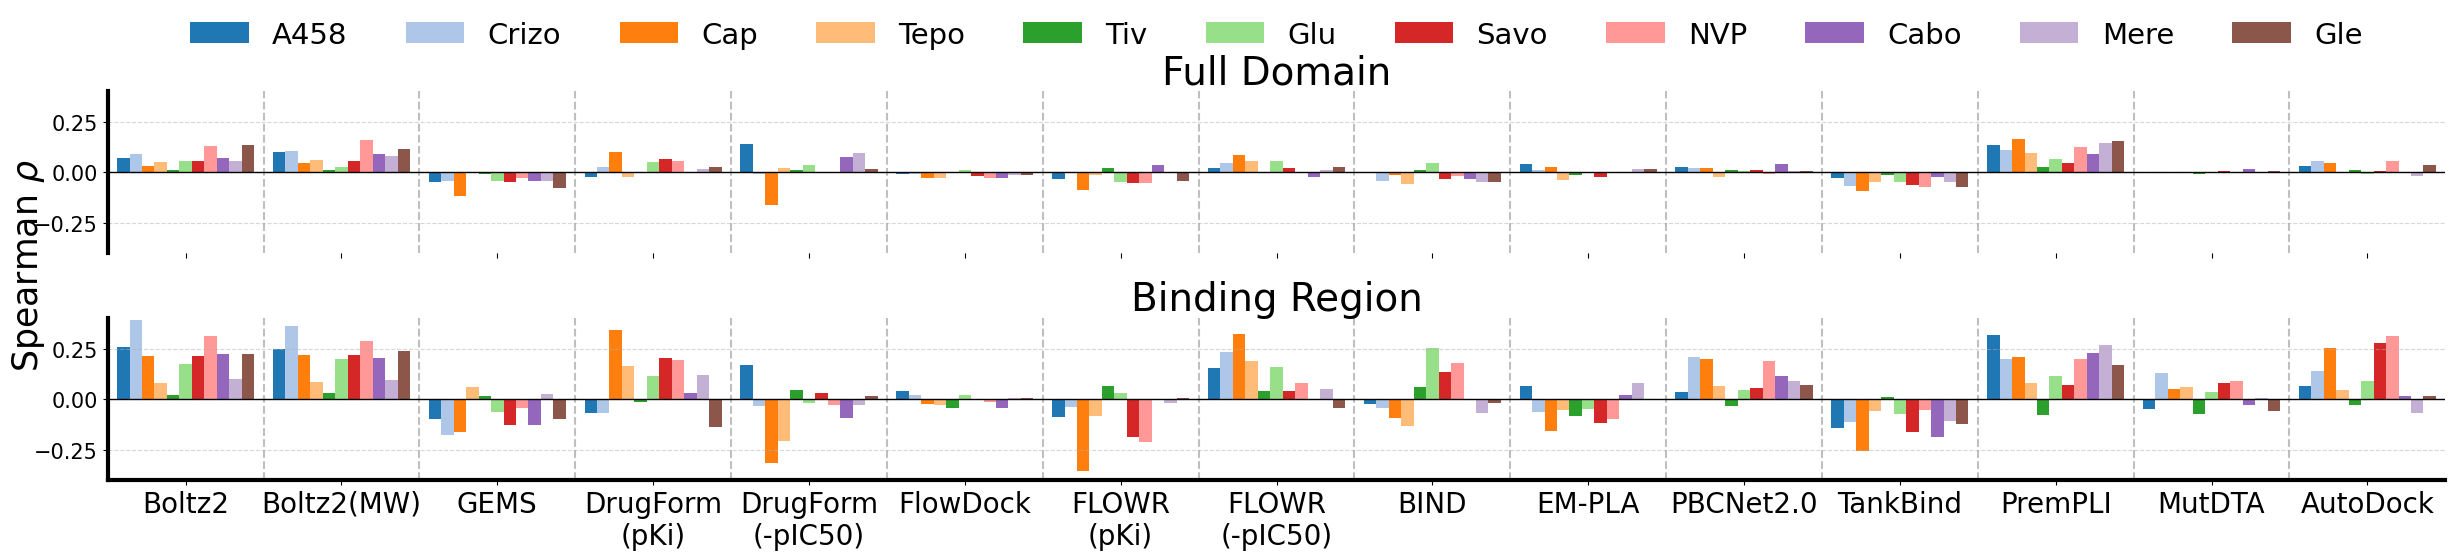

In [15]:
df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'Boltz2_mw_aff', 'gems_aff',
        'drugform_pKi_aff', 'drugform_lgIC50_aff',
       'flowdock_aff', 'flowr_pKi_aff', 'flowr_lgIC50_aff', 
       'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'TankBind_aff', 'PremPLI_ddG', 'MutDTA_ddG', 'autodock_ddg']

exp_name = ['Boltz2', 'Boltz2(MW)', 'GEMS',
       'DrugForm\n(pKi)', 'DrugForm\n(-pIC50)',
       'FlowDock', 'FLOWR\n(pKi)', 'FLOWR\n(-pIC50)', 'BIND', 'EM-PLA', 'PBCNet2.0', 'TankBind', 'PremPLI', 'MutDTA', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']
colors = sns.color_palette("tab20", n_colors=len(df['key'].unique()))

fig, axs = plt.subplots(2, 1, figsize=(26, 6))

for i, key in enumerate(df['key'].unique()):
    key_df = df[(df['key'].isin([key]))]
    print(len(key_df) )
    data = {}
    for model_name in exps:
        if model_name == 'autodock_ddg':
            key_df = key_df.dropna(subset=[model_name])

        pred_val = (key_df[f'{model_name}'].values)
        exp_val = key_df['mean'].values - key_df['mean_ctrl'].values
        data[model_name] = spearmanr(exp_val, pred_val).correlation

    # make bar plot for each key with offset
    axs[0].bar(np.arange(len(data)) + i * 0.08, list(data.values()), width=0.08, label=key if key != 'Camp' else 'Cap', color=colors[i])
# draw vertical lines to separate models
for j in range(len(exps)-1):
    axs[0].axvline(j + .9, color='grey', linestyle='--', alpha=0.5)

for spine in ['top', 'right', 'bottom', 'left']:
    axs[0].spines[spine].set_linewidth(3)

for spine in ['top', 'right', 'bottom']:
    axs[0].spines[spine].set_visible(False)

axs[0].axhline(0, color='black', linestyle='-', linewidth=1)
axs[0].set_xticks(np.arange(len(exps)) + 0.4)
axs[0].set_xticklabels([], )
# set yticks fontsize
axs[0].tick_params(axis='y', labelsize=15)
axs[0].grid(axis='y', linestyle='--', alpha=0.5)
axs[0].set_title('Full Domain', fontsize=28)
# move y label to the right
axs[0].set_xlim(-0.1, len(exps) - 0.1)
axs[0].set_ylim(-.4, .4)
# no frame for legend
axs[0].legend(bbox_to_anchor=(0.5, 1.6), loc='upper center', fontsize=21, frameon=False, ncol=13)

for i, key in enumerate(df['key'].unique()):
    key_df = df[(df['key'].isin([key]))& (df['binding_region_label'])]
    print(len(key_df) )
    data = {}
    for model_name in exps:
        if model_name == 'autodock_ddg':
            key_df = key_df.dropna(subset=[model_name])

        pred_val = (key_df[f'{model_name}'].values)
        exp_val = key_df['mean'].values - key_df['mean_ctrl'].values
        data[model_name] = spearmanr(exp_val, pred_val).correlation

    # make bar plot for each key with offset
    axs[1].bar(np.arange(len(data)) + i * 0.08, list(data.values()), width=0.08, label=key if key != 'Camp' else 'Cap', color=colors[i])
# draw vertical lines to separate models
for j in range(len(exps)-1):
    axs[1].axvline(j + .9, color='grey', linestyle='--', alpha=0.5)

for spine in ['top', 'right', 'bottom', 'left']:
    axs[1].spines[spine].set_linewidth(3)

axs[1].axhline(0, color='black', linestyle='-', linewidth=1)
axs[1].set_xticks(np.arange(len(exps)) + 0.4)
axs[1].set_xticklabels(exp_name, rotation=0, ha='center', rotation_mode='anchor', fontsize=20)
# set yticks fontsize
axs[1].tick_params(axis='y', labelsize=15)
axs[1].grid(axis='y', linestyle='--', alpha=0.5)
# move y label to the right
axs[1].set_xlim(-0.1, len(exps) - 0.1)
axs[1].set_ylim(-.4, .4)
axs[1].set_title('Binding Region', fontsize=28)
# no frame for legend

for spine in ['top', 'right']:
    axs[1].spines[spine].set_visible(False)
# add padding to ylabel
fig.supylabel('Spearman $\\rho$', fontsize=25, x=0.03, y=0.5, ha='center', va='center')

plt.tight_layout()

plt.show()


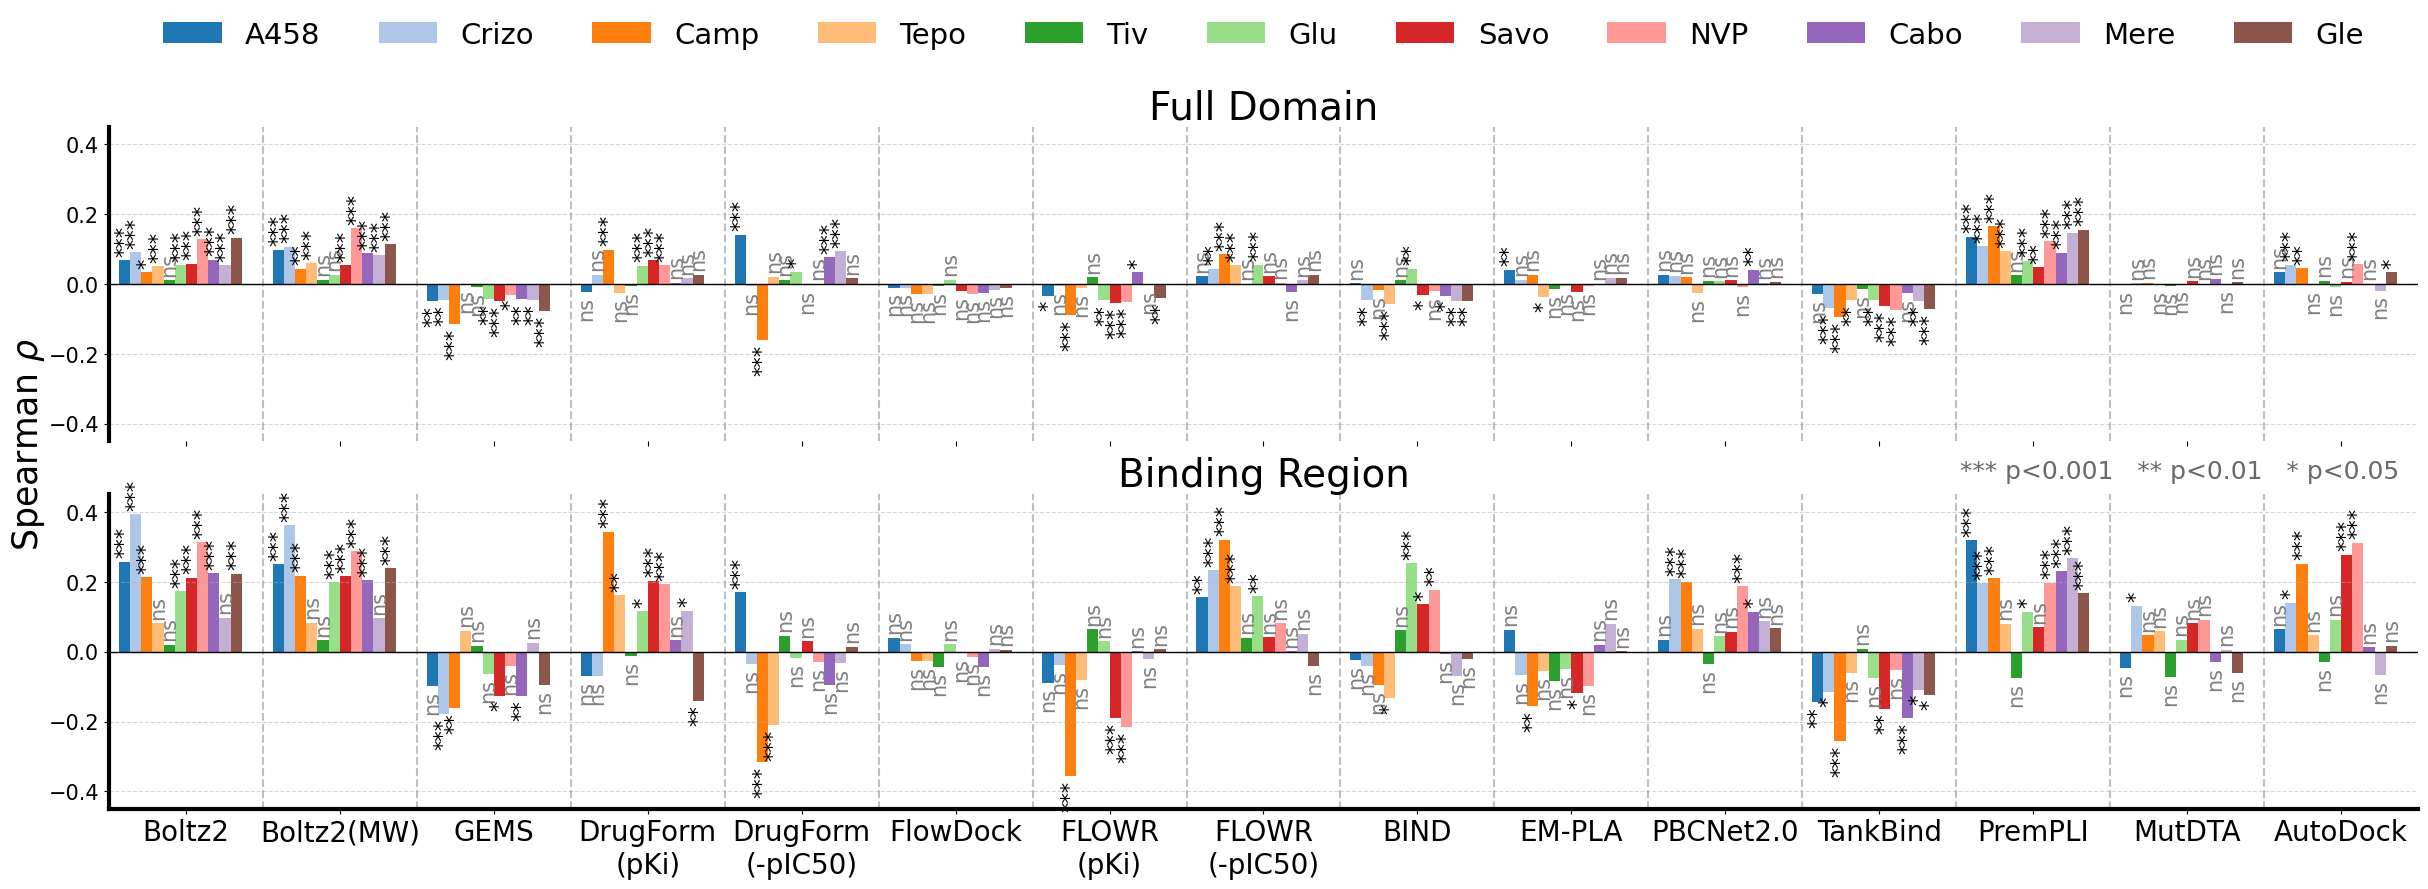

In [99]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'Boltz2_mw_aff', 'gems_aff',
        'drugform_pKi_aff', 'drugform_lgIC50_aff',
        'flowdock_aff', 'flowr_pKi_aff', 'flowr_lgIC50_aff',
        'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'TankBind_aff', 'PremPLI_ddG', 'MutDTA_ddG', 'autodock_ddg']
exp_name = ['Boltz2', 'Boltz2(MW)', 'GEMS',
            'DrugForm\n(pKi)', 'DrugForm\n(-pIC50)',
            'FlowDock', 'FLOWR\n(pKi)', 'FLOWR\n(-pIC50)', 'BIND', 'EM-PLA',
            'PBCNet2.0', 'TankBind', 'PremPLI', 'MutDTA', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']          # DMSO is the control -> mean-mean_ctrl is identically 0

KEYS = df.key.unique()
ALPHA = 0.05
W     = 0.8 / len(KEYS)
colors = sns.color_palette("tab20", n_colors=len(KEYS))

def stars(p):
    if not np.isfinite(p): return ''
    return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < ALPHA else 'ns'

# ---------- stats: one Spearman (rho, p) per bar, BH-FDR across all 180 ----------
rows = []
for panel, br in [('Full Domain', False), ('Binding Region', True)]:
    for key in KEYS:
        sel = df['key'] == key
        if br: sel &= df['binding_region_label']
        k = df[sel]
        exp_val = k['mean'].values - k['mean_ctrl'].values
        for m in exps:
            pred = k[m].values
            msk = ~np.isnan(pred) & ~np.isnan(exp_val)
            r = spearmanr(exp_val[msk], pred[msk]) if msk.sum() >= 3 else None
            rows.append(dict(panel=panel, key=key, model=m, n=int(msk.sum()),
                             rho=r.correlation if r else np.nan,
                             p_raw=r.pvalue if r else np.nan))
stats = pd.DataFrame(rows)
ok = stats['p_raw'].notna()
stats['p_adj'] = np.nan
stats.loc[ok, 'p_adj'] = multipletests(stats.loc[ok, 'p_raw'], method='fdr_bh')[1]
stats['sig'] = stats['p_adj'].map(stars)

# ---------- plot ----------
fig, axs = plt.subplots(2, 1, figsize=(26, 9))
for ax, panel in zip(axs, ['Full Domain', 'Binding Region']):
    sub = stats[stats.panel == panel].set_index(['key', 'model'])
    for i, key in enumerate(KEYS):
        vals = np.array([sub.loc[(key, m), 'rho'] for m in exps], float)
        sg   = [sub.loc[(key, m), 'sig'] for m in exps]
        x = np.arange(len(exps)) + i * W
        ax.bar(x, vals, width=W, label=key if panel == 'Full Domain' else None, color=colors[i])
        for xi, v, s in zip(x, vals, sg):
            if not np.isfinite(v) or s == '': continue
            up = v >= 0
            ax.text(xi, v + (0.012 if up else -0.012), s, rotation=90, fontsize=15,
                    ha='center', va='bottom' if up else 'top',
                    color='black' if s != 'ns' else 'grey')
    for j in range(len(exps) - 1):
        ax.axvline(j + .9, color='grey', linestyle='--', alpha=0.5)
    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    for spine in ['top', 'right', 'bottom', 'left']: ax.spines[spine].set_linewidth(3)
    for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
    ax.set_xticks(np.arange(len(exps)) + 0.4)
    ax.tick_params(axis='y', labelsize=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_xlim(-0.1, len(exps) - 0.1)
    ax.set_ylim(-.45, .45)
    ax.set_yticks([-0.4, -0.2, 0.0, 0.2, 0.4])
    ax.set_title(panel, fontsize=28)

axs[0].spines['bottom'].set_visible(False)
axs[0].set_xticklabels([])
axs[1].set_xticklabels(exp_name, rotation=0, ha='center', rotation_mode='anchor', fontsize=20)
axs[0].legend(bbox_to_anchor=(0.5, 1.42), loc='upper center', fontsize=21, frameon=False, ncol=13)
fig.supylabel('Spearman $\\rho$', fontsize=25, x=0.035, y=0.5, ha='center', va='center')
fig.text(0.95, 0.47, '*** p<0.001   ** p<0.01   * p<0.05 ',
         fontsize=18, color='dimgrey', rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()


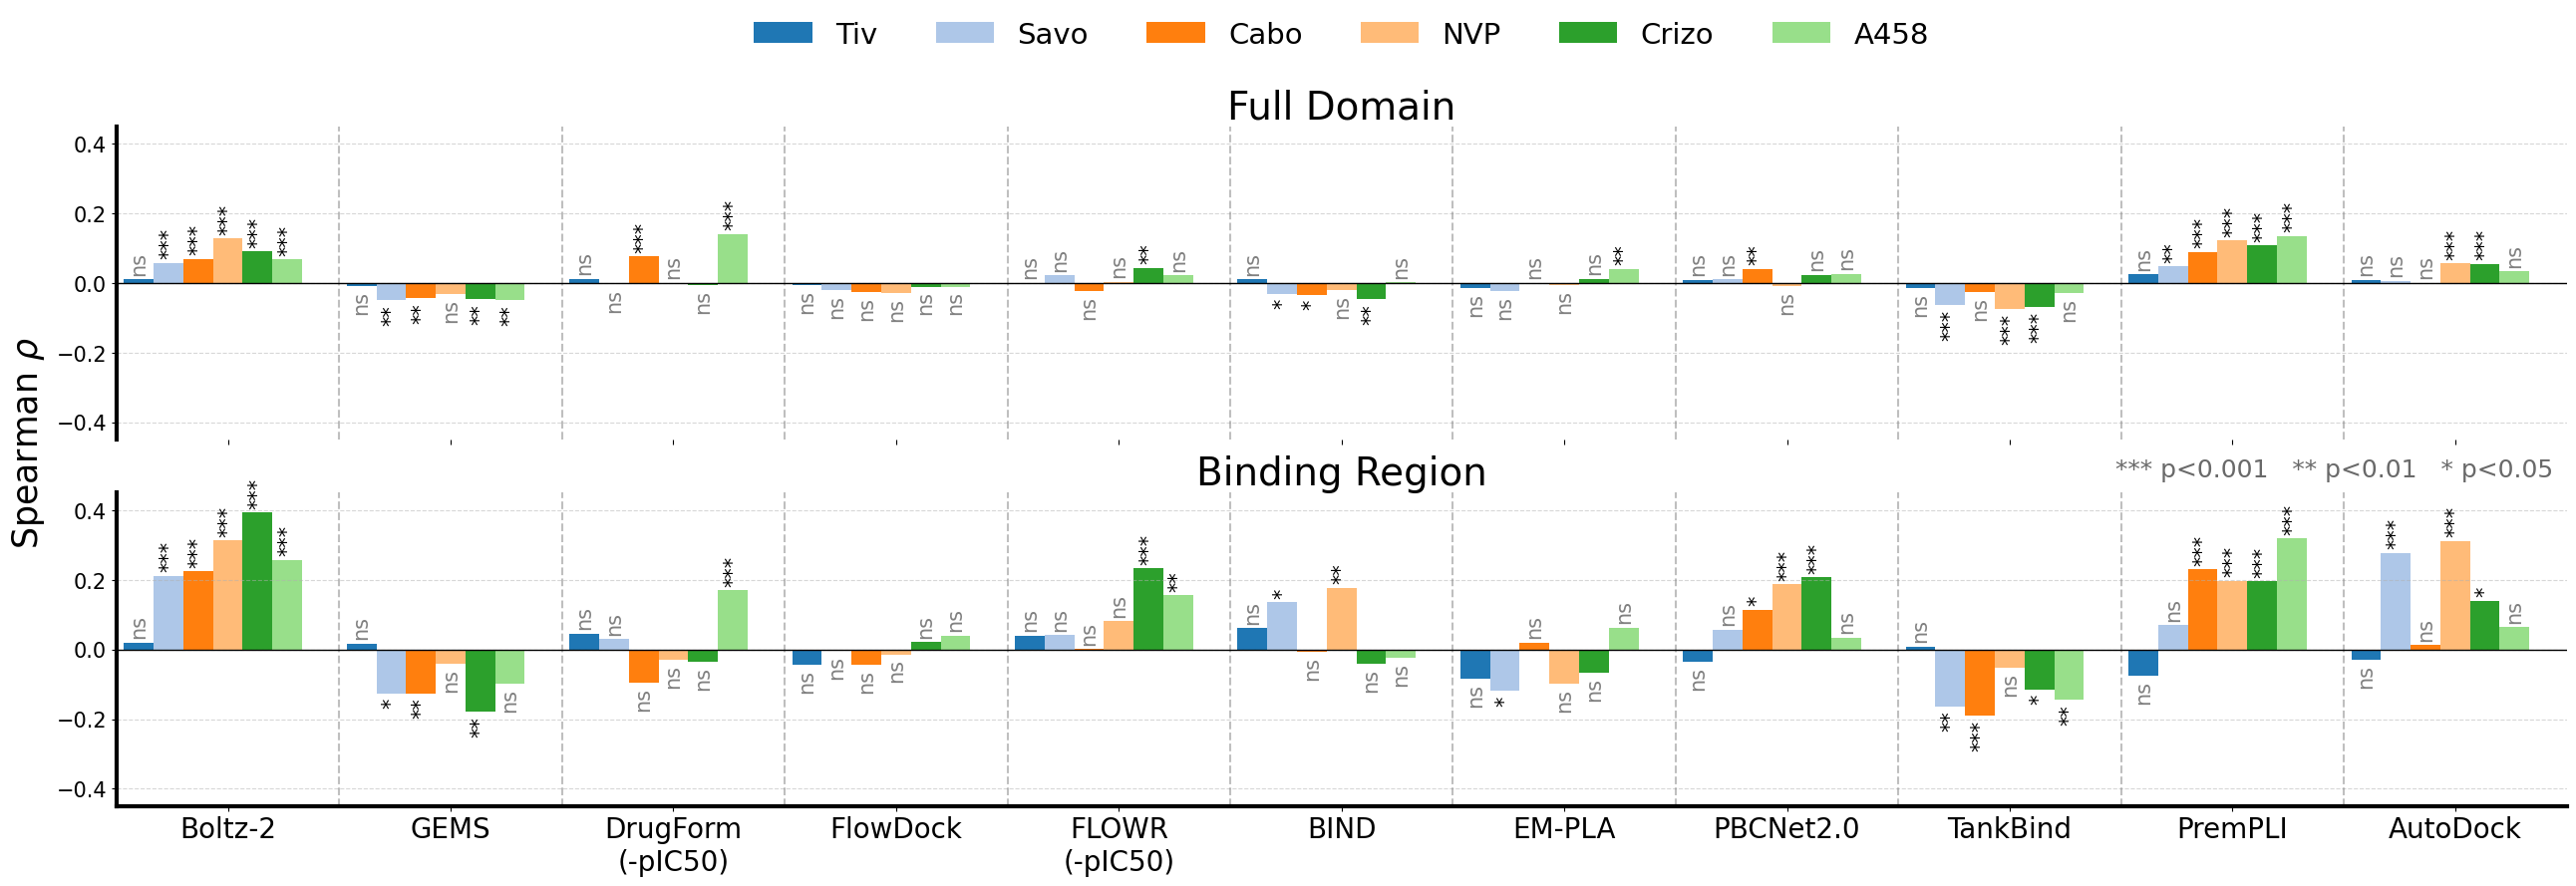

In [100]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'gems_aff',
        'drugform_lgIC50_aff',
        'flowdock_aff', 'flowr_lgIC50_aff',
        'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'TankBind_aff', 'PremPLI_ddG', 'autodock_ddg']
exp_name = ['Boltz-2', 'GEMS',
            'DrugForm\n(-pIC50)',
            'FlowDock',  'FLOWR\n(-pIC50)', 'BIND', 'EM-PLA',
            'PBCNet2.0', 'TankBind', 'PremPLI', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']          # DMSO is the control -> mean-mean_ctrl is identically 0

KEYS  = ['Tiv', 'Savo', 'Cabo', 'NVP', 'Crizo', 'A458']
ALPHA = 0.05
W     = 0.8 / len(KEYS)
colors = sns.color_palette("tab20", n_colors=len(KEYS))

def stars(p):
    if not np.isfinite(p): return ''
    return '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < ALPHA else 'ns'

# ---------- stats: one Spearman (rho, p) per bar, BH-FDR across all 180 ----------
rows = []
for panel, br in [('Full Domain', False), ('Binding Region', True)]:
    for key in KEYS:
        sel = df['key'] == key
        if br: sel &= df['binding_region_label']
        k = df[sel]
        exp_val = k['mean'].values - k['mean_ctrl'].values
        for m in exps:
            pred = k[m].values
            msk = ~np.isnan(pred) & ~np.isnan(exp_val)
            r = spearmanr(exp_val[msk], pred[msk]) if msk.sum() >= 3 else None
            rows.append(dict(panel=panel, key=key, model=m, n=int(msk.sum()),
                             rho=r.correlation if r else np.nan,
                             p_raw=r.pvalue if r else np.nan))
stats = pd.DataFrame(rows)
ok = stats['p_raw'].notna()
stats['p_adj'] = np.nan
stats.loc[ok, 'p_adj'] = multipletests(stats.loc[ok, 'p_raw'], method='fdr_bh')[1]
stats['sig'] = stats['p_adj'].map(stars)

# ---------- plot ----------
fig, axs = plt.subplots(2, 1, figsize=(26, 9))
for ax, panel in zip(axs, ['Full Domain', 'Binding Region']):
    sub = stats[stats.panel == panel].set_index(['key', 'model'])
    for i, key in enumerate(KEYS):
        vals = np.array([sub.loc[(key, m), 'rho'] for m in exps], float)
        sg   = [sub.loc[(key, m), 'sig'] for m in exps]
        x = np.arange(len(exps)) + i * W
        ax.bar(x, vals, width=W, label=key if panel == 'Full Domain' else None, color=colors[i])
        for xi, v, s in zip(x, vals, sg):
            if not np.isfinite(v) or s == '': continue
            up = v >= 0
            ax.text(xi, v + (0.012 if up else -0.012), s, rotation=90, fontsize=15,
                    ha='center', va='bottom' if up else 'top',
                    color='black' if s != 'ns' else 'grey')
    for j in range(len(exps) - 1):
        ax.axvline(j + .9, color='grey', linestyle='--', alpha=0.5)
    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    for spine in ['top', 'right', 'bottom', 'left']: ax.spines[spine].set_linewidth(3)
    for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
    ax.set_xticks(np.arange(len(exps)) + 0.4)
    ax.tick_params(axis='y', labelsize=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_xlim(-0.1, len(exps) - 0.1)
    ax.set_ylim(-.45, .45)
    ax.set_yticks([-0.4, -0.2, 0.0, 0.2, 0.4])
    ax.set_title(panel, fontsize=28)

axs[0].spines['bottom'].set_visible(False)
axs[0].set_xticklabels([])
axs[1].set_xticklabels(exp_name, rotation=0, ha='center', rotation_mode='anchor', fontsize=20)
axs[0].legend(bbox_to_anchor=(0.5, 1.42), loc='upper center', fontsize=21, frameon=False, ncol=13)
fig.supylabel('Spearman $\\rho$', fontsize=25, x=0.015, y=0.5, ha='center', va='center')
fig.text(0.992, 0.47, '*** p<0.001   ** p<0.01   * p<0.05 ',
         fontsize=18, color='dimgrey', rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()


97
142
60
66
97
35
18
11
87
56
95


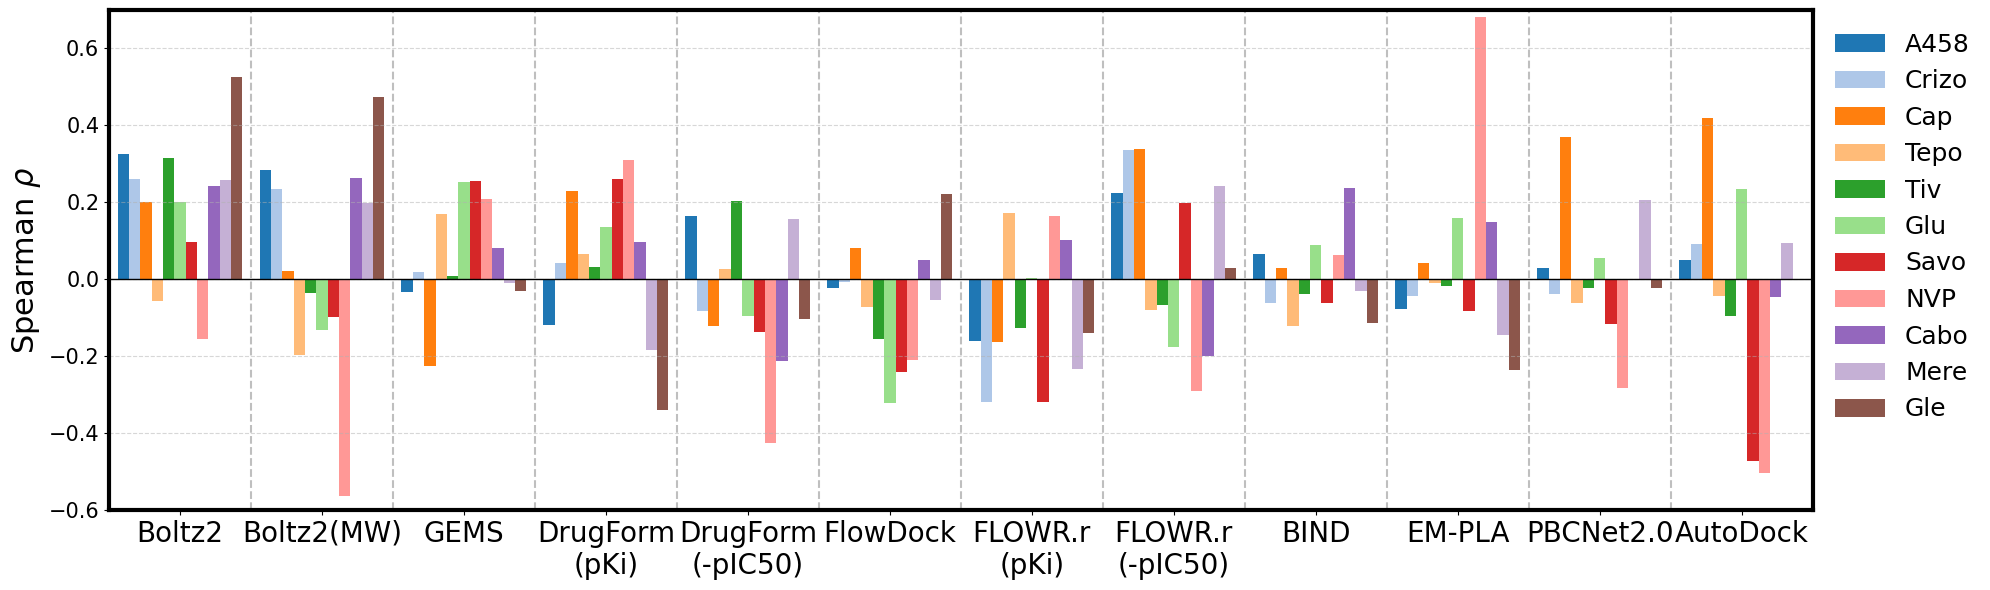

In [10]:
df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'Boltz2_mw_aff', 'gems_aff',
        'drugform_pKi_aff', 'drugform_lgIC50_aff',
       'flowdock_aff', 'flowr_pKi_aff', 'flowr_lgIC50_aff', 
       'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'autodock_ddg']

exp_name = ['Boltz2', 'Boltz2(MW)', 'GEMS',
       'DrugForm\n(pKi)', 'DrugForm\n(-pIC50)',
       'FlowDock', 'FLOWR.r\n(pKi)', 'FLOWR.r\n(-pIC50)', 'BIND', 'EM-PLA', 'PBCNet2.0', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']
colors = sns.color_palette("tab20", n_colors=len(df['key'].unique()))

fig, ax = plt.subplots(figsize=(20, 6))

for i, key in enumerate(df['key'].unique()):
    if key == 'DMSO': continue
    key_df = df[(df['key'].isin([key]))& (df['label_resisted'])]
    print(len(key_df) )
    data = {}
    for model_name in exps:
        if model_name == 'autodock_ddg':
            key_df = key_df.dropna(subset=[model_name])

        pred_val = (key_df[f'{model_name}'].values)
        exp_val = key_df['mean'].values - key_df['mean_ctrl'].values
        data[model_name] = spearmanr(exp_val, pred_val).correlation

    # make bar plot for each key with offset
    ax.bar(np.arange(len(data)) + i * 0.08, list(data.values()), width=0.08, label=key if key != 'Camp' else 'Cap', color=colors[i])
# draw vertical lines to separate models
for j in range(len(exps)-1):
    ax.axvline(j + .9, color='grey', linestyle='--', alpha=0.5)

for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_linewidth(3)

ax.axhline(0, color='black', linestyle='-', linewidth=1)
ax.set_xticks(np.arange(len(exps)) + 0.4)
ax.set_xticklabels(exp_name, rotation=0, ha='center', rotation_mode='anchor', fontsize=20)
ax.set_ylabel('Spearman $\\rho$', fontsize=22)
# set yticks fontsize
ax.tick_params(axis='y', labelsize=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)
# move y label to the right
ax.set_xlim(-0.1, len(exps) - 0.1)
ax.set_ylim(-.6, .7)
# no frame for legend
ax.legend(bbox_to_anchor=(1.0, 1), loc='upper left', fontsize=18, frameon=False)

plt.tight_layout()

plt.show()


/tmp/ipykernel_2842707/2887258824.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels(exp_name, rotation=30, ha='center', fontsize=20)


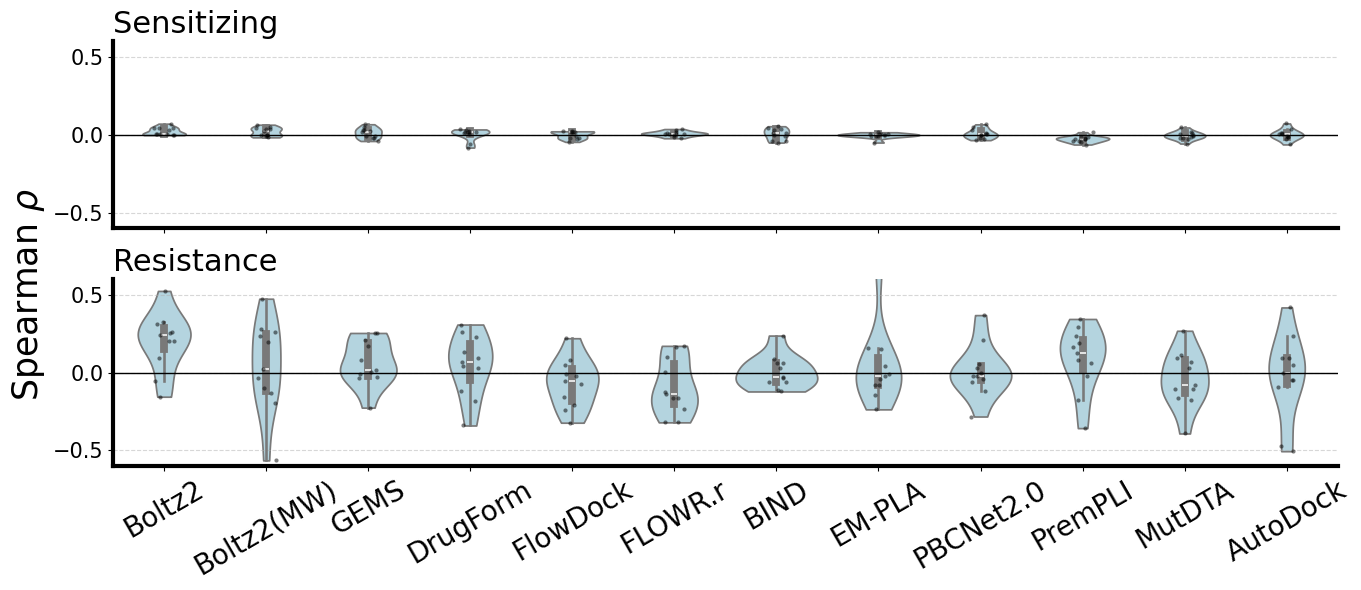

In [5]:
df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'Boltz2_mw_aff', 'gems_aff',
        'drugform_pKi_aff', 
        'flowdock_aff', 'flowr_pKi_aff', 
        'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'PremPLI_ddG', 'MutDTA_ddG', 'autodock_ddg']
exp_name = ['Boltz2', 'Boltz2(MW)', 'GEMS',
            'DrugForm', 
            'FlowDock', 'FLOWR.r', 'BIND', 'EM-PLA', 'PBCNet2.0', 'PremPLI', 'MutDTA', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']

# ---- build a long table of per-key Spearman rho for one mask column ----
def rho_table(mask_col):
    rows = []
    for key in df['key'].unique():
        key_df = df[(df['key'] == key) & (df[mask_col])]
        exp_val = key_df['mean'].values - key_df['mean_ctrl'].values
        for model_name in exps:
            pred_val = key_df[model_name].values
            m = ~np.isnan(pred_val) & ~np.isnan(exp_val)
            rho = spearmanr(exp_val[m], pred_val[m]).correlation if m.sum() >= 3 else np.nan
            rows.append({'model': model_name, 'key': key, 'rho': rho})
    return pd.DataFrame(rows).dropna(subset=['rho'])

fig, axs = plt.subplots(2, 1, figsize=(14, 6))

for ax, mask_col, title in [(axs[1], 'label_resisted', 'Resistance'),
                            (axs[0], 'label_sensitized', 'Sensitizing')]:
    tbl = rho_table(mask_col)
    sns.violinplot(data=tbl, x='model', y='rho', order=exps,
                   color='lightblue', inner='box', cut=0, ax=ax)
    sns.stripplot(data=tbl, x='model', y='rho', order=exps,
                  color='black', size=3, alpha=0.5, ax=ax)
    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_ylim(-.6, .6)
    ax.tick_params(axis='y', labelsize=15)
    ax.set_title(title, fontsize=22, loc='left')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_linewidth(3)

# only label the methods on the bottom subplot
axs[0].set_xticklabels([])
axs[1].set_xticklabels(exp_name, rotation=30, ha='center', fontsize=20)

fig.supylabel('Spearman $\\rho$', fontsize=25, x=0.04, y=0.5, ha='center', va='center')
plt.tight_layout()
plt.show()


/tmp/ipykernel_1939120/3063579007.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct = (sub.groupby(['key', 'dbin']).size().unstack(fill_value=0)
/tmp/ipykernel_1939120/3063579007.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct = (sub.groupby(['key', 'dbin']).size().unstack(fill_value=0)


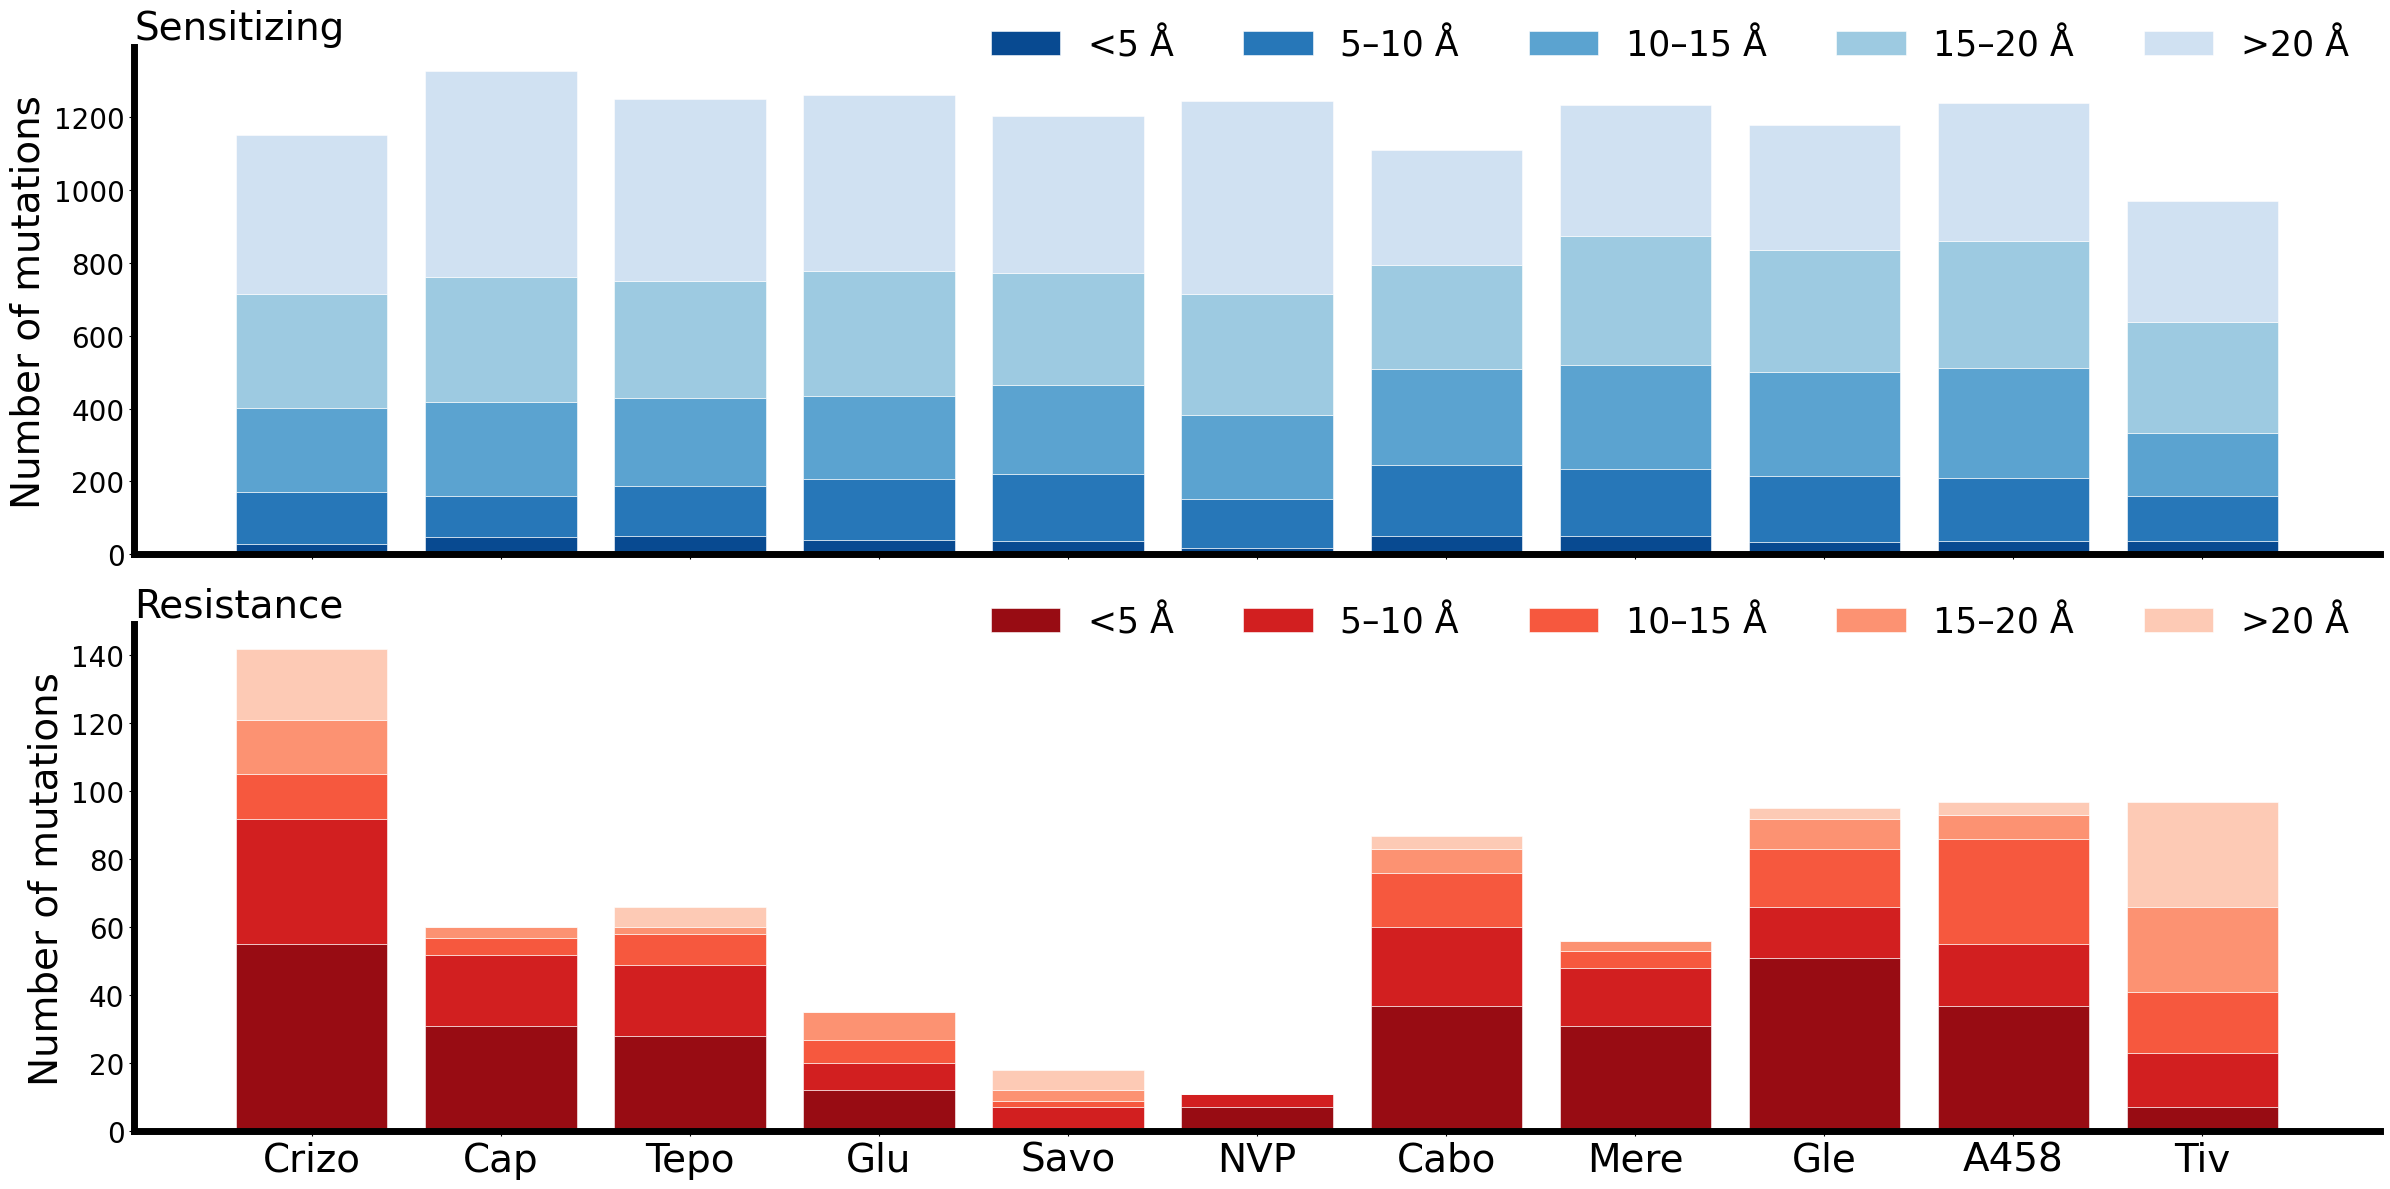

In [30]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../MET_unfiltered.csv')
df = df[df['key'] != 'DMSO'].copy()

# distance shells
EDGES = [0, 5, 10, 15, 20, np.inf]
LABELS = ['<5 Å', '5–10 Å', '10–15 Å', '15–20 Å', '>20 Å']
df['dbin'] = pd.cut(df['min_dist'], bins=EDGES, labels=LABELS, right=False)

ORDER = ['Crizo','Camp','Tepo','Glu','Savo','NVP','Cabo','Mere','Gle','A458','Tiv']
keys = [k for k in ORDER if k in set(df['key'])]

# gradient colors: near = dark, far = light (one per shell)
res_colors = plt.cm.Reds(np.linspace(0.9, 0.2, len(LABELS)))
sen_colors = plt.cm.Blues(np.linspace(0.9, 0.2, len(LABELS)))

panels = [('Sensitizing', 'label_sensitized', sen_colors),
          ('Resistance', 'label_resisted', res_colors),
          ]

fig, axs = plt.subplots(2, 1, figsize=(24, 12.), sharex=True)
x = np.arange(len(keys))
for ax, (name, col, cols) in zip(axs, panels):
    sub = df[df[col].astype(bool)]
    # counts per (key, distance shell)
    ct = (sub.groupby(['key', 'dbin']).size().unstack(fill_value=0)
             .reindex(index=keys, columns=LABELS, fill_value=0))
    bottom = np.zeros(len(keys))
    for j, lab in enumerate(LABELS):
        ax.bar(x, ct[lab].values, bottom=bottom, color=cols[j],
               edgecolor='white', lw=0.4, label=lab)
        bottom += ct[lab].values
    ax.set_ylabel('Number of mutations', fontsize=28)
    ax.set_title(name, fontsize=28, loc='left')
    ax.tick_params(axis='y', labelsize=20)
    ax.legend(frameon=False, fontsize=25,
              title_fontsize=10, loc='upper right', ncol=5, bbox_to_anchor=(1, 1.10))
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    for s in ['bottom', 'left']: ax.spines[s].set_linewidth(2)

    # thicker spines for both panels
    for s in ['bottom', 'left']:
        axs[0].spines[s].set_linewidth(5)
        axs[1].spines[s].set_linewidth(5)
axs[1].set_xticks(x)
axs[1].set_xticklabels(['Cap' if i == 'Camp' else i for i in keys], fontsize=28)
plt.tight_layout()
plt.show()


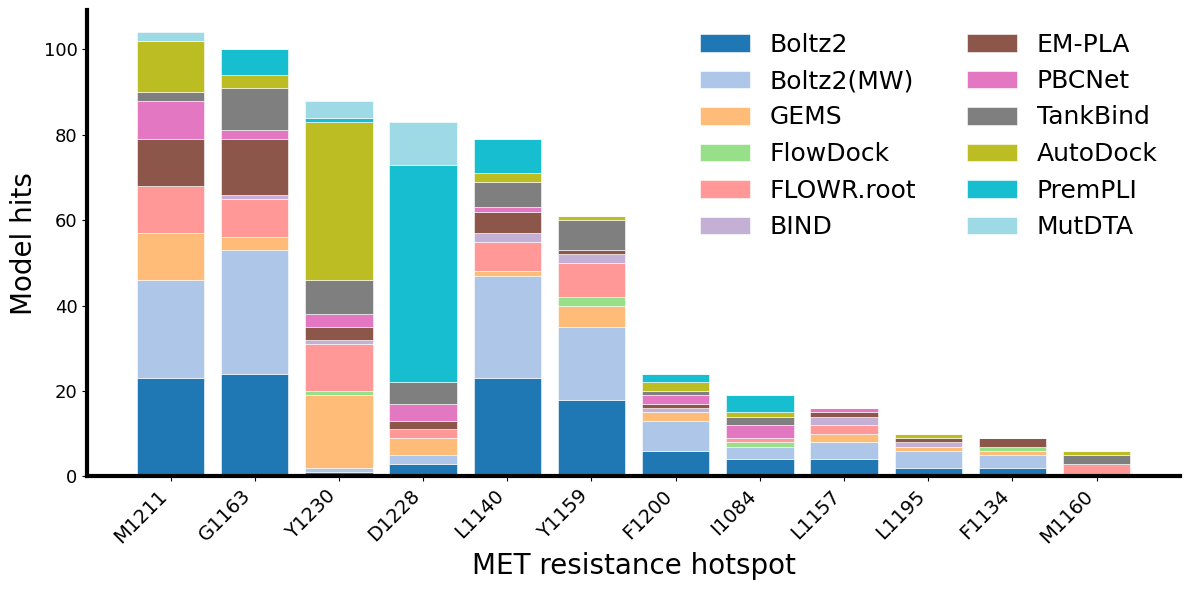

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

res = pd.read_csv('../../MET_hotspot_model_count.csv')

r = res[(res.direction == 'resistance') & (res.n_models > 0)].copy()
r['models'] = r['models'].fillna('')
long = r.assign(model=r['models'].str.split(',')).explode('model')
long = long[long['model'] != '']

piv = long.groupby(['true_pos', 'model']).size().unstack(fill_value=0)
wt_of = res.drop_duplicates('true_pos').set_index('true_pos')['wt']
piv = piv.loc[piv.sum(axis=1).sort_values(ascending=False).index]

TOP_N = 12
piv = piv.head(TOP_N)
xlabels = [f'{wt_of[p]}{p}' for p in piv.index]

# fixed model -> color mapping (11 models, needs a >=11 palette)
MODEL_ORDER = ['Boltz2', 'Boltz2(MW)', 'GEMS', 'FlowDock', 'FLOWR.root', 'BIND',
               'EM-PLA', 'PBCNet', 'TankBind', 'AutoDock', 'PremPLI', 'MutDTA']
colors = dict(zip(MODEL_ORDER, plt.cm.tab20(np.linspace(0, 1, len(MODEL_ORDER)))))
MODEL_ORDER = [m for m in MODEL_ORDER if m in piv.columns]

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(piv)); x = np.arange(len(piv))
for m in MODEL_ORDER:
    vals = piv[m].values
    ax.bar(x, vals, bottom=bottom, color=colors[m], edgecolor='white', lw=0.4, label=m)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=14)
ax.set_ylabel('Model hits', fontsize=20)
ax.set_xlabel('MET resistance hotspot', fontsize=20)
ax.tick_params(axis='y', labelsize=13)
ax.legend(title='', fontsize=18, ncol=2, loc='upper right', frameon=False)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
for s in ['bottom', 'left']: ax.spines[s].set_linewidth(3)
plt.tight_layout()
plt.show()


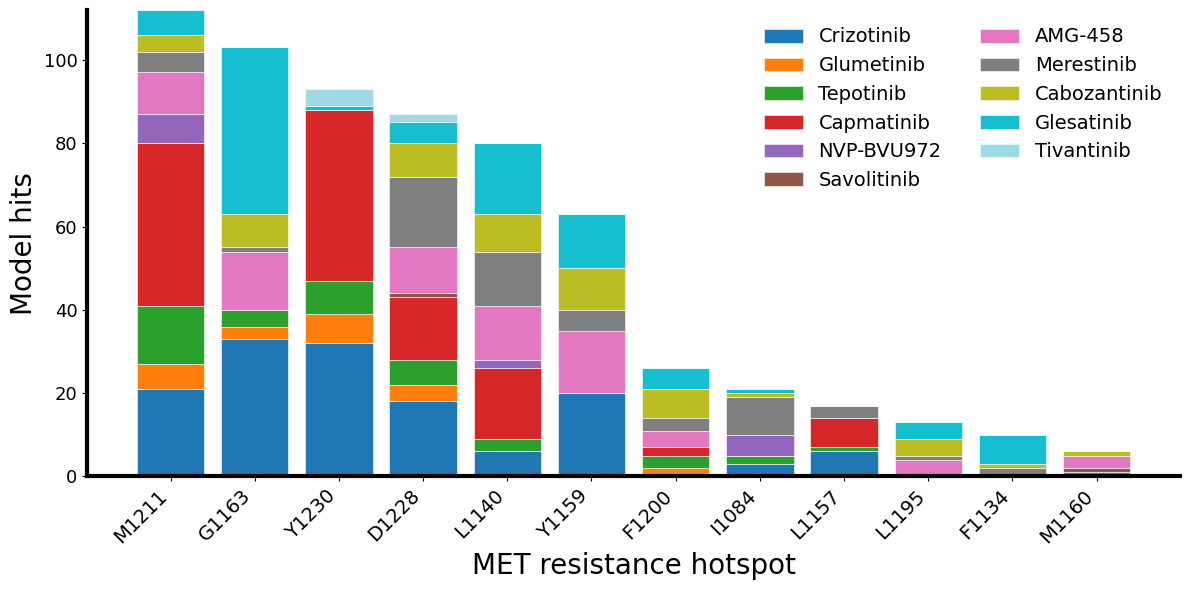

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

res = pd.read_csv('../../MET_hotspot_model_count.csv')

r = res[(res.direction == 'resistance') & (res.n_models > 0)].copy()
r['models'] = r['models'].fillna('')
long = r.assign(model=r['models'].str.split(',')).explode('model')
long = long[long['model'] != '']

# ---- stack by INHIBITOR instead of by model (same y-quantity: model hits) ----
piv = long.groupby(['true_pos', 'key']).size().unstack(fill_value=0)
wt_of = res.drop_duplicates('true_pos').set_index('true_pos')['wt']
piv = piv.loc[piv.sum(axis=1).sort_values(ascending=False).index]

TOP_N = 12
piv = piv.head(TOP_N)
xlabels = [f'{wt_of[p]}{p}' for p in piv.index]

# fixed inhibitor -> colour mapping (11 inhibitors; DMSO absent from this file)
KEY_ORDER = ['Crizo', 'Glu', 'Tepo', 'Camp', 'NVP', 'Savo',
             'A458', 'Mere', 'Cabo', 'Gle', 'Tiv']
KEY_LABEL = {'Crizo':'Crizotinib', 'Glu':'Glumetinib', 'Tepo':'Tepotinib',
             'Camp':'Capmatinib', 'NVP':'NVP-BVU972', 'Savo':'Savolitinib',
             'A458':'AMG-458', 'Mere':'Merestinib', 'Cabo':'Cabozantinib',
             'Gle':'Glesatinib', 'Tiv':'Tivantinib'}
colors = dict(zip(KEY_ORDER, plt.cm.tab20(np.linspace(0, 1, len(KEY_ORDER)))))
KEY_ORDER = [k for k in KEY_ORDER if k in piv.columns]

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(piv)); x = np.arange(len(piv))
for k in KEY_ORDER:
    vals = piv[k].values
    ax.bar(x, vals, bottom=bottom, color=colors[k], edgecolor='white', lw=0.4,
           label=KEY_LABEL[k])
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=14)
ax.set_ylabel('Model hits', fontsize=20)
ax.set_xlabel('MET resistance hotspot', fontsize=20)
ax.tick_params(axis='y', labelsize=13)
ax.legend(title='', fontsize=14, ncol=2, loc='upper right', frameon=False)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
for s in ['bottom', 'left']: ax.spines[s].set_linewidth(3)
plt.tight_layout()
plt.show()


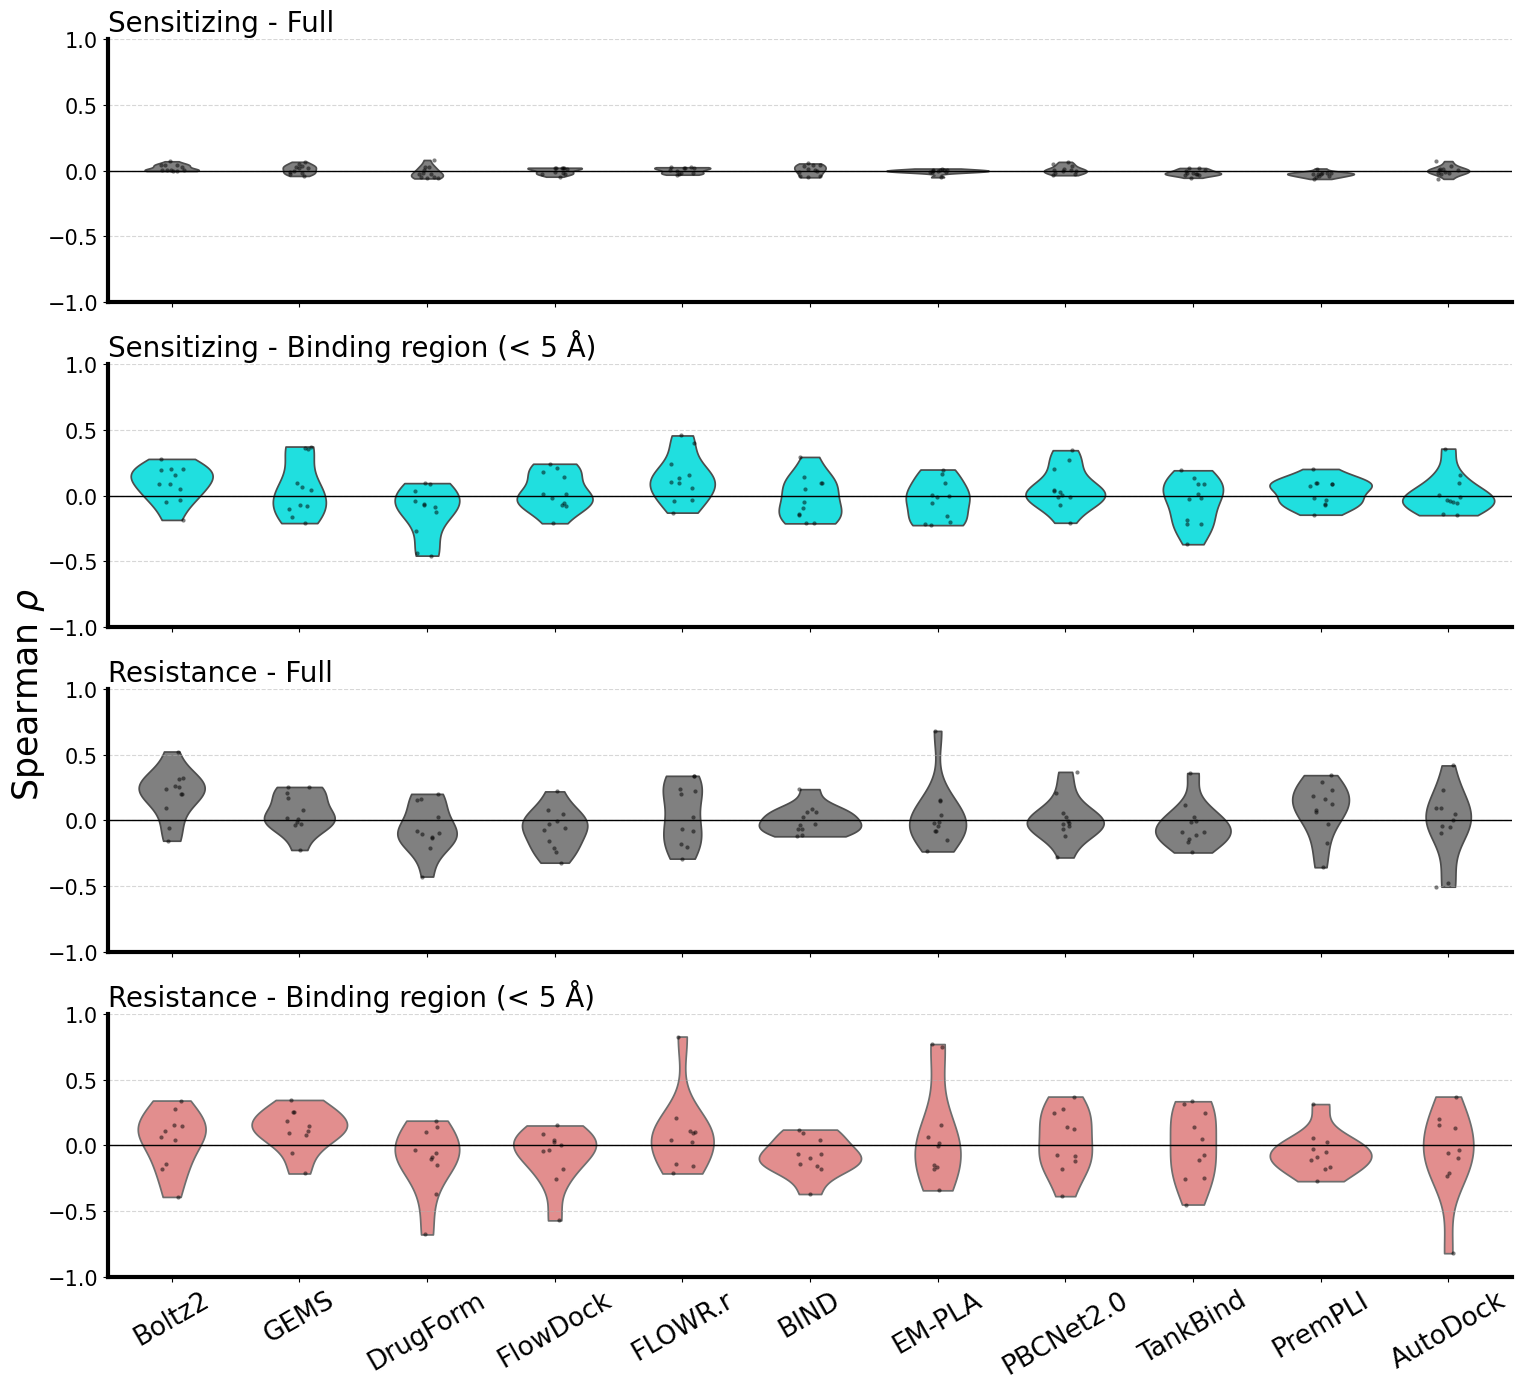

In [81]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr

df = pd.read_csv('../MET_unfiltered.csv')
exps = ['Boltz2_aff', 'gems_aff',
        'drugform_lgIC50_aff',
        'flowdock_aff', 'flowr_lgIC50_aff',
        'bind_pIC50_aff', 'em_aff', 'PBCNet_aff', 'TankBind_aff', 'PremPLI_ddG', 'autodock_ddg']
exp_name = ['Boltz2', 'GEMS', 'DrugForm', 'FlowDock', 'FLOWR.r',
            'BIND', 'EM-PLA', 'PBCNet2.0', 'TankBind', 'PremPLI', 'AutoDock']
df.dropna(subset=['mean_ctrl'], inplace=True)
df = df[df['key'] != 'DMSO']

def rho_table(mask_col, region_only):
    rows = []
    for key in df['key'].unique():
        sel = (df['key'] == key) & (df[mask_col])
        if region_only:
            sel &= df['binding_region_label']
        key_df = df[sel]
        exp_val = key_df['mean'].values - key_df['mean_ctrl'].values
        for model_name in exps:
            pred_val = key_df[model_name].values
            m = ~np.isnan(pred_val) & ~np.isnan(exp_val)
            rho = spearmanr(exp_val[m], pred_val[m]).correlation if m.sum() >= 3 else np.nan
            rows.append({'model': model_name, 'key': key, 'rho': rho})
    return pd.DataFrame(rows).dropna(subset=['rho'])

PANELS = [('label_sensitized', False, 'Sensitizing - Full',                   'grey'),
          ('label_sensitized', True,  'Sensitizing - Binding region (< 5 Å)', 'cyan'),
          ('label_resisted',   False, 'Resistance - Full',                    'grey'),
          ('label_resisted',   True,  'Resistance - Binding region (< 5 Å)',  'lightcoral')]

fig, axs = plt.subplots(4, 1, figsize=(16, 14))
for ax, (mask_col, region_only, title, color) in zip(axs, PANELS):
    tbl = rho_table(mask_col, region_only)
    sns.violinplot(data=tbl, x='model', y='rho', order=exps,
                color=color, inner=None, cut=0, ax=ax)
    sns.stripplot(data=tbl, x='model', y='rho', order=exps,
                  color='black', size=3, alpha=0.5, ax=ax)
    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_ylim(-1.0, 1.0)
    ax.tick_params(axis='y', labelsize=15)
    ax.set_title(title, fontsize=20, loc='left')
    for spine in ['top', 'right']: ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']: ax.spines[spine].set_linewidth(3)
    ax.set_xticks(range(len(exps)))
    ax.set_xticklabels([])

axs[-1].set_xticks(range(len(exps)))
axs[-1].set_xticklabels(exp_name, rotation=30, ha='center', fontsize=19)
fig.supylabel('Spearman $\\rho$', fontsize=25, x=0.06, y=0.5, ha='center', va='center')
plt.tight_layout(rect=[0.03, 0, 1, 1])
plt.show()


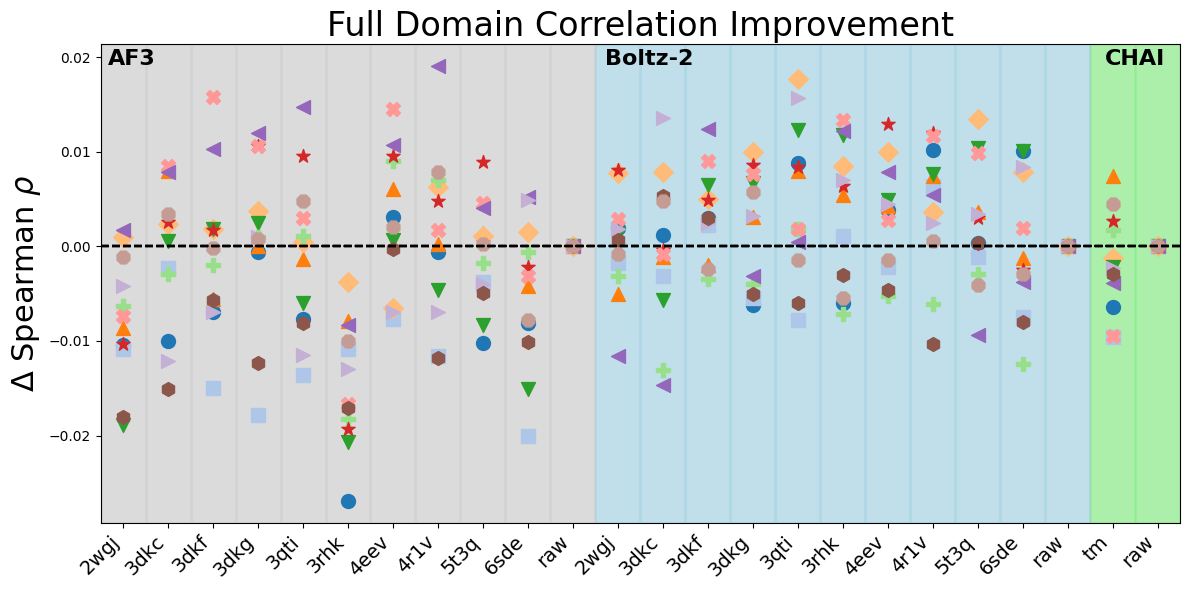

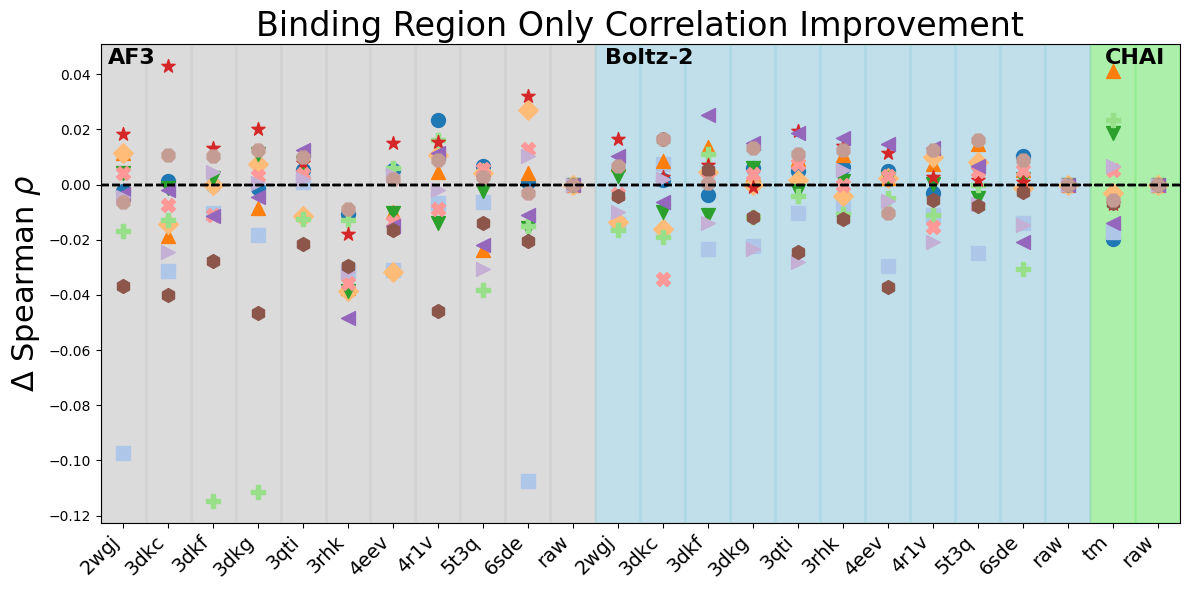

In [19]:
# ignore warnings
import warnings
warnings.filterwarnings("ignore")

df1 = pd.read_csv('../../MET_af3_models_struc_vrem.csv')

exps = ['af3_3dkg', 'af3_raw',
       'af3_3rhk', 'boltz_5t3q', 'boltz_6sde', 'boltz_4eev', 'boltz_4r1v',
       'chai_tm', 'boltz_3dkf', 'boltz_raw', 'af3_3qti', 'af3_2wgj',
       'af3_3dkc', 'chai_raw', 'boltz_2wgj', 'boltz_3qti', 'boltz_3dkc',
       'af3_3dkf', 'boltz_3rhk', 'af3_4r1v', 'af3_6sde', 'af3_5t3q',
       'af3_4eev', 'boltz_3dkg']

exps = np.sort(exps)
# swap chai_tm and chai_raw
exps = list(exps)
chai_tm_index = exps.index('chai_tm')
chai_raw_index = exps.index('chai_raw')
exps[chai_tm_index], exps[chai_raw_index] = exps[chai_raw_index], exps[chai_tm_index]
exps = np.array(exps)

fig, ax = plt.subplots(figsize=(12,6))
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', '<', '>', 'h', '8']
colors = plt.cm.tab20.colors
num_col = len(exps)
for key in df1['key'].unique():
    key_df = df1[df1['key'].isin([key])]

    # spearmanr correlation of each column
    corrs = {}
    baseline_corr = {}
    for col in exps:

        corr, _ = spearmanr(key_df['mean'], key_df[col])
        corrs[col] = corr
        if 'raw' in col:
            baseline_corr[col.split('_')[0]] = corr

    for k,v in corrs.items():
        corrs[k] = v - baseline_corr[k.split('_')[0]]

    # make scatter plot and 
    ax.scatter(range(num_col), [corrs[e] for e in exps], label=key if key != 'Camp' else 'Cap', marker=markers[list(df1['key'].unique()).index(key)%len(markers)], s=100, color=colors[list(df1['key'].unique()).index(key)%len(colors)])

    # set background color for scatter plot who has different prefix label in exps
    for i, e in enumerate(exps):
        if 'af3' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgrey', alpha=0.1, zorder=0)
        elif 'boltz' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightblue', alpha=0.1, zorder=0)
        elif 'chai' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgreen', alpha=0.1, zorder=0)
        else:
            raise ValueError('Unknown experiment type in exps')

    ax.axhline(y=0, color='black', linestyle='--')
    ax.set_xticks(ticks=range(num_col))
    ax.set_xticklabels([e.split('_')[1] for e in exps], rotation=45, ha='right', fontsize=14)
    ax.set_xlim(-0.5, num_col-0.5)

# text label indicating different experiment groups
ax.text(0.2, ax.get_ylim()[1]*0.9, 'AF3', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(11.7, ax.get_ylim()[1]*0.9, 'Boltz-2', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(22.5, ax.get_ylim()[1]*0.9, 'CHAI', fontsize=16, color='black', ha='center', fontweight='bold')
ax.set_ylabel('Δ Spearman $\\rho$', fontsize=22)
plt.title('Full Domain Correlation Improvement', fontsize=24)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(12,6))
num_col = len(exps)
for key in df1['key'].unique():
    key_df = df1[df1['key'].isin([key]) & (df1['binding_region_label'])]

    # spearmanr correlation of each column
    corrs = {}
    baseline_corr = {}
    for col in exps:

        corr, _ = spearmanr(key_df['mean'], key_df[col])
        corrs[col] = corr
        if 'raw' in col:
            baseline_corr[col.split('_')[0]] = corr

    for k,v in corrs.items():
        corrs[k] = v - baseline_corr[k.split('_')[0]]

    # make scatter plot and 
    ax.scatter(range(num_col), [corrs[e] for e in exps], label=key if key != 'Camp' else 'Cap', marker=markers[list(df1['key'].unique()).index(key)%len(markers)], s=100, color=colors[list(df1['key'].unique()).index(key)%len(colors)])

    # set background color for scatter plot who has different prefix label in exps
    for i, e in enumerate(exps):
        if 'af3' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgrey', alpha=0.1, zorder=0)
        elif 'boltz' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightblue', alpha=0.1, zorder=0)
        elif 'chai' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgreen', alpha=0.1, zorder=0)
        else:
            raise ValueError('Unknown experiment type in exps')

    ax.axhline(y=0, color='black', linestyle='--')
    ax.set_xticks(ticks=range(num_col))
    ax.set_xticklabels([e.split('_')[1] for e in exps], rotation=45, ha='right', fontsize=14)
    ax.set_xlim(-0.5, num_col-0.5)

# text label indicating different experiment groups
ax.text(0.2, ax.get_ylim()[1]*0.86, 'AF3', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(11.7, ax.get_ylim()[1]*0.86, 'Boltz-2', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(22.5, ax.get_ylim()[1]*0.86, 'CHAI', fontsize=16, color='black', ha='center', fontweight='bold')
ax.set_ylabel('Δ Spearman $\\rho$', fontsize=22)
plt.title('Binding Region Only Correlation Improvement', fontsize=24)
plt.tight_layout()


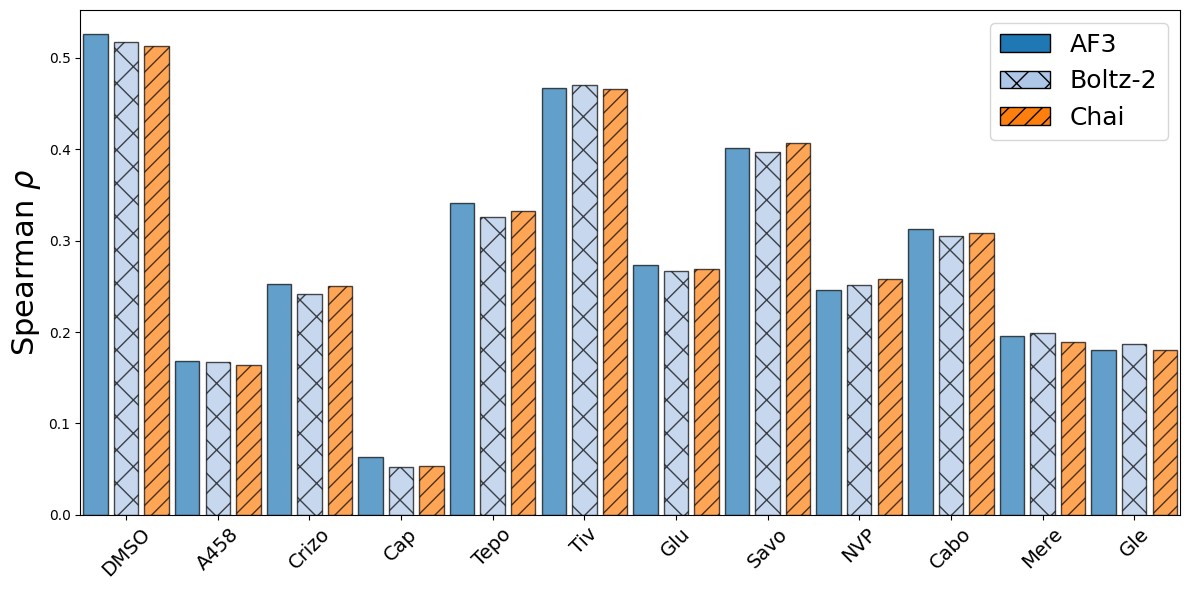

In [9]:
df1 = pd.read_csv('../../MET_af3_models_struc_vrem.csv')
exps = ['af3_3dkg', 'af3_raw',
       'af3_3rhk', 'boltz_5t3q', 'boltz_6sde', 'boltz_4eev', 'boltz_4r1v',
       'chai_tm', 'boltz_3dkf', 'boltz_raw', 'af3_3qti', 'af3_2wgj',
       'af3_3dkc', 'chai_raw', 'boltz_2wgj', 'boltz_3qti', 'boltz_3dkc',
       'af3_3dkf', 'boltz_3rhk', 'af3_4r1v', 'af3_6sde', 'af3_5t3q',
       'af3_4eev', 'boltz_3dkg']

exps = np.sort(exps)
# swap chai_tm and chai_raw
exps = list(exps)
chai_tm_index = exps.index('chai_tm')
chai_raw_index = exps.index('chai_raw')
exps[chai_tm_index], exps[chai_raw_index] = exps[chai_raw_index], exps[chai_tm_index]
exps = np.array(exps)

fig, ax = plt.subplots(figsize=(12,6))
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', '<', '>', 'h', '8']
colors = plt.cm.tab20.colors
num_col = len(exps)
for i, key in enumerate(df1['key'].unique()):
    key_df = df1[df1['key'].isin([key])]

    # spearmanr correlation of each column
    corrs = {}
    for col in exps:
        if 'raw' not in col:
            continue
        corr, _ = spearmanr(key_df['mean'], key_df[col])
        corrs[col] = corr

    # make bar plot 
    ax.bar(range(i*len(corrs), i*len(corrs)+len(corrs)), [corrs[e] for e in corrs.keys()], label=key if key != 'Camp' else 'Cap', alpha=0.7, color=colors[0:3], hatch=['', 'x', '//'], edgecolor='black')

ax.set_ylabel('Spearman $\\rho$', fontsize=22)
plt.xticks(ticks=[i*len(corrs) + len(corrs)/2 - 0.5 for i in range(len(df1['key'].unique()))], labels=[k if k != 'Camp' else 'Cap' for k in df1['key'].unique()], rotation=45, ha='center', fontsize=14)
plt.xlim(-0.5, len(df1['key'].unique())*len(corrs)-0.5)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=18)

# set first legend for different experiment groups
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors[0], hatch='', edgecolor='black', label='AF3'),
                   Patch(facecolor=colors[1], hatch='x', edgecolor='black', label='Boltz-2'),
                   Patch(facecolor=colors[2], hatch='//', edgecolor='black', label='Chai')]
ax.legend(handles=legend_elements, loc='upper right', fontsize=18)

plt.tight_layout()


In [10]:
corrs


{np.str_('af3_raw'): np.float64(0.18002417461700215),
 np.str_('boltz_raw'): np.float64(0.18699388049737367),
 np.str_('chai_raw'): np.float64(0.18075223760233802)}

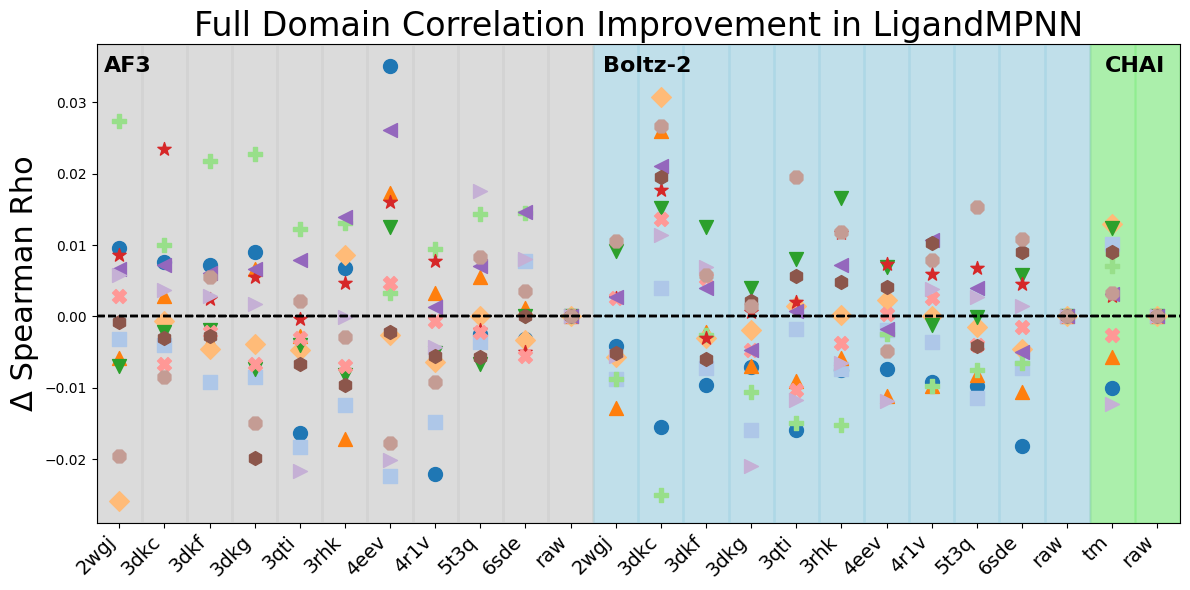

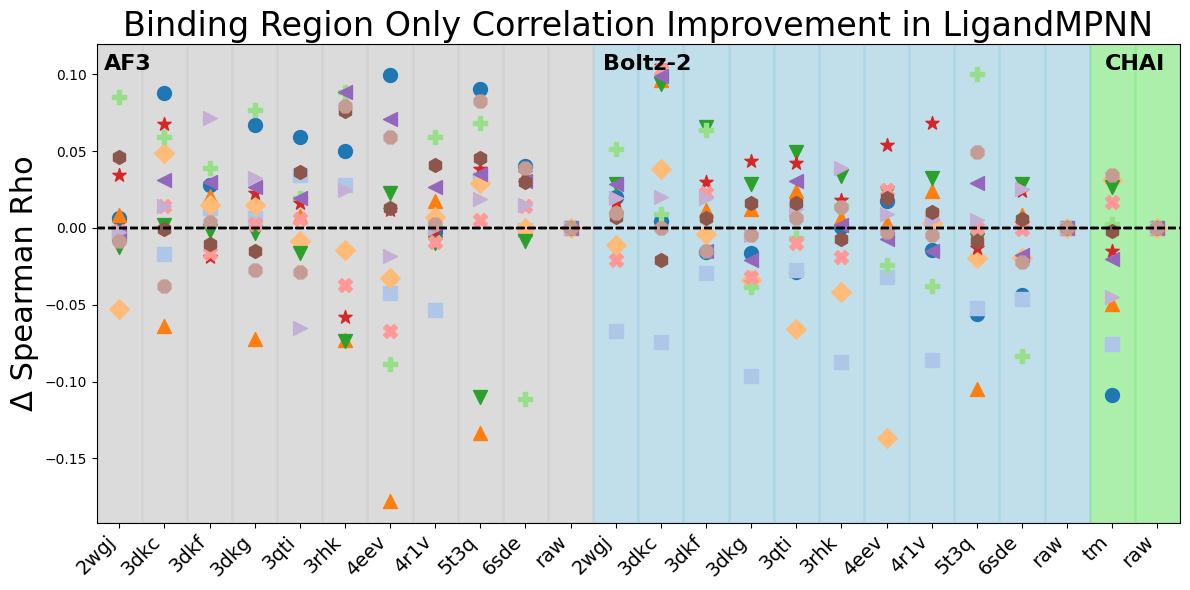

In [21]:
# ignore warnings
import warnings
warnings.filterwarnings("ignore")

df2 = pd.read_csv('../../MET_af3_models_struc_mpnn.csv')

exps = ['af3_3dkg', 'af3_raw',
       'af3_3rhk', 'boltz_5t3q', 'boltz_6sde', 'boltz_4eev', 'boltz_4r1v',
       'chai_tm', 'boltz_3dkf', 'boltz_raw', 'af3_3qti', 'af3_2wgj',
       'af3_3dkc', 'chai_raw', 'boltz_2wgj', 'boltz_3qti', 'boltz_3dkc',
       'af3_3dkf', 'boltz_3rhk', 'af3_4r1v', 'af3_6sde', 'af3_5t3q',
       'af3_4eev', 'boltz_3dkg']

exps = np.sort(exps)
# swap chai_tm and chai_raw
exps = list(exps)
chai_tm_index = exps.index('chai_tm')
chai_raw_index = exps.index('chai_raw')
exps[chai_tm_index], exps[chai_raw_index] = exps[chai_raw_index], exps[chai_tm_index]
exps = np.array(exps)

fig, ax = plt.subplots(figsize=(12,6))
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', '<', '>', 'h', '8']
colors = plt.cm.tab20.colors
num_col = len(exps)
for key in df2['key'].unique():
    key_df = df2[df2['key'].isin([key])]

    # spearmanr correlation of each column
    corrs = {}
    baseline_corr = {}
    for col in exps:

        corr, _ = spearmanr(key_df['mean'], key_df[col])
        corrs[col] = corr
        if 'raw' in col:
            baseline_corr[col.split('_')[0]] = corr

    for k,v in corrs.items():
        corrs[k] = v - baseline_corr[k.split('_')[0]]

    # make scatter plot and 
    ax.scatter(range(num_col), [corrs[e] for e in exps], label=key if key != 'Camp' else 'Cap', marker=markers[list(df2['key'].unique()).index(key)%len(markers)], s=100, color=colors[list(df2['key'].unique()).index(key)%len(colors)])

    # set background color for scatter plot who has different prefix label in exps
    for i, e in enumerate(exps):
        if 'af3' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgrey', alpha=0.1, zorder=0)
        elif 'boltz' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightblue', alpha=0.1, zorder=0)
        elif 'chai' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgreen', alpha=0.1, zorder=0)
        else:
            raise ValueError('Unknown experiment type in exps')

    ax.axhline(y=0, color='black', linestyle='--')
    ax.set_xticks(ticks=range(num_col))
    ax.set_xticklabels([e.split('_')[1] for e in exps], rotation=45, ha='right', fontsize=14)
    ax.set_xlim(-0.5, num_col-0.5)

# text label indicating different experiment groups
ax.text(0.2, ax.get_ylim()[1]*0.9, 'AF3', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(11.7, ax.get_ylim()[1]*0.9, 'Boltz-2', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(22.5, ax.get_ylim()[1]*0.9, 'CHAI', fontsize=16, color='black', ha='center', fontweight='bold')
ax.set_ylabel('Δ Spearman Rho', fontsize=22)
plt.title('Full Domain Correlation Improvement in LigandMPNN', fontsize=24)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(12,6))
num_col = len(exps)
for key in df2['key'].unique():
    key_df = df2[df2['key'].isin([key]) & (df2['binding_region_label'])]

    # spearmanr correlation of each column
    corrs = {}
    baseline_corr = {}
    for col in exps:

        corr, _ = spearmanr(key_df['mean'], key_df[col])
        corrs[col] = corr
        if 'raw' in col:
            baseline_corr[col.split('_')[0]] = corr

    for k,v in corrs.items():
        corrs[k] = v - baseline_corr[k.split('_')[0]]

    # make scatter plot and 
    ax.scatter(range(num_col), [corrs[e] for e in exps], label=key if key != 'Camp' else 'Cap', marker=markers[list(df2['key'].unique()).index(key)%len(markers)], s=100, color=colors[list(df2['key'].unique()).index(key)%len(colors)])

    # set background color for scatter plot who has different prefix label in exps
    for i, e in enumerate(exps):
        if 'af3' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgrey', alpha=0.1, zorder=0)
        elif 'boltz' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightblue', alpha=0.1, zorder=0)
        elif 'chai' in e:
            ax.axvspan(i-0.5, i+0.5, color='lightgreen', alpha=0.1, zorder=0)
        else:
            raise ValueError('Unknown experiment type in exps')

    ax.axhline(y=0, color='black', linestyle='--')
    ax.set_xticks(ticks=range(num_col))
    ax.set_xticklabels([e.split('_')[1] for e in exps], rotation=45, ha='right', fontsize=14)
    ax.set_xlim(-0.5, num_col-0.5)

# text label indicating different experiment groups
ax.text(0.2, ax.get_ylim()[1]*0.86, 'AF3', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(11.7, ax.get_ylim()[1]*0.86, 'Boltz-2', fontsize=16, color='black', ha='center', fontweight='bold')
ax.text(22.5, ax.get_ylim()[1]*0.86, 'CHAI', fontsize=16, color='black', ha='center', fontweight='bold')
ax.set_ylabel('Δ Spearman Rho', fontsize=22)
plt.title('Binding Region Only Correlation Improvement in LigandMPNN', fontsize=24)
plt.tight_layout()


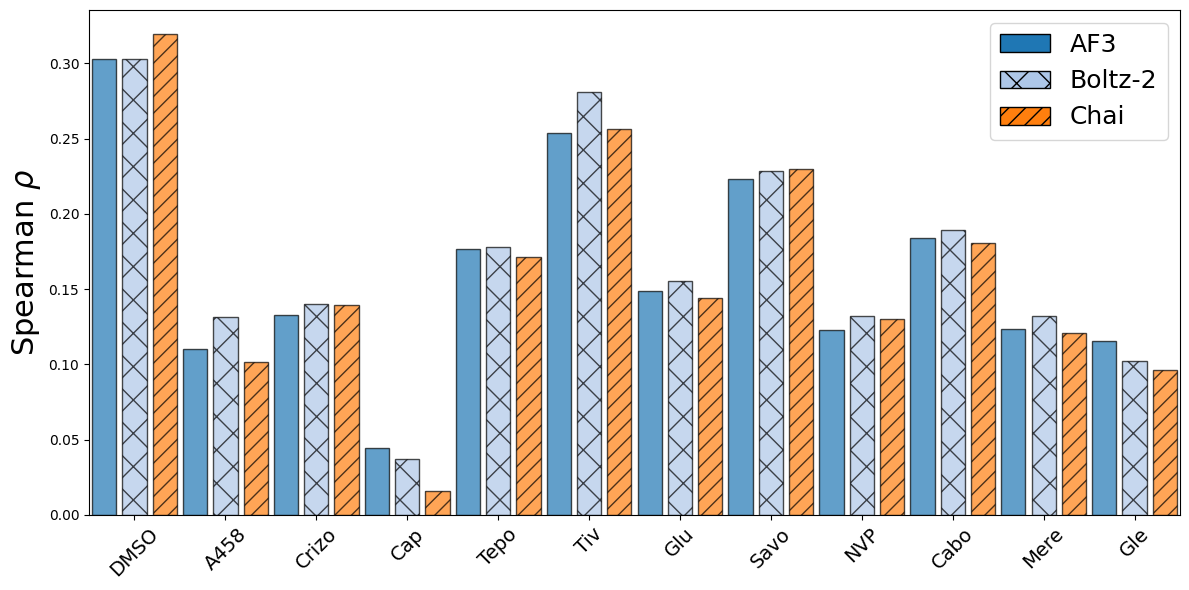

In [22]:
df2 = pd.read_csv('../../MET_af3_models_struc_mpnn.csv')

exps = np.sort(exps)
# swap chai_tm and chai_raw
exps = list(exps)
chai_tm_index = exps.index('chai_tm')
chai_raw_index = exps.index('chai_raw')
exps[chai_tm_index], exps[chai_raw_index] = exps[chai_raw_index], exps[chai_tm_index]
exps = np.array(exps)

fig, ax = plt.subplots(figsize=(12,6))
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', '<', '>', 'h', '8']
colors = plt.cm.tab20.colors
num_col = len(exps)

for i, key in enumerate(df2['key'].unique()):
    key_df = df2[df2['key'].isin([key])]

    # spearmanr correlation of each column
    corrs = {}
    for col in exps:
        if 'raw' not in col:
            continue
        corr, _ = spearmanr(key_df['mean'], key_df[col])
        corrs[col] = corr

    # make bar plot 
    ax.bar(range(i*len(corrs), i*len(corrs)+len(corrs)), [corrs[e] for e in corrs.keys()], label=key if key != 'Camp' else 'Cap', alpha=0.7, color=colors[0:3], hatch=['', 'x', '//'], edgecolor='black')

ax.set_ylabel('Spearman $\\rho$', fontsize=22)
plt.xticks(ticks=[i*len(corrs) + len(corrs)/2 - 0.5 for i in range(len(df2['key'].unique()))], labels=[k if k != 'Camp' else 'Cap' for k in df2['key'].unique()], rotation=45, ha='center', fontsize=14)
plt.xlim(-0.5, len(df2['key'].unique())*len(corrs)-0.5)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=18)

# set first legend for different experiment groups
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors[0], hatch='', edgecolor='black', label='AF3'),
                   Patch(facecolor=colors[1], hatch='x', edgecolor='black', label='Boltz-2'),
                   Patch(facecolor=colors[2], hatch='//', edgecolor='black', label='Chai')]
ax.legend(handles=legend_elements, loc='upper right', fontsize=18)

plt.tight_layout()


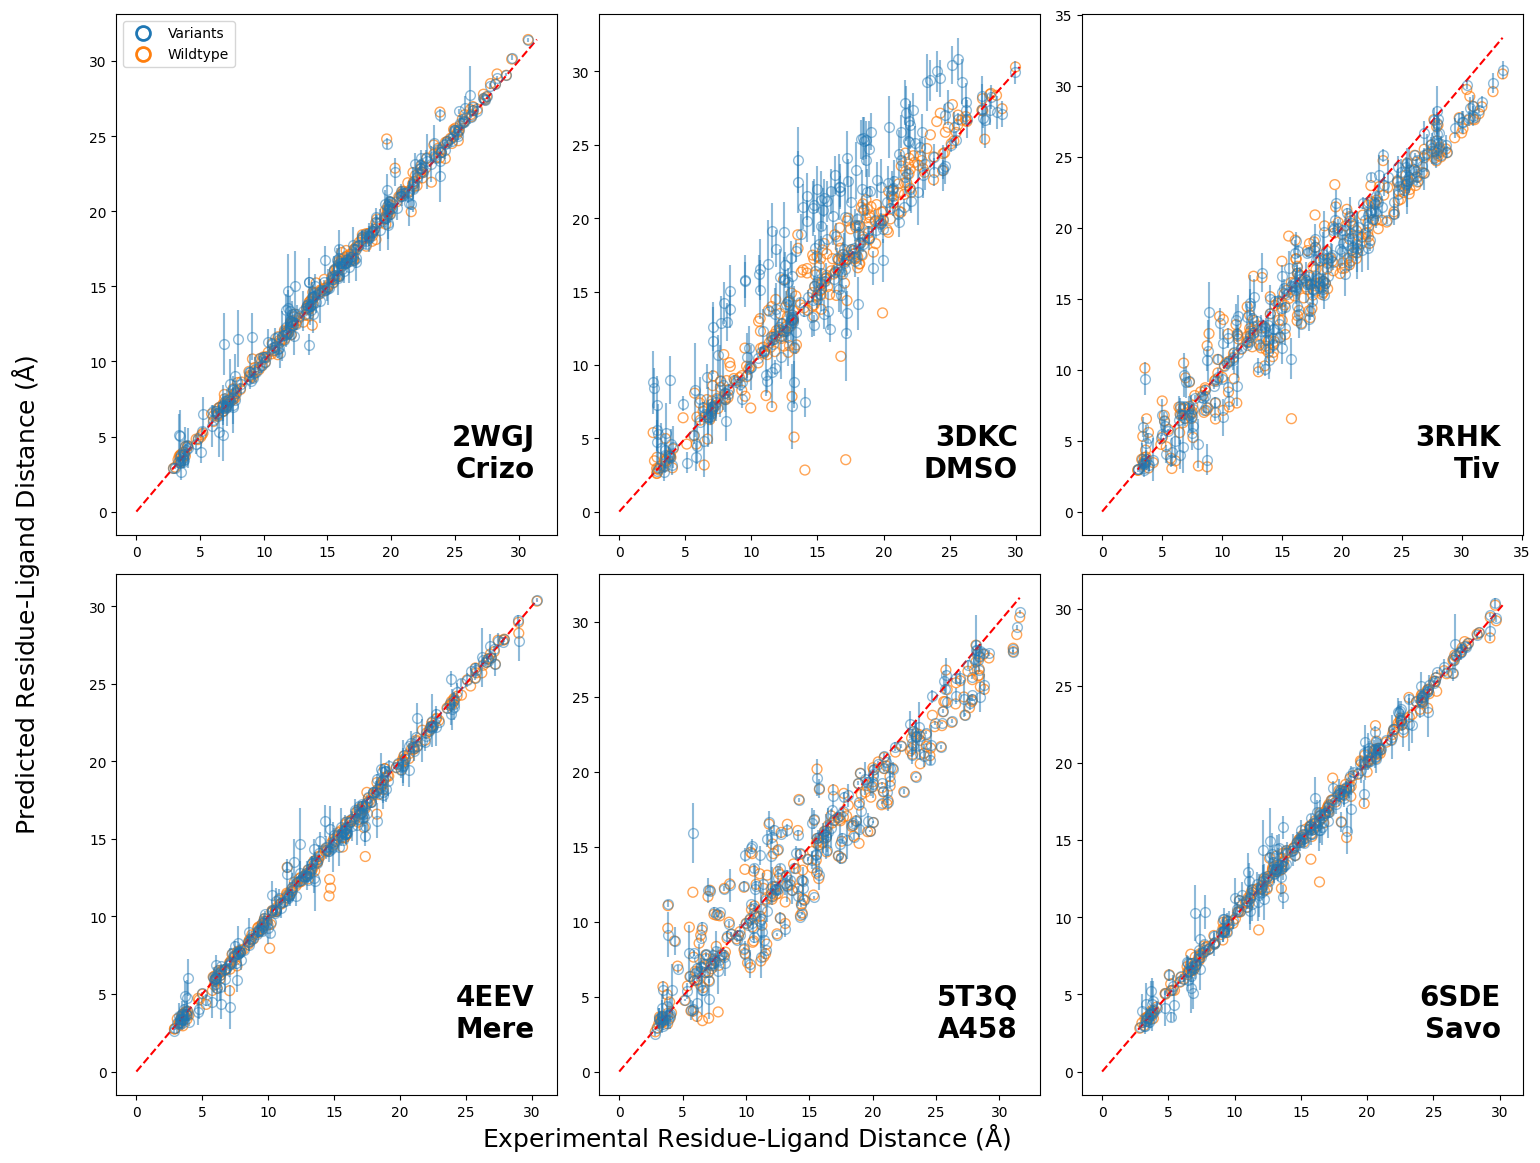

In [45]:
from matplotlib.lines import Line2D
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.Data.IUPACData import protein_letters_3to1_extended

# experimental crystal key -> ligand label
label_list = {'2wgj_crizo': 'Crizo', '3dkc': 'DMSO', '3rhk_tiv': 'Tiv',
              '4eev_mere': 'Mere', '5t3q_A458': 'A458', '6sde_savo': 'Savo'}

BOLTZ = '../../boltz-2'
PRED  = f'{BOLTZ}/boltz_results_met_affinity_combined/predictions'          # mutants
WTDIR = f'{BOLTZ}/boltz_results_met_inputs_steer/predictions'               # wildtype

# --- crystal numbering -> predicted 1-287 by CA-sequence alignment -----------
_al = PairwiseAligner(); _al.mode = 'global'
_al.substitution_matrix = substitution_matrices.load('BLOSUM62')
_al.open_gap_score, _al.extend_gap_score = -10, -0.5

def _one(resname):
    return protein_letters_3to1_extended.get(str(resname).capitalize(), 'X')

def _seq_from_dist(df):
    """(resi list, 1-letter seq) from a *_residue_ligand_distance.csv (sorted by resi)."""
    d = df.sort_values('resi')
    return d['resi'].tolist(), ''.join(_one(r) for r in d['resname'])

def map_cryst_to_pred(exp_df, pred_df):
    """{crystal resi -> predicted resi 1-287} via global alignment (handles indels)."""
    er, es = _seq_from_dist(exp_df); pr, ps = _seq_from_dist(pred_df)
    aln = _al.align(es, ps)[0]
    i = j = 0; mp = {}
    for ec, pc in zip(aln[0], aln[1]):
        if ec != '-' and pc != '-': mp[er[i]] = pr[j]
        if ec != '-': i += 1
        if pc != '-': j += 1
    return mp

# ---------------------------------------------------------------------------
fig, axs = plt.subplots(2, 3, figsize=(16, 12))
colors = ['#1f77b4', '#ff7f0e']

for k, (lname, lig) in enumerate(label_list.items()):
    ax = axs[k // 3, k % 3]

    # experimental (crystal) residue-ligand distances
    exp = pd.read_csv(f'{BOLTZ}/{lname}_residue_ligand_distance.csv')

    # wildtype prediction (Mg-steered file for DMSO)
    wt_path = (f'{WTDIR}/MET_{lig}_MG/MET_{lig}_MG_model_0_residue_ligand_distance.csv'
               if lig == 'DMSO' else
               f'{WTDIR}/MET_{lig}/MET_{lig}_model_0_residue_ligand_distance.csv')
    wt = pd.read_csv(wt_path)

    # map crystal numbering onto predicted 1-287 (alignment, not a fixed -1058)
    cmap = map_cryst_to_pred(exp, wt)
    exp = exp.assign(pos=exp['resi'].map(cmap)).dropna(subset=['pos'])
    exp['pos'] = exp['pos'].astype(int)
    exp = exp.rename(columns={'min_distance_to_ligand': 'exp_dist'})[['pos', 'exp_dist']]
    wt  = wt.rename(columns={'resi': 'pos',
                             'min_distance_to_ligand': 'wt_dist'})[['pos', 'wt_dist']]

    # mutant mean/std per position: average that residue's distance over its ~19 substitutions
    rows = []
    for pos in wt['pos']:
        dists = []
        # anchored glob: {lig}_{pos}[A-Z] matches e.g. Crizo_49A but NOT Crizo_490A / Crizo_4A
        for fn in glob.glob(f'{PRED}/{lig}_{pos}[A-Z]/{lig}_{pos}[A-Z]_model_0_residue_ligand_distance.csv'):
            mdf = pd.read_csv(fn)
            v = mdf.loc[mdf['resi'] == pos, 'min_distance_to_ligand'].values
            if len(v):
                dists.append(v[0])
        if dists:
            rows.append((pos, np.mean(dists), np.std(dists)))
    mut = pd.DataFrame(rows, columns=['pos', 'mut_mean', 'mut_std'])

    # join everything on residue position (no positional [idx_list] indexing)
    m = (exp.merge(wt, on='pos')
            .merge(mut, on='pos', how='left')
            .sort_values('exp_dist'))

    ax.errorbar(m['exp_dist'], m['mut_mean'], yerr=m['mut_std'], fmt='o', alpha=0.5,
                capsize=0, markerfacecolor='none', markersize=7,
                markeredgecolor=colors[0], label='Variants')
    ax.scatter(m['exp_dist'], m['wt_dist'], alpha=0.7, facecolors='none',
               edgecolors=colors[1], s=50, label='Wildtype')

    hi = float(np.nanmax([m['exp_dist'].max(), m['wt_dist'].max()]))
    ax.plot([0, hi], [0, hi], 'r--')
    ax.text(0.95, 0.10, f'{lname.split("_")[0].upper()}\n{label_list[lname]}', transform=ax.transAxes,
            fontsize=20, va='bottom', ha='right', fontweight='bold')
    if k == 0:
        ax.legend(handles=[
            Line2D([0], [0], marker='o', color='w', label='Variants',
                   markerfacecolor='none', markeredgecolor=colors[0], markersize=10, markeredgewidth=2),
            Line2D([0], [0], marker='o', color='w', label='Wildtype',
                   markerfacecolor='none', markeredgecolor=colors[1], markersize=10, markeredgewidth=2)])

fig.text(0.5, 0.04, 'Experimental Residue-Ligand Distance ($\\mathrm{\\AA}$)', ha='center', fontsize=18)
fig.text(0.04, 0.5, 'Predicted Residue-Ligand Distance ($\\mathrm{\\AA}$)', va='center', rotation='vertical', fontsize=18)
plt.tight_layout(rect=[0.08, 0.05, 1, 1])
plt.show()


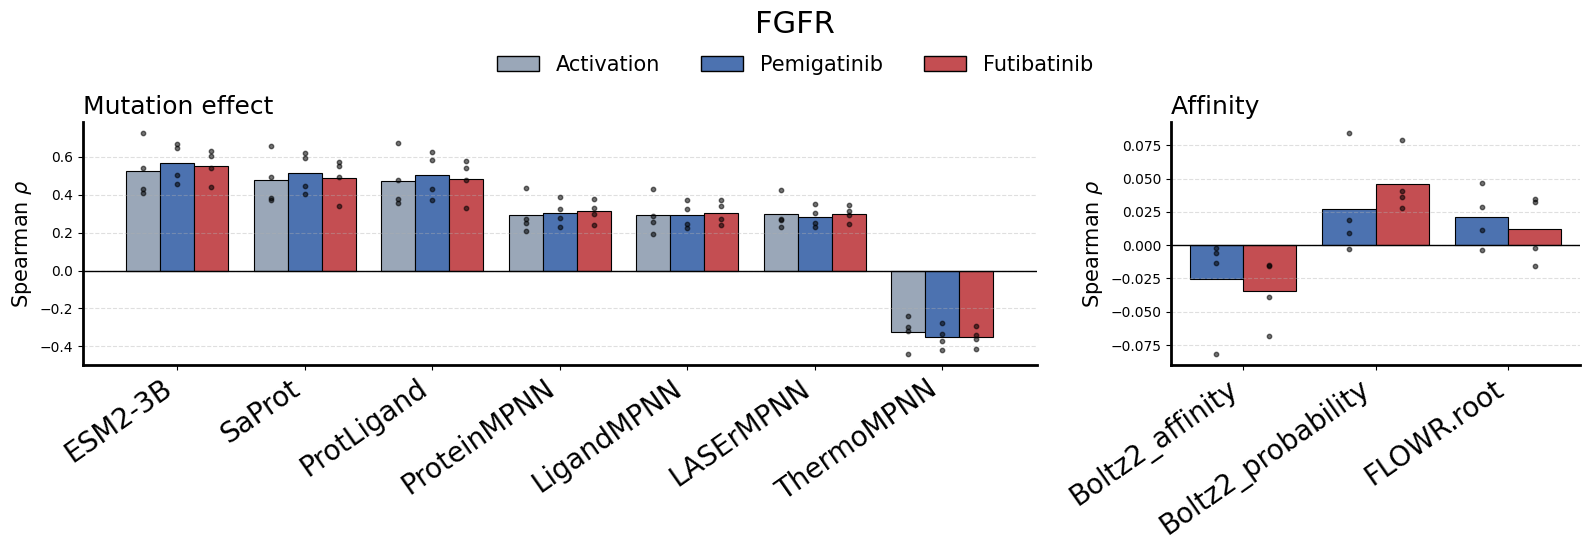

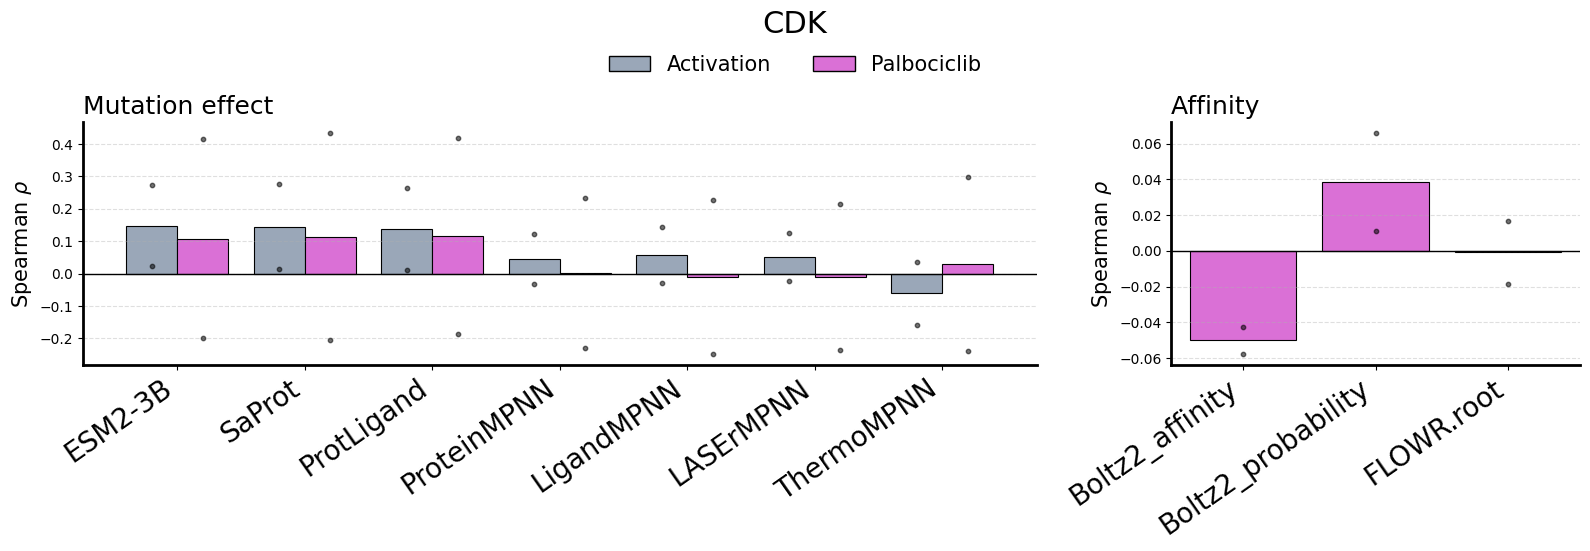

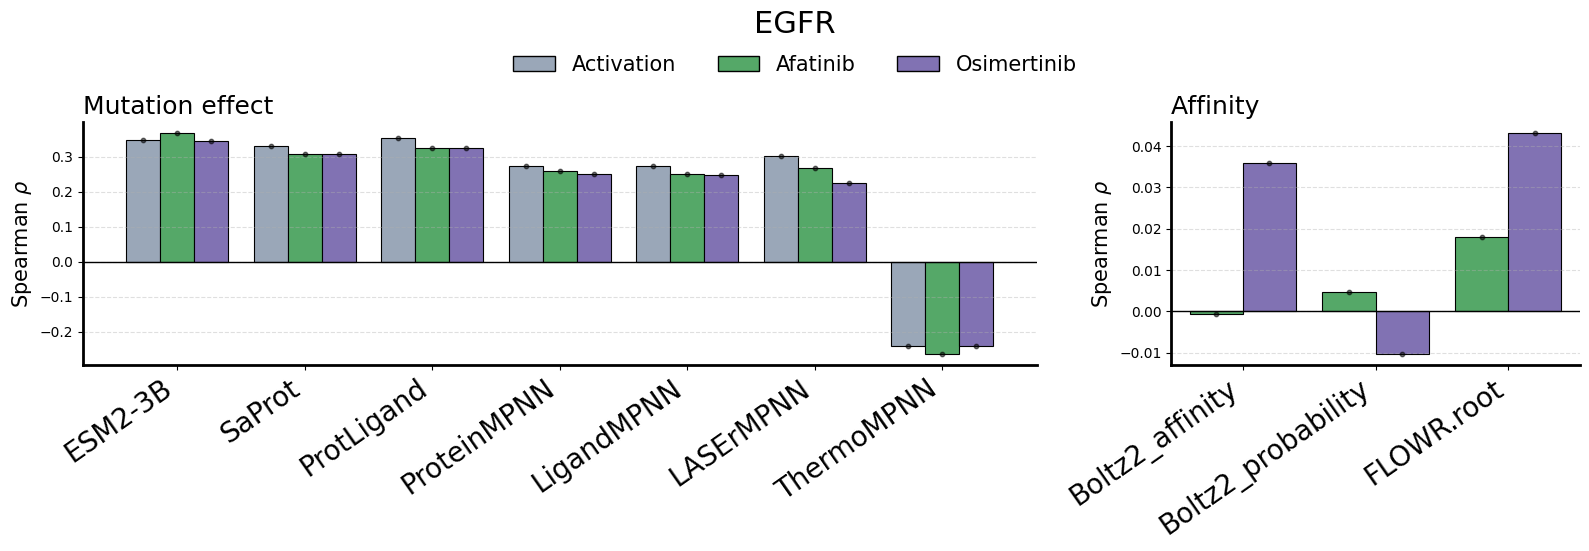

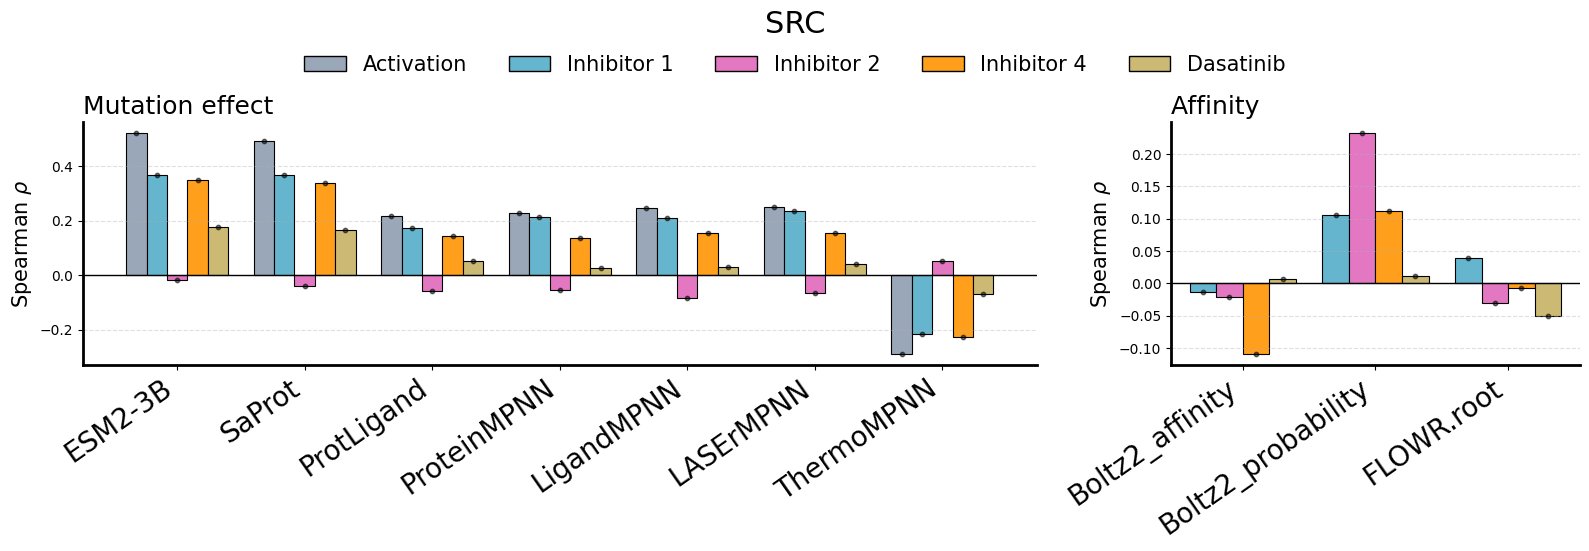

In [28]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import re

FILESS = [['../kinases/FGFR.csv'],
          ['../kinases/CDK4.csv',
           '../kinases/CDK6.csv'],
           ['../kinases/EGFR.csv'],
           ['../kinases/SRC.csv']]

for FILES in FILESS:

    df = pd.concat([pd.read_csv(f) for f in FILES], join='inner', ignore_index=True)

    EXP = next(c for c in ['score', 'lfc'] if c in df.columns)
    INNER = 'prot' if df['prot'].nunique() > 1 else None
    TREATS = list(df['key'].unique())
    TREATS = (['DMSO'] if 'DMSO' in TREATS else []) + [k for k in TREATS if k != 'DMSO']
    DRUG_TREATS = [k for k in TREATS if k != 'DMSO']

    # short key -> full inhibitor name (DMSO shown as the activation/baseline)
    KEY_LABEL = {'DMSO': 'Activation', 'Pem': 'Pemigatinib', 'Fut': 'Futibatinib',
                'Afa': 'Afatinib', 'Osi': 'Osimertinib', 'Das': 'Dasatinib',
                'Inhib1': 'Inhibitor 1', 'Inhib2': 'Inhibitor 2', 'Inhib4': 'Inhibitor 4',
                'Pal': 'Palbociclib'}
    treat_colors = {'DMSO': '#9AA7B8', 'Pem': '#4C72B0', 'Fut': '#C44E52', 'Afa': '#55A868',
                    'Osi': '#8172B3', 'Das': '#CCB974', 'Inhib1': '#64B5CD', 'Inhib2': '#E377C2',
                    'Inhib4': '#FF9F1C', 'Pal': '#DA70D6'}

    MUT_SPEC = [
        ('ESM2-3B',     ['ESM23B_mut']),
        ('SaProt',      ['Saprot_mut']),
        ('ProtLigand',  ['ProtLigand_mut']),
        ('ProteinMPNN', ['ProteinMPNN_mut']),
        ('LigandMPNN',  ['LigandMPNN_mut']),
        ('LASErMPNN',   ['LASErMPNN_mut']),
        ('ThermoMPNN',  ['ThermoMPNN_mut']),
    ]
    AFF_SPEC = [
        ('Boltz2_affinity',      ['Boltz2_affinity']),
        ('Boltz2_probability', ['Boltz2_prob', 'Boltz2_affinity_probability']),
        ('FLOWR.root',       ['flowr_affinity']),
    ]

    # d_fitness = fit_dmso - fit_ligand, per (paralog, variant)
    base = df[df['key'] == 'DMSO'].groupby(['prot', 'variants'])[EXP].mean()
    df['d_fitness'] = [base.get(k, np.nan) for k in zip(df['prot'], df['variants'])] - df[EXP]

    def resolve(spec):
        out = []
        for label, cands in spec:
            col = next((c for c in cands if c in df.columns), None)
            if col is not None: out.append((label, col))
        return out

    def rho(sub, col, target):
        x, y = sub[target].values, sub[col].values
        m = np.isfinite(x) & np.isfinite(y)
        return spearmanr(x[m], y[m]).correlation if m.sum() >= 3 else np.nan

    def rho_by_treat(col, key, target):
        sub = df[df['key'] == key]
        if INNER is None:
            r = rho(sub, col, target); return [r] if np.isfinite(r) else []
        rr = [rho(g, col, target) for _, g in sub.groupby(INNER)]
        return [r for r in rr if np.isfinite(r)]

    def draw(ax, items, title, target, treats):
        n = len(treats); width = 0.8 / n
        x = np.arange(len(items))
        for j, key in enumerate(treats):
            off = (j - (n - 1) / 2) * width
            means = [np.mean(rho_by_treat(c, key, target)) if rho_by_treat(c, key, target) else np.nan
                    for _, c in items]
            ax.bar(x + off, means, width, color=treat_colors.get(key, f'C{j}'),
                edgecolor='black', lw=0.8)
            for i, (_, c) in enumerate(items):
                rr = rho_by_treat(c, key, target)
                ax.scatter(np.full(len(rr), x[i] + off), rr, color='black', s=10, alpha=0.55, zorder=3)
        ax.axhline(0, color='black', lw=1)
        ax.set_xticks(x); ax.set_xticklabels([l for l, _ in items], rotation=35, ha='right', fontsize=20)
        ax.set_ylabel('Spearman $\\rho$', fontsize=15)
        ax.set_title(title, fontsize=18, loc='left')
        ax.grid(axis='y', ls='--', alpha=0.4)
        for s in ['top', 'right']: ax.spines[s].set_visible(False)
        for s in ['bottom', 'left']: ax.spines[s].set_linewidth(2)

    mut_items, aff_items = resolve(MUT_SPEC), resolve(AFF_SPEC)
    fig, axs = plt.subplots(1, 2, figsize=(16, 5.2),
                            gridspec_kw={'width_ratios': [max(len(mut_items),1), max(len(aff_items),1)]})
    draw(axs[0], mut_items, 'Mutation effect', EXP, TREATS)
    draw(axs[1], aff_items, 'Affinity ', 'd_fitness', DRUG_TREATS)

    # shared legend with full inhibitor names
    handles = [plt.Rectangle((0, 0), 1, 1, color=treat_colors.get(k, f'C{j}'), ec='black')
            for j, k in enumerate(TREATS)]
    labels = [KEY_LABEL.get(k, k) for k in TREATS]
    fig.legend(handles, labels, loc='upper center', ncol=len(TREATS),
            frameon=False, fontsize=15, bbox_to_anchor=(0.5, 1.0))
    family = ','.join(sorted({re.sub(r'\d+$', '', p) for p in df['prot'].unique()}))
    fig.suptitle(family, fontsize=22, x=0.5, y=1.05)
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_2139058/1535393523.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct = (sub.groupby(['pair', 'dbin']).size().unstack(fill_value=0)


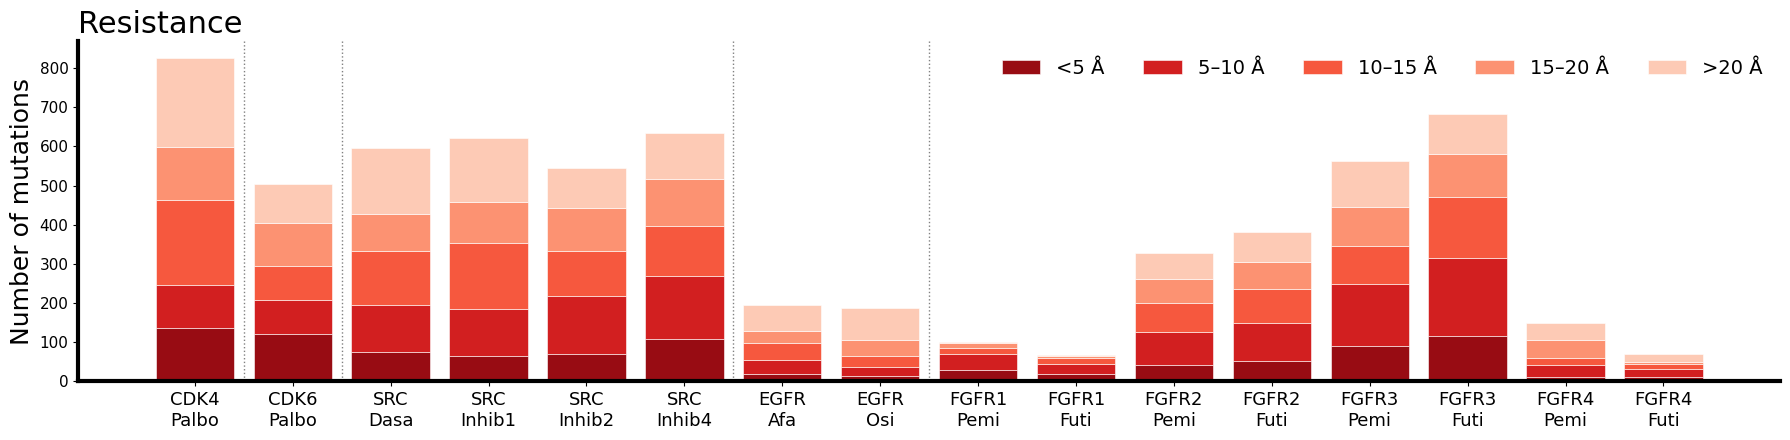

In [6]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

FILES = ['CDK4', 'CDK6', 'SRC', 'EGFR', 'FGFR']
parts = []
for f in FILES:
    d = pd.read_csv(f'../kinases/{f}.csv')
    parts.append(d[['prot', 'key', 'min_dist', 'label_sensitized', 'label_resisted']])
df = pd.concat(parts, ignore_index=True)
df = df[df['key'] != 'DMSO'].copy()          # baseline has no drug-specific labels
df['pair'] = df['prot'].astype(str) + '/' + df['key'].astype(str)

# distance shells
EDGES = [0, 5, 10, 15, 20, np.inf]
LABELS = ['<5 Å', '5–10 Å', '10–15 Å', '15–20 Å', '>20 Å']
df['dbin'] = pd.cut(df['min_dist'], bins=EDGES, labels=LABELS, right=False)

# pair order: family blocks, drugs within
ORDER = ['CDK4/Pal', 'CDK6/Pal',
         'SRC/Das', 'SRC/Inhib1', 'SRC/Inhib2', 'SRC/Inhib4',
         'EGFR/Afa', 'EGFR/Osi',
         'FGFR1/Pem', 'FGFR1/Fut', 'FGFR2/Pem', 'FGFR2/Fut',
         'FGFR3/Pem', 'FGFR3/Fut', 'FGFR4/Pem', 'FGFR4/Fut']
pairs = [p for p in ORDER if p in set(df['pair'])]

# pretty x labels (short inhibitor names)
SHORT = {'Pal':'Palbo','Das':'Dasa','Inhib1':'Inhib1','Inhib2':'Inhib2','Inhib4':'Inhib4',
         'Afa':'Afa','Osi':'Osi','Pem':'Pemi','Fut':'Futi'}
xlab = [f"{p.split('/')[0]}\n{SHORT.get(p.split('/')[1], p.split('/')[1])}" for p in pairs]

res_colors = plt.cm.Reds(np.linspace(0.9, 0.2, len(LABELS)))
sen_colors = plt.cm.Blues(np.linspace(0.9, 0.2, len(LABELS)))
panels = [
          ('Resistance', 'label_resisted', res_colors)]

fig, ax = plt.subplots(1, 1, figsize=(18, 4.5), sharex=True)
x = np.arange(len(pairs))
for (name, col, cols) in  panels:
    sub = df[df[col].astype(bool)]
    ct = (sub.groupby(['pair', 'dbin']).size().unstack(fill_value=0)
             .reindex(index=pairs, columns=LABELS, fill_value=0))
    bottom = np.zeros(len(pairs))
    for j, lab in enumerate(LABELS):
        ax.bar(x, ct[lab].values, bottom=bottom, color=cols[j],
               edgecolor='white', lw=0.4, label=lab)
        bottom += ct[lab].values
    ax.set_ylabel('Number of mutations', fontsize=18)
    ax.set_title(name, fontsize=22, loc='left')
    ax.tick_params(axis='y', labelsize=11)
    ax.legend(frameon=False, fontsize=14, loc='upper right', ncol=5)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    for s in ['bottom', 'left']: ax.spines[s].set_linewidth(3)

# family separators (vertical lines between kinase blocks)
fams = [p.split('/')[0].rstrip('1234') for p in pairs]
for i in range(1, len(pairs)):
    if fams[i] != fams[i-1]:
        ax.axvline(i - 0.5, color='grey', ls=':', lw=1)

ax.set_xticks(x)
ax.set_xticklabels(xlab, fontsize=13)
plt.tight_layout()
plt.show()
